# 팀 프로젝트 셀

In [21]:
# ===== 팀 프로젝트 시작 셀 =====
import os, sys
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
NAME = "Daun"
REPO_URL = "github.com/DA15-Lab/team3-ping-analytics.git"
PROJECT_DIR = "/content/team3-ping-analytics"

if not os.path.exists(PROJECT_DIR):
    !git clone -q https://{TOKEN}@{REPO_URL}
    %cd {PROJECT_DIR}
else:
    %cd {PROJECT_DIR}
    !git pull -q

!git config user.email "{NAME}@example.com"
!git config user.name "{NAME}"

!pip install -q -r requirements.txt

sys.path.append("/content/team3-ping-analytics/src")
from preprocessing import *

print(module_test())
print("✅ 준비 완료")

/content/team3-ping-analytics
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 38.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.3/190.3 MB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 341.3/341.3 kB 7.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 19.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 41.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 80.3 MB/s eta 0:00:00
✅ 모듈 설치 완료
✅ 준비 완료


In [ ]:
# ===== 작업 저장 셀 =====
NAME = "Daun"
PROJECT_DIR = "/content/team3-ping-analytics"

%cd {PROJECT_DIR}
!git config pull.rebase false
!git config core.editor "true"

!git pull
!pip install -q -r requirements.txt

from google.colab import _message
import json

with open(f'notebooks/{NAME}_analysis.ipynb', 'w') as f:
    json.dump(_message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'], f)

!pip freeze | grep -v "google-colab" > requirements.txt

!git add .
!git commit -m "대주제 2 마무리"
!git push

/content/team3-ping-analytics
Already up to date.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 59.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


# 모듈 테스트용

In [3]:
# 캐시 리셋

import importlib
import preprocessing
importlib.reload(preprocessing)
from preprocessing import *

# 분석 시작

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as px

import os
import ast

from scipy.stats import chi2_contingency
from scipy.stats import spearmanr

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# 지수 표기법 대신 소수점 2자리까지 표기
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 테이블 출력 시 컬럼 모두 나오게 하기
pd.set_option('display.max_columns', 100)

# 시각화 지수 표기법 사용하지 않기
plt.rcParams['axes.formatter.useoffset'] = False
plt.rcParams['axes.formatter.limits'] = (-10, 10)

# 시각화 한글 폰트 출력
import matplotlib.font_manager as fm
import platform
import urllib.request

system_name = platform.system()

if system_name == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif system_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
else:  # Linux / Colab
    font_path = 'NanumGothic.ttf'
    if not os.path.exists(font_path):
        url = "https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf"
        urllib.request.urlretrieve(url, font_path)
    fm.fontManager.addfont(font_path)
    plt.rc('font', family='NanumGothic')

plt.rcParams['axes.unicode_minus'] = False

# 함수 정의

In [6]:
# 필요하다면 기재

# 전처리

## accounts_paymenthistory

In [6]:
def open_csv(table_name):
  folder_path = '/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv'
  file_path = os.path.join(folder_path, f'{table_name}.csv')
  return pd.read_csv(file_path)

df = open_csv('accounts_paymenthistory')
df.head()

,id,productId,phone_type,created_at,user_id
0,6,heart.777,A,2023-05-13 21:28:34,1211127
1,7,heart.777,A,2023-05-13 21:29:39,1151343
2,8,heart.777,A,2023-05-13 21:31:33,1002147
3,9,heart.777,A,2023-05-13 21:31:39,1095040
4,11,heart.777,A,2023-05-13 21:34:32,1164081


In [8]:
# 데이터 타입 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95140 entries, 0 to 95139
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          95140 non-null  int64 
 1   productId   95140 non-null  object
 2   phone_type  95140 non-null  object
 3   created_at  95140 non-null  object
 4   user_id     95140 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 3.6+ MB


In [9]:
# created_at: object -> datetime
df['created_at'] = pd.to_datetime(df['created_at'])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95140 entries, 0 to 95139
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   id          95140 non-null  int64         
 1   productId   95140 non-null  object        
 2   phone_type  95140 non-null  object        
 3   created_at  95140 non-null  datetime64[ns]
 4   user_id     95140 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 3.6+ MB


In [10]:
# 중복값 및 결측값 확인

def check_dup_and_na(df, id):
  print(f'행 중복 수: {df.duplicated().sum()}')
  print(f'id 중복 수: {df[id].duplicated().sum()}')
  print('')
  print('--- 컬럼별 결측 수 ---')
  display(df.isna().sum())


check_dup_and_na(df, 'id')

행 중복 수: 0
id 중복 수: 0

--- 컬럼별 결측 수 ---


,0
id,0
productId,0
phone_type,0
created_at,0
user_id,0


In [11]:
# id를 제외한 행의 중복값 재확인
dups = df.drop(columns='id').duplicated().sum()
dups_df = df[df.drop(columns='id').duplicated(keep=False)].sort_values(by='created_at')

# 전체 행 중 비율
print(f'전체 행 중 비율: {(dups / len(df)):.2%}')
dups_df

전체 행 중 비율: 0.56%


,id,productId,phone_type,created_at,user_id
30912,31938,heart.200,I,2023-05-17 13:46:11,1293409
30913,31939,heart.200,I,2023-05-17 13:46:11,1293409
35058,36213,heart.1000,I,2023-05-18 13:45:36,979577
35059,36214,heart.1000,I,2023-05-18 13:45:36,979577
90093,92999,heart.1000,I,2023-07-11 05:04:19,1556526
...,...,...,...,...,...
95132,98071,heart.777,I,2024-05-06 05:19:14,1398516
95134,98073,heart.777,I,2024-05-06 14:51:27,1086654
95135,98074,heart.777,I,2024-05-06 14:51:27,1086654
95138,98077,heart.1000,I,2024-05-08 14:12:45,1163480


> **중복값 처리**
* accounts_paymenthistory 테이블에서 id를 제외한 컬럼에서 중복값 **총 531행**

* 중복·중복아님 결정을 위해 다른 테이블과 교차 확인
  * `accounts_pointhistory`: 무료 포인트만 반영되는 듯함. 구매한 heart는 반영 안 됨
  * `accounts_failpaymenthistory`: 테이블에서 결제 실패 기록도 살펴봤지만, paymenthistory에서 중복된 행이 결제 실패 기록에는 없음
-> 중복값이라고 판별할만한 근거를 찾지 못함

* 가설
  * 한 번 구매할 때 한 상품 여러 개를 구매할 수 있다. -> 보존
  * 단순 기록 오류다 -> 삭제

* 결론
와이어프레임에서는 한 번 구매 시 한 상품 여러개를 구매할 수 있다는 표기가 없고, 중복 행의 수도 전체의 0.56% 수준으로 낮아 삭제 처리

In [12]:
ap_cleaned = df.drop_duplicates(subset=df.columns.difference(['id']), keep='first')

print(f'삭제 전 행 수: {len(df)}')
print(f'삭제 후 행 수: {len(ap_cleaned)}')
print(f'삭제된 행 수: {len(df) - len(ap_cleaned)}')

# 제대로 지워졌는지 재확인
ap_cleaned.drop(columns='id').duplicated().sum()

삭제 전 행 수: 95140
삭제 후 행 수: 94609
삭제된 행 수: 531


np.int64(0)

In [13]:
# 이상값 확인

def check_minmax(df, col):
  print(f'--- {col} minmax ---')
  print(f'MIN: {df[col].min()}')
  print(f'MAX: {df[col].max()}')
  print(f'행 수: {len(df)}')

def check_unique(df, col):
  print(f'--- {col} unique ---')
  print(df[col].unique())


minmax_cols = ['id', 'created_at', 'user_id']
for col in minmax_cols:
  check_minmax(ap_cleaned, col)
  print('')

unique_cols = ['productId', 'phone_type']
for col in unique_cols:
  check_unique(ap_cleaned, col)
  print('')

--- id minmax ---
MIN: 6
MAX: 98077
행 수: 94609

--- created_at minmax ---
MIN: 2023-05-13 21:28:34
MAX: 2024-05-08 14:12:45
행 수: 94609

--- user_id minmax ---
MIN: 833041
MAX: 1583632
행 수: 94609

--- productId unique ---
['heart.777' 'heart.200' 'heart.4000' 'heart.1000']

--- phone_type unique ---
['A' 'I']



`accounts_paymenthistory`의 id는 행 생성 시 순차적으로 숫자를 배정하는 것으로 보인다.  
테이블의 행 수보다 id의 최댓값이 큰데, id가 6부터 시작하는 등, 일부 데이터는 삭제된 것으로 보인다.  
따라서, 행 수보다 큰 id값은 이상치가 아니라고 판단하여 삭제하지 않도록 하겠다.

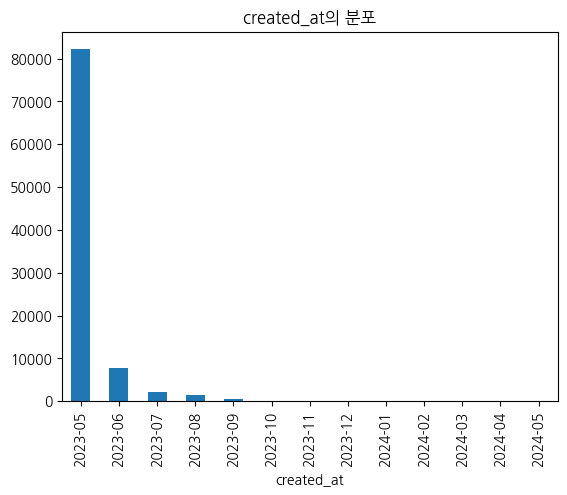

In [14]:
ap_cleaned['created_at'].dt.to_period('M').value_counts().sort_index().plot(kind='bar')
plt.title('created_at의 분포')
plt.show()

In [15]:
# 유저 테이블 accounts_user에 속하지 않은 user_id 찾기
# 속하지 않은 user_id는 이상값 처리

account_user = open_csv('accounts_user')
account_user.head()

,id,is_superuser,is_staff,gender,point,friend_id_list,is_push_on,created_at,block_user_id_list,hide_user_id_list,ban_status,report_count,alarm_count,pending_chat,pending_votes,group_id
0,831956,1,1,NaN,600,"[1292473, 913158, 1488461, 1064695, 1043565, 1...",0,2023-03-29 03:44:14.047130,[],[],N,0,0,0,0,NaN
1,831962,0,0,F,2248,"[833025, 832642, 982531, 879496, 838541, 83752...",1,2023-03-29 05:18:56.162368,[],[],N,253,40878,5499,110,12.00
2,832151,0,0,M,1519,"[838785, 982531, 882567, 879496, 838541, 83649...",0,2023-03-29 12:56:34.989468,[],[],N,0,37,0,47,1.00
3,832340,0,0,F,57,"[841345, 982531, 838785, 963714, 882567, 83252...",1,2023-03-29 12:56:35.020790,[],[],N,0,19,0,21,1.00
4,832520,0,0,M,1039,"[874050, 849763, 874212, 844297, 838541, 84004...",0,2023-03-29 12:56:35.049311,[],[],N,0,29,0,15,12.00


In [16]:
# account_user의 user_id에 속하지 않은 user_id 추출
def check_valid_user_id(df, col):
  # account_user의 user_id 추출
  user_ids = account_user['id']

  cond = df[col].isin(user_ids)
  print(f'account_user의 user_id에 속하지 않은 {col} 수: {len(df[~cond])}')
  print('')
  display(df[~cond])

check_valid_user_id(ap_cleaned, 'user_id')

account_user의 user_id에 속하지 않은 user_id 수: 0



,id,productId,phone_type,created_at,user_id


In [17]:
# # 공유 드라이브에 저장

# def save_to_drive(df, table_name):
#   ap_cleaned.to_csv(f'/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/01_전처리 완료된 csv/{table_name}.csv',
#                   index=False,
#                   encoding='utf-8-sig')
#   print('✅ 저장 완료!')

# save_to_drive(ap_cleaned, 'accounts_paymenthistory_cleaned')

## accounts_userquestionrecord

In [18]:
df = open_csv('accounts_userquestionrecord')
df.head()

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
0,771777,C,2023-04-28 12:27:49,849469,252,849436,998458,0,N,2023-04-28 12:27:49,0,0
1,771800,C,2023-04-28 12:28:02,849446,244,849436,998459,0,N,2023-04-28 12:28:02,0,0
2,771812,C,2023-04-28 12:28:09,849454,183,849436,998460,1,N,2023-04-28 12:28:09,0,0
3,771828,C,2023-04-28 12:28:16,847375,101,849436,998461,0,N,2023-04-28 12:28:16,0,0
4,771851,C,2023-04-28 12:28:26,849477,209,849436,998462,1,N,2023-04-28 12:28:26,0,0


In [19]:
df.columns

Index(['id', 'status', 'created_at', 'chosen_user_id', 'question_id',
       'user_id', 'question_piece_id', 'has_read', 'answer_status',
       'answer_updated_at', 'report_count', 'opened_times'],
      dtype='object')

In [20]:
# 데이터 타입 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1217558 entries, 0 to 1217557
Data columns (total 12 columns):
 #   Column             Non-Null Count    Dtype 
---  ------             --------------    ----- 
 0   id                 1217558 non-null  int64 
 1   status             1217558 non-null  object
 2   created_at         1217558 non-null  object
 3   chosen_user_id     1217558 non-null  int64 
 4   question_id        1217558 non-null  int64 
 5   user_id            1217558 non-null  int64 
 6   question_piece_id  1217558 non-null  int64 
 7   has_read           1217558 non-null  int64 
 8   answer_status      1217558 non-null  object
 9   answer_updated_at  1217558 non-null  object
 10  report_count       1217558 non-null  int64 
 11  opened_times       1217558 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 111.5+ MB


In [21]:
# 데이터타입 변경
# created_at: object -> datetime
# answer_updated_at: object -> datetime

df['created_at'] = pd.to_datetime(df['created_at'])
df['answer_updated_at'] = pd.to_datetime(df['answer_updated_at'])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1217558 entries, 0 to 1217557
Data columns (total 12 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   id                 1217558 non-null  int64         
 1   status             1217558 non-null  object        
 2   created_at         1217558 non-null  datetime64[ns]
 3   chosen_user_id     1217558 non-null  int64         
 4   question_id        1217558 non-null  int64         
 5   user_id            1217558 non-null  int64         
 6   question_piece_id  1217558 non-null  int64         
 7   has_read           1217558 non-null  int64         
 8   answer_status      1217558 non-null  object        
 9   answer_updated_at  1217558 non-null  datetime64[ns]
 10  report_count       1217558 non-null  int64         
 11  opened_times       1217558 non-null  int64         
dtypes: datetime64[ns](2), int64(8), object(2)
memory usage: 111.5+ MB


In [22]:
# 중복값 및 결측값 확인

check_dup_and_na(df, 'id')

행 중복 수: 0
id 중복 수: 0

--- 컬럼별 결측 수 ---


,0
id,0
status,0
created_at,0
chosen_user_id,0
question_id,0
user_id,0
question_piece_id,0
has_read,0
answer_status,0
answer_updated_at,0


In [23]:
# id를 제외한 행의 중복값 재확인
df.drop(columns='id').duplicated().sum()

np.int64(0)

In [24]:
# 이상값 확인

minmax_cols = ['id', 'created_at', 'chosen_user_id', 'question_id', 'user_id',
               'question_piece_id', 'answer_updated_at', 'report_count', 'opened_times']

for col in minmax_cols:
  check_minmax(df, col)
  print('')

unique_cols = ['status', 'has_read', 'answer_status']
for col in unique_cols:
  check_unique(df, col)
  print('')

--- id minmax ---
MIN: 771777
MAX: 161666464
행 수: 1217558

--- created_at minmax ---
MIN: 2023-04-28 12:27:49
MAX: 2024-05-08 01:36:18
행 수: 1217558

--- chosen_user_id minmax ---
MIN: 833112
MAX: 1579422
행 수: 1217558

--- question_id minmax ---
MIN: 99
MAX: 5133
행 수: 1217558

--- user_id minmax ---
MIN: 838023
MAX: 1583358
행 수: 1217558

--- question_piece_id minmax ---
MIN: 998458
MAX: 208351468
행 수: 1217558

--- answer_updated_at minmax ---
MIN: 2023-04-28 12:27:49
MAX: 2024-05-08 01:36:18
행 수: 1217558

--- report_count minmax ---
MIN: 0
MAX: 14
행 수: 1217558

--- opened_times minmax ---
MIN: 0
MAX: 3
행 수: 1217558

--- status unique ---
['C' 'I' 'B']

--- has_read unique ---
[0 1]

--- answer_status unique ---
['N' 'P' 'A']



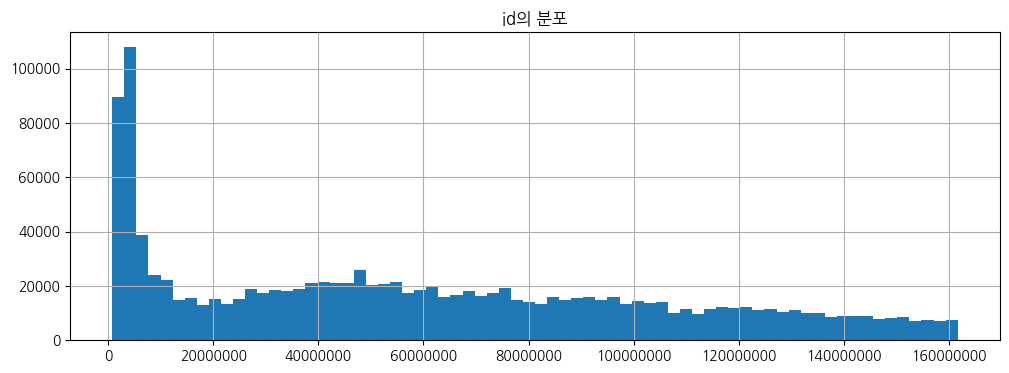

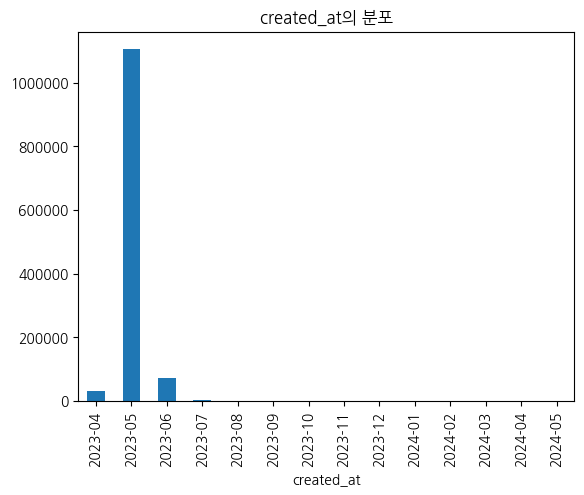

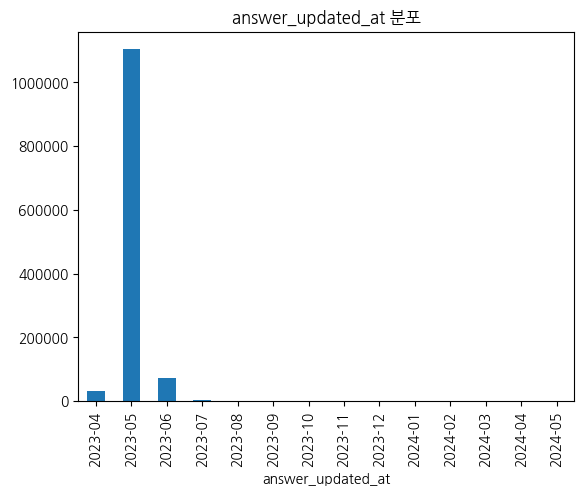

In [25]:
# id, created_at, answer_updated_at의 데이터 분포 확인
plt.figure(figsize=(12, 4))
df['id'].hist(bins=70)
plt.title('id의 분포')
plt.show()

df['created_at'].dt.to_period('M').value_counts().sort_index().plot(kind='bar')
plt.title('created_at의 분포')
plt.show()

df['answer_updated_at'].dt.to_period('M').value_counts().sort_index().plot(kind='bar')
plt.title('answer_updated_at 분포')
plt.show()

In [26]:
# account_user의 user_id에 속하지 않은 chosen_user_id, user_id 추출

check_valid_user_id(df, 'chosen_user_id')
check_valid_user_id(df, 'user_id')

account_user의 user_id에 속하지 않은 chosen_user_id 수: 0



,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times


account_user의 user_id에 속하지 않은 user_id 수: 0



,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times


In [27]:
# polls_question의 id에 속하지 않은 question_id 추출

polls_question = open_csv('polls_question')
question_ids = polls_question['id']

cond = df['question_id'].isin(question_ids)
print(f'polls_question의 id에 속하지 않은 question_id 수: {len(df[~cond])}')
print('')
display(df[~cond])

polls_question의 id에 속하지 않은 question_id 수: 0



,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times


In [28]:
# question_id-question_piece_id 조합이 잘못된 경우 추출

# polls_questionpiece 데이터 불러오기
polls_questionpiece = open_csv('polls_questionpiece')

# 1. polls_questionpiece에서 유효한 (id, question_id) 조합 집합 만들기
valid_combos = set(zip(polls_questionpiece['id'], polls_questionpiece['question_id']))

# 2. df에서 (question_piece_id, question_id) 조합 만들기
df_combos = list(zip(df['question_piece_id'], df['question_id']))

# 3. df의 조합이 valid_combos에 속하는지 확인
cond = pd.Series(df_combos, index=df.index).apply(lambda x: x in valid_combos)

print(f'유효하지 않은 조합 수: {(~cond).sum()}')
display(df[~cond])

유효하지 않은 조합 수: 0


,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times


In [29]:
# report_count 이상치 확인

df['report_count'].value_counts()

,count
report_count,
0,1217389
1,147
2,15
3,3
5,1
4,1
6,1
14,1


In [30]:
# 신고를 14번 받은 투표 기록 확인

df[df['report_count'] == 14]

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
808977,78776644,C,2023-05-19 15:26:26,1138757,1137,1343904,100734177,1,A,2023-05-19 15:26:40,14,0


In [31]:
reported_14_times_user_id = df[df['report_count'] == 14]['user_id'].iloc[0]
reported_14_times_chosen_user_id = df[df['report_count'] == 14]['chosen_user_id'].iloc[0]
reported_14_times_question_id = df[df['report_count'] == 14]['question_id'].iloc[0]

polls_questionreport = open_csv('polls_questionreport')
display(polls_questionreport[polls_questionreport['user_id'] == reported_14_times_user_id])
display(polls_questionreport[polls_questionreport['user_id'] == reported_14_times_chosen_user_id])
display(polls_questionreport[polls_questionreport['question_id'] == reported_14_times_question_id])

,id,reason,created_at,question_id,user_id


,id,reason,created_at,question_id,user_id


,id,reason,created_at,question_id,user_id
22297,24369,나랑 맞지 않는 질문인 것 같음,2023-05-16 16:12:02,1137,1149465
22614,24718,그냥 싫어,2023-05-17 01:48:14,1137,1071536
24346,26607,그냥 싫어,2023-05-17 22:24:08,1137,1319429
26933,29371,그냥 싫어,2023-05-19 13:08:50,1137,1165762
26937,29375,나랑 맞지 않는 질문인 것 같음,2023-05-19 13:09:42,1137,1165762
28160,30735,불쾌한 질문 내용,2023-05-20 08:54:22,1137,1176029
28966,31625,그냥 싫어,2023-05-20 14:18:45,1137,1319989
30061,32843,그냥 싫어,2023-05-21 04:59:49,1137,1402628
30642,33457,그냥 싫어,2023-05-21 09:22:14,1137,1323435
31282,34141,불쾌한 질문 내용,2023-05-21 12:46:03,1137,1182363


> **신고 기록**

신고 기록 테이블인 `polls_questionreport` 테이블에서는 신고를 14번 받은 투표 기록이 없었다.  
`accounts_userquestionrecord`에서 신고 기록이 1회 이상인 경우,  `polls_questionreport`의 기록에 포함되어야 할 것으로 생각된다.  
실제로 그런지 확인해보겠다.

In [32]:
# polls_questionreport(질문에 대한 신고기록 테이블)과 신고 내역 비교대조

reported = df[df['report_count'] >= 1]

print(f'polls_questionreport 테이블의 행 수: {len(polls_questionreport)}')
print(f'accounts_userquestionrecord 테이블에서 신고가 1회 이상인 행 수: {len(reported)}')
print(f'차이: {len(polls_questionreport) - len(reported)}행')
print(f'비율: {len(reported) / len(polls_questionreport)*100:.2f}%')

polls_questionreport 테이블의 행 수: 51424
accounts_userquestionrecord 테이블에서 신고가 1회 이상인 행 수: 169
차이: 51255행
비율: 0.33%


In [33]:
combos_1 = reported[['question_id', 'user_id']]
combos_2 = reported[['question_id', 'chosen_user_id']]

# 함수 지정: question_id와 user_id 조합으로 겹치는 행이 있는지 확인
def match_test(df,question_col, user_id_col):
  # ['question_id', 'user_id'] 조합과 일치하는 수 확인
  matched = combos_1.drop_duplicates().merge(
      df[[question_col, user_id_col]].drop_duplicates(),
      left_on=['question_id', 'user_id'],
      right_on=[question_col, user_id_col],
      how='inner'
  )
  print(f"[{question_col} = 'question_id', {user_id_col} = 'user_id'] 조합")
  print(f'일치하는 조합 수: {len(matched)}')
  display(matched)
  print('')

  # ['question_id', 'chosen_user_id'] 조합과 일치하는 수 확인
  matched = combos_2.drop_duplicates().merge(
      df[[question_col, user_id_col]].drop_duplicates(),
      left_on=['question_id', 'chosen_user_id'],
      right_on=[question_col, user_id_col],
      how='inner'
  )
  print(f"[{question_col} = 'question_id', {user_id_col} = 'chosen_user_id'] 조합")
  print(f'일치하는 조합 수: {len(matched)}')
  display(matched)

# 함수 실행
match_test(polls_questionreport, 'question_id', 'user_id')

[question_id = 'question_id', user_id = 'user_id'] 조합
일치하는 조합 수: 0


,question_id,user_id



[question_id = 'question_id', user_id = 'chosen_user_id'] 조합
일치하는 조합 수: 2


,question_id,chosen_user_id,user_id
0,476,1138955,1138955
1,379,1140485,1140485


> **신고 기록 확인 결과**

'accounts_userquestionrecord' 테이블에서 신고 기록이 1회 이상인 경우,  'polls_questionreport' 테이블의 기록에 포함된 수는 단 2건이었다.  
(단, 'polls_questionreport' 테이블의 `user_id`가 `accounts_userquestionrecord`의 `chosen_user_id`로 가정할 경우)  

'accounts_userquestionrecord' 테이블의 `report_count`의 신고 세부 내용은 'polls_questionreport' 테이블이 아닌 다른 테이블에 적재되었거나, 데이터가 유실되었을 가능성이 있는 것으로 생각된다.


In [34]:
# accounts_timelinereport(유저 신고기록 테이블)과 신고 내역 비교대조
accounts_timelinereport = open_csv('accounts_timelinereport')
accounts_timelinereport.head()

,id,reason,created_at,reported_user_id,user_id,user_question_record_id
0,28,타인을 사칭함,2023-05-06 04:44:57,874587,885082,3920588
1,37,친구를 비하하거나 조롱하는 어투,2023-05-06 05:41:19,881048,881298,4018679
2,46,친구를 비하하거나 조롱하는 어투,2023-05-06 06:26:59,887882,881945,4120914
3,64,허위 사실 언급,2023-05-06 07:07:46,888610,893684,4143049
4,65,허위 사실 언급,2023-05-06 07:07:52,888610,893684,4143049


In [35]:
reported = df[df['report_count'] >= 1]

print(f'accounts_timelinereport 테이블의 행 수: {len(accounts_timelinereport)}')
print(f'accounts_userquestionrecord 테이블에서 신고가 1회 이상인 행 수: {len(reported)}')
print(f'차이: {len(accounts_timelinereport) - len(reported)}행')
print(f'비율: {len(reported) / len(accounts_timelinereport)*100:.2f}%')

accounts_timelinereport 테이블의 행 수: 208
accounts_userquestionrecord 테이블에서 신고가 1회 이상인 행 수: 169
차이: 39행
비율: 81.25%


In [36]:
match_test(accounts_timelinereport, 'user_question_record_id', 'user_id')
print('')
print('='*60)
match_test(accounts_timelinereport, 'user_question_record_id', 'reported_user_id')

[user_question_record_id = 'question_id', user_id = 'user_id'] 조합
일치하는 조합 수: 0


,question_id,user_id,user_question_record_id



[user_question_record_id = 'question_id', user_id = 'chosen_user_id'] 조합
일치하는 조합 수: 0


,question_id,chosen_user_id,user_question_record_id,user_id



[user_question_record_id = 'question_id', reported_user_id = 'user_id'] 조합
일치하는 조합 수: 0


,question_id,user_id,user_question_record_id,reported_user_id



[user_question_record_id = 'question_id', reported_user_id = 'chosen_user_id'] 조합
일치하는 조합 수: 0


,question_id,chosen_user_id,user_question_record_id,reported_user_id


In [37]:
combos_1 = reported[['user_id', 'chosen_user_id']]

# 함수 지정: user_id와 chosen_user_id 조합으로 겹치는 행이 있는지 확인
def user_id_match_test(df,question_col, user_id_col):
  # ['user_id'와, 'chosen_user_id'] 조합과 일치하는 수 확인
  matched = combos_1.drop_duplicates().merge(
      df[[question_col, user_id_col]].drop_duplicates(),
      left_on=['user_id', 'chosen_user_id'],
      right_on=[question_col, user_id_col],
      how='inner'
  )
  print(f"[{question_col} = 'user_id', {user_id_col} = 'chosen_user_id'] 조합")
  print(f'일치하는 조합 수: {len(matched)}')
  display(matched)
  print('')

# 함수 실행
unique_combo_count = len(reported[['user_id', 'chosen_user_id']].drop_duplicates())
print(f'1회 이상 신고가 들어간 user_id - chosen_user_id 조합 수 : {unique_combo_count}')
print('')
user_id_match_test(accounts_timelinereport, 'user_id', 'reported_user_id')
user_id_match_test(accounts_timelinereport, 'reported_user_id', 'user_id')

1회 이상 신고가 들어간 user_id - chosen_user_id 조합 수 : 159

[user_id = 'user_id', reported_user_id = 'chosen_user_id'] 조합
일치하는 조합 수: 51


,user_id,chosen_user_id,reported_user_id
0,885082,874587,874587
1,881298,881048,881048
2,893684,888610,888610
3,887254,895726,895726
4,887254,876060,876060
5,878909,885328,885328
6,885300,884885,884885
7,876580,877824,877824
8,1002212,1003953,1003953
9,1115498,1115501,1115501



[reported_user_id = 'user_id', user_id = 'chosen_user_id'] 조합
일치하는 조합 수: 1


,user_id_x,chosen_user_id,reported_user_id,user_id_y
0,1214735,1227249,1214735,1227249


> **신고 기록 확인 결과 2**

'accounts_userquestionrecord' 테이블에서 신고 기록이 1회 이상인 경우,  'accounts_timelinereport' 테이블의 기록에 포함된 수는 없었다.

따라서, 'accounts_userquestionrecord' 테이블의 `report_count`의 신고 세부 내용은 'accounts_timelinereport' 테이블과는 연관이 없다는 점을 확인했다.
  
⭐ 결론: `polls_questionreport`에서 신고가 14건 발생한 투표 기록의 경우 이상치로 간주할 근거를 찾을 수 없어 삭제 없이 진행하도록 하겠다.


In [38]:
# 컬럼 분포 확인

# 함수 지정
def check_val_cnts(df, col):
  print(f'----- {col} -----')
  display(df[col].value_counts())

# 분포 확인
cols = ['opened_times', 'status', 'has_read', 'answer_status']

for col in cols:
  check_val_cnts(df, col)
  print('')

----- opened_times -----


,count
opened_times,
0,1156896
1,46882
2,11120
3,2660



----- status -----


,count
status,
C,1156322
I,60578
B,658



----- has_read -----


,count
has_read,
1,675931
0,541627



----- answer_status -----


,count
answer_status,
N,1097932
A,111761
P,7865


In [39]:
# accounts_blockrecord(차단 기록 테이블) 불러오기

accounts_blockrecord = open_csv('accounts_blockrecord')
accounts_blockrecord.head()

,id,reason,created_at,block_user_id,user_id
0,1,그냥...,2023-05-04 23:01:53,867483,878476
1,2,친구 사이가 어색해짐,2023-05-05 01:17:08,867190,867564
2,3,나랑 관련 없는 질문을 자꾸 보냄,2023-05-05 01:50:55,875110,875261
3,6,그냥...,2023-05-05 05:21:52,883696,883511
4,7,그냥...,2023-05-05 06:40:34,871349,870177


In [40]:
# accounts_blockrecord(차단 기록 테이블)과 status 컬럼의 B값에 해당하는 행 비교대조

combos_1 = df[['user_id', 'chosen_user_id']]
ab = accounts_blockrecord[['block_user_id', 'user_id']]

# combos_1 <-> ab 겹치는 조합 확인
matched = combos_1.drop_duplicates().merge(
    ab.drop_duplicates(),
    left_on=['user_id', 'chosen_user_id'],
    right_on=['block_user_id', 'user_id'],
    how='inner'
)
print(f"user_id = 'block_user_id', chosen_user_id = 'user_id'] 조합")
print(f'일치하는 조합 수: {len(matched)}')
print('')

user_id = 'block_user_id', chosen_user_id = 'user_id'] 조합
일치하는 조합 수: 62



In [41]:
# accounts_blockrecord(차단 기록 테이블)과 status 컬럼의 B값에 해당하는 행 비교대조
# 추가된 시간까지 동일한 경우 추출

# 일자 컬럼을 datetime 타입으로 변경
df['created_at'] = pd.to_datetime(df['created_at'])
accounts_blockrecord['created_at'] = pd.to_datetime(accounts_blockrecord['created_at'])


combos_1 = df[['user_id', 'chosen_user_id', 'created_at']].drop_duplicates()
combos_2 = df[['chosen_user_id', 'user_id', 'created_at']].drop_duplicates()
ab = accounts_blockrecord[['block_user_id', 'user_id', 'created_at']].drop_duplicates()

# combos_1 <-> ab 겹치는 조합 확인
matched = combos_1.merge(
    ab,
    left_on=['user_id', 'chosen_user_id', 'created_at'],
    right_on=['block_user_id', 'user_id', 'created_at'],
    how='inner'
)
print(f"user_id = 'block_user_id', chosen_user_id = 'user_id'] 조합")
print(f'일치하는 조합 수: {len(matched)}')
print('')

# combos_2 <-> ab 겹치는 조합 확인
matched = combos_2.merge(
    ab,
    left_on=['chosen_user_id', 'user_id', 'created_at'],
    right_on=['block_user_id', 'user_id', 'created_at'],
    how='inner'
)
print(f"chosen_user_id = 'block_user_id', 'user_id' = 'user_id'] 조합")
print(f'일치하는 조합 수: {len(matched)}')
print('')

user_id = 'block_user_id', chosen_user_id = 'user_id'] 조합
일치하는 조합 수: 0

chosen_user_id = 'block_user_id', 'user_id' = 'user_id'] 조합
일치하는 조합 수: 0



> **status 컬럼의 Blocked (차단)된 데이터 교차확인 결과**


'accounts_userquestionrecord' 테이블의 `status` 컬럼의 값이 B인 경우와   'accounts_blockrecord' 테이블의 차단 기록을 비교대조해 보았지만, `created_at`(만든 시간)까지 동일한 데이터는 없었다.

유저가 다른 유저를 차단했을 때 'accounts_blockrecord'테이블에 적재되는 시간은 'accounts_userquestionrecord' 테이블과 다르거나, 'accounts_blockrecord' 테이블의 일부 데이터가 삭제되었을 것으로 추측된다.
  
⭐ 결론: `accounts_userquestionrecord`의 `status` 컬럼이 B값일 경우, 이상값으로 판단할 근거를 찾을 수 없어 삭제하지 않고 진행하도록 하겠다.

In [42]:
# 'created_at', 'chosen_user_id', 'user_id' 조합의 중복 확인

cond = df[['created_at', 'chosen_user_id', 'user_id', 'has_read']].duplicated(keep=False)
au_dups = df[cond]

print(f'중복값 수: {len(au_dups)}')
au_dups.head()

중복값 수: 112


,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
238608,7865049,C,2023-05-07 23:23:53,885457,499,925036,10556709,1,N,2023-05-07 23:23:53,0,0
238609,7865052,C,2023-05-07 23:23:53,885457,139,925036,10556711,1,N,2023-05-07 23:23:53,0,0
240674,8022858,C,2023-05-08 01:32:05,975137,129,975795,10865647,0,N,2023-05-08 01:32:05,0,0
240675,8022859,C,2023-05-08 01:32:05,975137,435,975795,10865645,0,N,2023-05-08 01:32:05,0,0
241340,8076873,C,2023-05-08 02:16:35,888267,284,886888,10445018,1,N,2023-05-08 02:16:35,0,0


In [43]:
# 중복된 행의 question_piece_id가 한 질문 세트에 포함될 경우 정상 데이터로 판단

# polls_questionset(질문 세트 테이블) 가져오기
polls_questionset = open_csv('polls_questionset')
polls_questionset.head()

,id,question_piece_id_list,opening_time,status,created_at,user_id
0,99817,"[998458, 998459, 998460, 998461, 998462, 99846...",2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
1,99830,"[998588, 998589, 998590, 998591, 998592, 99859...",2023-04-28 12:28:07,F,2023-04-28 12:28:07,849438
2,99840,"[998689, 998691, 998693, 998695, 998697, 99869...",2023-04-28 12:28:38,F,2023-04-28 12:28:38,847375
3,99841,"[998688, 998690, 998692, 998694, 998696, 99869...",2023-04-28 12:28:38,F,2023-04-28 12:28:38,849446
4,99848,"[998768, 998769, 998770, 998771, 998772, 99877...",2023-04-28 12:28:57,F,2023-04-28 12:28:57,849477


In [44]:
# 문자열을 리스트로 변환
polls_questionset['question_piece_id_list'] = polls_questionset['question_piece_id_list'].apply(ast.literal_eval)

# explode로 리스트를 행 단위로 풀기
exploded = polls_questionset.explode('question_piece_id_list').rename(columns={'question_piece_id_list': 'question_piece_id'})

exploded.head()

,id,question_piece_id,opening_time,status,created_at,user_id
0,99817,998458,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
0,99817,998459,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
0,99817,998460,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
0,99817,998461,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
0,99817,998462,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436


In [45]:
# 1. 중복 그룹(같은 created_at, chosen_user_id, user_id) 뽑기
dup_mask = df.duplicated(subset=['created_at', 'chosen_user_id', 'user_id'], keep=False)
dup_df = df[dup_mask].copy()

# 2. 각 question_piece_id가 exploded에서 어떤 questionset id에 속하는지 매핑
piece_to_set = exploded.set_index('question_piece_id')['id']
dup_df['set_id'] = dup_df['question_piece_id'].map(piece_to_set)

# 3. 그룹별로 set_id가 다 같은지(1개인지) 확인
check = dup_df.groupby(['created_at', 'chosen_user_id', 'user_id'])['set_id'].nunique()

print(f'문제없는 그룹 수 (set_id가 1개): {(check == 1).sum()}')
print(f'문제 있는 그룹 수 (set_id가 2개 이상): {(check > 1).sum()}')

# 4. 문제 있는 그룹이 있다면 확인
problem_groups = check[check > 1].index
dup_df[dup_df.set_index(['created_at', 'chosen_user_id', 'user_id']).index.isin(problem_groups)]

문제없는 그룹 수 (set_id가 1개): 62
문제 있는 그룹 수 (set_id가 2개 이상): 0


,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times,set_id


> **'created_at', 'chosen_user_id', 'user_id' 조합의 중복 확인 결과**


'accounts_userquestionrecord' 테이블의 'created_at', 'chosen_user_id', 'user_id' 조합을 확인했을 때, 초 단위까지 중복되지만 'question_id	user_id',	'question_piece_id'만 다른 행을 발견했다.

이 행들이 한 질문 세트에 포함되는 경우, 유저가 짧은 시간에 빠르게 답했을 수 있기에 이상이 아니라고 판단하기로 했다.
  
⭐ 결론: 이상이 있는 행은 없어 삭제 없이 진행하도록 하겠다.

In [46]:
# 'has_read' = 0, 'opened_times' = 1 일 경우 이상치 -> 삭제처리
# 받은 투표를 읽지 않았는데 초성을 오픈하는 것은 불가능한 것으로 판단함

cond = (df['has_read'] == 0) & (df['opened_times'] == 1)
au_cleaned = df[~cond]

print(f'삭제 전 행 수: {len(df)}')
print(f'삭제 후 행 수: {len(au_cleaned)}')
print(f'삭제된 행 수: {len(df) - len(au_cleaned)}')

삭제 전 행 수: 1217558
삭제 후 행 수: 1213926
삭제된 행 수: 3632


In [47]:
# # 공유 드라이브에 저장
# save_to_drive(au_cleaned, 'accounts_userquestionrecord_cleaned')

## 전처리 함수와 모듈의 동일성 테스트

In [48]:
from pandas.testing import assert_frame_equal

ap_cleaned = ap_cleaned.reset_index(drop=True)
au_cleaned = au_cleaned.reset_index(drop=True)

tests = [
    (ap_cleaned, clean_accounts_paymenthistory),
    (au_cleaned, clean_accounts_userquestionrecord),
]

for orig_df, func in tests:
    test_clean_df = func()

    # 두 데이터프레임이 완전히 같으면 아무 일도 일어나지 않고 통과합니다.
    # 다르면 어느 부분이 다른지 상세한 에러 메시지가 뜹니다.
    assert_frame_equal(orig_df, test_clean_df)
    print("✅ 두 데이터프레임이 완벽히 일치합니다!")

✅ 두 데이터프레임이 완벽히 일치합니다!
✅ 두 데이터프레임이 완벽히 일치합니다!


In [49]:
# 모듈화된 전처리 함수 확인
funcs = [clean_accounts_user, clean_accounts_group, clean_accounts_school,
         clean_accounts_nearbyschool, clean_polls_question, clean_polls_questionpiece,
         clean_accounts_attendance, clean_accounts_blockrecord, clean_polls_questionset,
         clean_accounts_paymenthistory, clean_accounts_userquestionrecord,
         clean_polls_usercandidate, clean_accounts_user_contacts, clean_accounts_friendrequest,
         clean_accounts_userwithdraw, clean_polls_questionset_piece]

for func in funcs:
  print(f'----- {func.__name__} -----')
  df = func()
  display(df.head())
  print('')

----- clean_accounts_user -----


,id,gender,is_push_on,created_at,ban_status,pending_chat,group_id,alarm_count
0,831962,F,1,2023-03-29 05:18:56.162368,N,256,12,238
1,832151,M,0,2023-03-29 12:56:34.989468,N,0,1,37
2,832340,F,1,2023-03-29 12:56:35.020790,N,0,1,19
3,832520,M,0,2023-03-29 12:56:35.049311,N,0,12,29
4,832614,M,1,2023-03-29 12:56:35.064406,N,0,12,28



----- clean_accounts_group -----


,id,grade,class_num,school_id
0,1,1,1,1
1,8,3,2,1
2,9,3,3,1
3,10,2,2,1
4,11,2,3,1



----- clean_accounts_school -----


,id,address,student_count,school_type
0,4,충청북도 충주시,239,H
1,5,충청북도 충주시,160,M
2,6,충청북도 충주시,200,H
3,7,충청북도 충주시,114,H
4,8,충청북도 충주시,139,M


... (22 outputs left out)


----- clean_accounts_userwithdraw -----


,id,reason,created_at
0,42,재밌는 질문이 없어서,2023-03-29 13:22:12
1,43,함께 할 친구가 없어서,2023-03-29 13:24:59
2,44,함께 할 친구가 없어서,2023-03-29 13:53:32
3,45,함께 할 친구가 없어서,2023-03-29 13:54:03
4,46,재밌는 질문이 없어서,2023-03-30 00:31:19



----- clean_polls_questionset_piece -----


,questionset_id,question_piece_id,stored_position
0,99817,998458,1
1,99817,998459,2
2,99817,998460,3
3,99817,998461,4
4,99817,998462,5


# EDA

## 투표 Give-and-Take 불균형과 상호작용 붕괴

### 리텐션 확인(월별 코호트)
활성 기준: 출석, 친구 요청, 하트 구매, 투표

In [50]:
# 전처리 완료 테이블 불러오기

accounts_attendance = clean_accounts_attendance()
accounts_friendrequest = clean_accounts_friendrequest()
accounts_paymenthistory = clean_accounts_paymenthistory()
accounts_userquestionrecord = clean_accounts_userquestionrecord()
accounts_user = clean_accounts_user()

tables = {
    'accounts_attendance': accounts_attendance,
    'accounts_friendrequest': accounts_friendrequest,
    'accounts_paymenthistory': accounts_paymenthistory,
    'accounts_userquestionrecord': accounts_userquestionrecord,
    'accounts_user': accounts_user,
}

for name, table in tables.items():
  print(f'----- \n{name} -----')
  display(table.head())

----- 
accounts_attendance -----


,attendance_record_id,user_id,attendance_date
0,1,1446852,2023-05-27
1,1,1446852,2023-05-28
2,1,1446852,2023-05-29
3,1,1446852,2023-05-30
4,1,1446852,2023-06-03


----- 
accounts_friendrequest -----


,id,status,created_at,updated_at,receive_user_id,send_user_id
0,7,P,2023-04-17 18:29:11,2023-04-17 18:29:11,831962,837521
1,10,A,2023-04-17 18:29:11,2023-04-22 06:02:53,832151,837521
2,11,A,2023-04-17 18:29:11,2023-04-18 19:28:41,832340,837521
3,13,A,2023-04-17 18:29:11,2023-04-19 11:05:04,833041,837521
4,20,P,2023-04-17 18:29:11,2023-04-17 18:29:11,834415,837521


----- 
accounts_paymenthistory -----


,id,productId,phone_type,created_at,user_id
0,6,heart.777,A,2023-05-13 21:28:34,1211127
1,7,heart.777,A,2023-05-13 21:29:39,1151343
2,8,heart.777,A,2023-05-13 21:31:33,1002147
3,9,heart.777,A,2023-05-13 21:31:39,1095040
4,11,heart.777,A,2023-05-13 21:34:32,1164081


----- 
accounts_userquestionrecord -----


,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
0,771777,C,2023-04-28 12:27:49,849469,252,849436,998458,0,N,2023-04-28 12:27:49,0,0
1,771800,C,2023-04-28 12:28:02,849446,244,849436,998459,0,N,2023-04-28 12:28:02,0,0
2,771812,C,2023-04-28 12:28:09,849454,183,849436,998460,1,N,2023-04-28 12:28:09,0,0
3,771828,C,2023-04-28 12:28:16,847375,101,849436,998461,0,N,2023-04-28 12:28:16,0,0
4,771851,C,2023-04-28 12:28:26,849477,209,849436,998462,1,N,2023-04-28 12:28:26,0,0


----- 
accounts_user -----


,id,gender,is_push_on,created_at,ban_status,pending_chat,group_id,alarm_count
0,831962,F,1,2023-03-29 05:18:56.162368,N,256,12,238
1,832151,M,0,2023-03-29 12:56:34.989468,N,0,1,37
2,832340,F,1,2023-03-29 12:56:35.020790,N,0,1,19
3,832520,M,0,2023-03-29 12:56:35.049311,N,0,12,29
4,832614,M,1,2023-03-29 12:56:35.064406,N,0,12,28


In [51]:
# 일자별 활성 유저 추출
tables = [
    accounts_attendance[['user_id', 'attendance_date']].rename(columns={'attendance_date': 'created_at'}),
    accounts_friendrequest[['send_user_id', 'created_at']].rename(columns={'send_user_id': 'user_id'}),
    accounts_paymenthistory[['user_id', 'created_at']],
    accounts_userquestionrecord[['user_id', 'created_at']],
]

tables_combined = pd.concat(tables, ignore_index=True)
tables_combined['created_at'] = pd.to_datetime(tables_combined['created_at'])
tables_combined = tables_combined.rename(columns={'created_at': 'event_time'})
tables_combined = tables_combined.drop_duplicates()

print(f'활성 유저 및 일자 shape: ', tables_combined.shape)
tables_combined.head()

활성 유저 및 일자 shape:  (12834978, 2)


,user_id,event_time
0,1446852,2023-05-27
1,1446852,2023-05-28
2,1446852,2023-05-29
3,1446852,2023-05-30
4,1446852,2023-06-03


In [52]:
# MAU

mau_df = tables_combined.copy()
mau_df['activity_month'] = pd.to_datetime(mau_df['event_time']).dt.to_period('M')

monthly_active_users = (
    mau_df.groupby('activity_month')['user_id']
    .nunique()
    .reset_index(name='mau')
)

monthly_active_users

,activity_month,mau
0,2023-04,16945
1,2023-05,624150
2,2023-06,259419
3,2023-07,66703
4,2023-08,30367
5,2023-09,22460
6,2023-10,9803
7,2023-11,7044
8,2023-12,4042
9,2024-01,3620


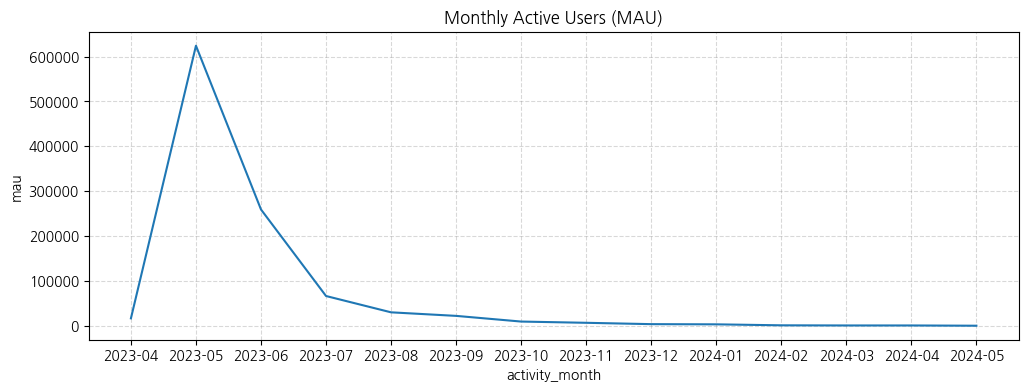

In [53]:
# MAU 시각화
df = monthly_active_users.copy()
df['activity_month'] = df['activity_month'].astype(str).copy()

plt.figure(figsize=(12, 4))

sns.lineplot(data=df,
             x='activity_month',
             y='mau')

plt.title('Monthly Active Users (MAU)')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.show()

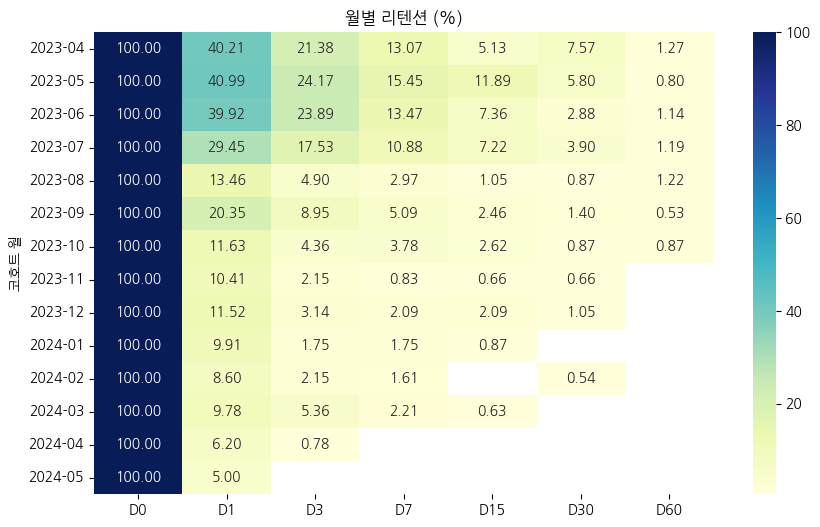

In [54]:
# 월별 D0, D1, D3, D7, D15, D30, D60 리텐션

# 리텐션 테이블 함수 정의
def get_retention_rate(df):
    retention_df = df.copy()

    # 1. 날짜 형식으로 변환 (시간 제거, 날짜만 남김)
    retention_df['event_time'] = pd.to_datetime(retention_df['event_time']).dt.normalize()

    # 2. 유저별 가입일(최초 event_time) 계산
    retention_df['signup_date'] = retention_df.groupby('user_id')['event_time'].transform('min')

    # 3. 가입일로부터 경과한 일수(Day Diff) 계산
    retention_df['day_diff'] = (retention_df['event_time'] - retention_df['signup_date']).dt.days

    # 4. 가입 월(Cohort Month) 생성
    retention_df['cohort_month'] = retention_df['signup_date'].dt.to_period('M')

    # 5. 확인할 D-day 리스트 설정
    target_days = [0, 1, 3, 7, 15, 30, 60]

    # 6. 가입 월 및 D-day별 고유 유저 수 집계
    retention_agg = (
        retention_df[retention_df['day_diff'].isin(target_days)]
        .groupby(['cohort_month', 'day_diff'])['user_id']
        .nunique()
        .reset_index()
    )

    # 7. 피벗 테이블로 변환
    retention_pivot = retention_agg.pivot(index='cohort_month', columns='day_diff', values='user_id')
    retention_pivot = retention_pivot.reindex(columns=target_days)

    # 8. D0 기준 백분율 리텐션 계산
    d0_users = retention_pivot[0]
    retention_rate = retention_pivot.divide(d0_users, axis=0) * 100
    retention_rate = retention_rate.round(2)

    # 9. 컬럼명 D0, D1, D3... 형태로 변경
    retention_rate.columns = [f'D{col}' for col in retention_rate.columns]

    return retention_rate

# 리텐션 히트맵 함수 정의
def get_retention_heatmap(df):
    plt.figure(figsize=(10, 6))

    sns.heatmap(df, annot=True, fmt='.2f', cmap='YlGnBu')
    plt.title('월별 리텐션 (%)')
    plt.ylabel('코호트 월')

    plt.show()

retention_rate = get_retention_rate(tables_combined)
get_retention_heatmap(retention_rate)

#### 투표를 받기만 한 유저의 리텐션 확인

In [56]:
voted_user_ids = set(accounts_userquestionrecord['user_id'].unique())  # 투표한 고유 유저 id
chosen_user_ids = set(accounts_userquestionrecord['chosen_user_id'].unique())  # 투표받은 고유 유저 id

# 투표를 하거나 받은 고유 유저 id
vote_related_user_ids = voted_user_ids | chosen_user_ids

total_active_users = tables_combined['user_id'].nunique()
vote_related_ratio = len(vote_related_user_ids) / total_active_users * 100

print(f'전체 활성 유저 수: {total_active_users:,}')
print(f'투표를 하거나 받은 유저 수: {len(vote_related_user_ids):,}')
print(f'투표를 하거나 받은 유저 비율: {vote_related_ratio:.2f}%')

전체 활성 유저 수: 653,085
투표를 하거나 받은 유저 수: 15,445
투표를 하거나 받은 유저 비율: 2.36%


In [192]:
# 투표를 하거나 받은 유저 중, 투표를 받기만 한 유저 id (투표 기록 기준)
chosen_only_user_id = vote_related_user_ids - voted_user_ids

# 받기만 한 유저들의 전체 활동 로그 추출 (리텐션·검정에 쓰일 df)
cond_chosen_only = tables_combined['user_id'].isin(chosen_only_user_id)
chosen_only_df = tables_combined[cond_chosen_only].copy()

# 활동 로그가 없어 분석 대상에서 빠지는 유저 확인
no_activity_user_id = chosen_only_user_id - set(chosen_only_df['user_id'])

# 투표를 하거나 받은 유저 중, 투표를 받기만 한 유저 비율 (분석 대상 기준)
chosen_only_ratio = (chosen_only_df['user_id'].nunique() / len(vote_related_user_ids)) * 100

print(f'투표한 유저 수: {len(voted_user_ids):,}')
print(f'투표받은 유저 수: {len(chosen_user_ids):,}')
print(f'투표를 받기만 한 유저 수 (투표 기록 기준): {len(chosen_only_user_id):,}')
print(f'그중 활동 로그가 없어 분석에서 제외되는 유저 수: {len(no_activity_user_id):,}')
print(f'투표를 받기만 한 유저 수 (분석 대상 기준): {chosen_only_df["user_id"].nunique():,}')
print(f'투표를 받기만 한 유저 비율 (분석 대상 기준): {chosen_only_ratio:.2f}%')

투표한 유저 수: 4,849
투표받은 유저 수: 15,419
투표를 받기만 한 유저 수 (투표 기록 기준): 10,596
그중 활동 로그가 없어 분석에서 제외되는 유저 수: 210
투표를 받기만 한 유저 수 (분석 대상 기준): 10,386
투표를 받기만 한 유저 비율 (분석 대상 기준): 67.25%


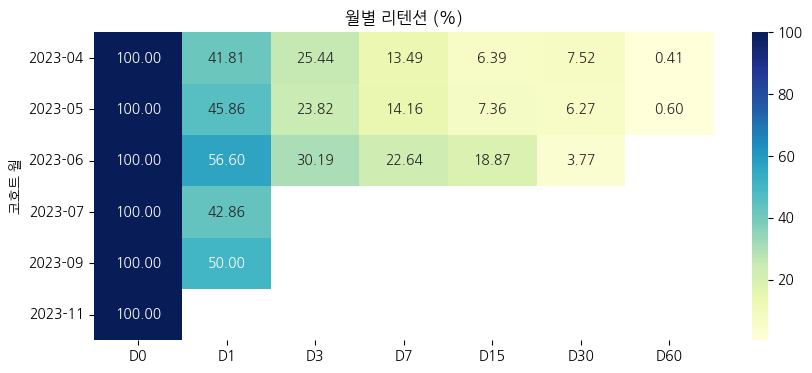

In [58]:
# 투표를 받기만 한 유저의 리텐션

# 투표를 받기만 한 유저들의 전체 활동 로그 추출
cond_chosen_only = tables_combined['user_id'].isin(chosen_only_user_id)
chosen_only_df = tables_combined[cond_chosen_only].copy()

# 투표를 받기만 한 유저들의 리텐션 테이블
chosen_only_retention_rate = get_retention_rate(chosen_only_df)

# 투표를 받기만 한 유저들의 리텐션 히트맵
plt.figure(figsize=(10, 4))

sns.heatmap(chosen_only_retention_rate, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('월별 리텐션 (%)')
plt.ylabel('코호트 월')

plt.show()

⚠️ 문제점  
리텐션 계산 시 활성 기준을: 출석, 친구 요청, 하트 구매, 투표로 잡았는데,  
이 중 투표를 전혀 하지 않았기에 리텐션이 낮게 나올 가능성 있음.

#### 투표를 주기만 한 유저의 리텐션 확인

In [59]:
# 투표를 하거나 받은 유저 중, 투표를 주기만 한 유저 id
voted_only_user_id = vote_related_user_ids - chosen_user_ids

# 투표를 하거나 받은 유저 중, 투표를 주기만 한 유저 비율
voted_only_ratio = (len(voted_only_user_id) / len(vote_related_user_ids)) * 100

print(f'투표한 유저 수: {len(voted_user_ids):,}')
print(f'투표받은 유저 수: {len(chosen_user_ids):,}')
print(f'투표를 주기만 한 유저 수: {len(voted_only_user_id):,}')
print(f'투표를 주기만 한 유저 비율: {voted_only_ratio:.2f}%')

투표한 유저 수: 4,849
투표받은 유저 수: 15,419
투표를 주기만 한 유저 수: 26
투표를 주기만 한 유저 비율: 0.17%


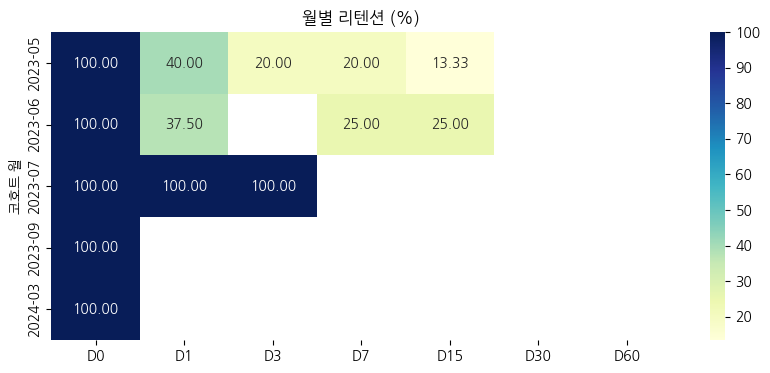

In [60]:
# 투표를 주기만 한 유저의 리텐션

# 투표를 주기만 한 유저들의 전체 활동 로그 추출
cond_voted_only = tables_combined['user_id'].isin(voted_only_user_id)
voted_only_df = tables_combined[cond_voted_only].copy()

# 투표를 주기만 한 유저들의 리텐션 테이블
voted_only_retention_rate = get_retention_rate(voted_only_df)

# 투표를 주기만 한 유저들의 리텐션 히트맵
plt.figure(figsize=(10, 4))

sns.heatmap(voted_only_retention_rate, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('월별 리텐션 (%)')
plt.ylabel('코호트 월')

plt.show()

#### 투표를 주고 받은 유저의 리텐션 확인

In [61]:
# 투표를 주고 받은 유저 id
voted_and_chosen_user_id = chosen_user_ids & voted_user_ids

# 투표를 하거나 받은 유저 중, 투표를 주고 받은 유저 비율
voted_and_chosen_ratio = (len(voted_and_chosen_user_id) / len(vote_related_user_ids)) * 100

print(f'투표한 유저 수: {len(voted_user_ids):,}')
print(f'투표받은 유저 수: {len(chosen_user_ids):,}')
print(f'투표를 주고 받은 유저 수: {len(voted_and_chosen_user_id):,}')
print(f'투표를 주고 받은 유저 비율: {voted_and_chosen_ratio:.2f}%')

투표한 유저 수: 4,849
투표받은 유저 수: 15,419
투표를 주고 받은 유저 수: 4,823
투표를 주고 받은 유저 비율: 31.23%


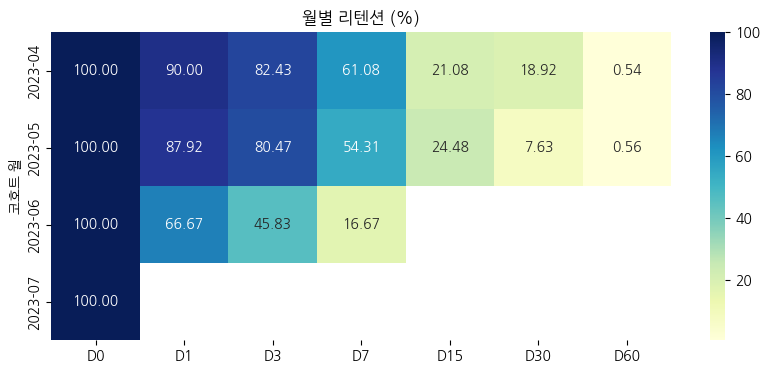

In [62]:
# 투표를 주고 받은 유저의 리텐션

# 투표를 주고 받은 유저들의 전체 활동 로그 추출
cond_voted_and_chosen = tables_combined['user_id'].isin(voted_and_chosen_user_id)
voted_and_chosen_df = tables_combined[cond_voted_and_chosen].copy()

# 투표를 주고 받은 유저들의 리텐션 테이블
voted_and_chosen_retention_rate = get_retention_rate(voted_and_chosen_df)

# 투표를 주고 받은 유저들의 리텐션 히트맵
plt.figure(figsize=(10, 4))

sns.heatmap(voted_and_chosen_retention_rate, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('월별 리텐션 (%)')
plt.ylabel('코호트 월')

plt.show()

In [66]:
# 유입월별 투표 주기만, 받기만, 주고받은 유저 수
def monthly_new_users(df, label):
    d = df.copy()
    d['event_time'] = pd.to_datetime(d['event_time'])
    signup = d.groupby('user_id')['event_time'].min()
    return signup.dt.to_period('M').value_counts().rename(label)

all_months = pd.period_range(tables_combined['event_time'].min(), tables_combined['event_time'].max(), freq='M')

monthly_new_group = pd.concat([
    monthly_new_users(voted_only_df, '주기만'),
    monthly_new_users(chosen_only_df, '받기만'),
    monthly_new_users(voted_and_chosen_df, '주고받은'),
], axis=1).reindex(all_months).fillna(0).astype(int)

display(monthly_new_group)

,주기만,받기만,주고받은
2023-04,0,971,370
2023-05,15,9352,4428
2023-06,8,53,24
2023-07,1,7,1
2023-08,0,0,0
2023-09,1,2,0
2023-10,0,0,0
2023-11,0,1,0
2023-12,0,0,0
2024-01,0,0,0


#### 리텐션 차이 통계적 검정
카이제곱검정, 두 모비율 z검정

In [67]:
# 카이제곱검정
# voted_only_df(주기만 한 유저)는 표본 수가 30명이 안 되어(26명)
# 통계적 가설검정 진행 불가하지만 시험삼아 진행함

# 그룹별 리텐션 함수 지정 (투표 받기만, 주기만, 주고받은)

# 1. 가입일, day_diff 계산 함수
def add_day_diff(df):
    df = df.copy()
    df['event_time'] = pd.to_datetime(df['event_time'])  # datetime 타입으로 변경
    df['signup_date'] = df.groupby('user_id')['event_time'].transform('min')  # 가입일
    df['day_diff'] = (df['event_time'] - df['signup_date']).dt.days  # 경과일
    return df

# 2. 세 그룹에 적용
chosen_only_df = add_day_diff(chosen_only_df)
voted_only_df = add_day_diff(voted_only_df)
voted_and_chosen_df = add_day_diff(voted_and_chosen_df)

# 3. 특정 D-day에 활동한 유저 수 세는 함수
def count_active_users(df, day):
    total_users = df['user_id'].nunique()
    active_users = df[df['day_diff'] == day]['user_id'].nunique()
    return active_users, total_users

# 4. D3, D15, D30에 대해 카이제곱 검정
days_to_check = [3, 15, 30]

for day in days_to_check:
    a1, t1 = count_active_users(chosen_only_df, day)
    a2, t2 = count_active_users(voted_only_df, day)
    a3, t3 = count_active_users(voted_and_chosen_df, day)

    print(f'--- D{day} ---')
    print(f'받기만 한 유저: {a1}/{t1} ({a1/t1*100:.1f}%)')
    print(f'주기만 한 유저: {a2}/{t2} ({a2/t2*100:.1f}%)')
    print(f'주고받은 유저: {a3}/{t3} ({a3/t3*100:.1f}%)')

    table = [
        [a1, t1 - a1],
        [a2, t2 - a2],
        [a3, t3 - a3],
    ]

    chi2, p_value, dof, expected = chi2_contingency(table)
    print(f'p-value: {p_value:.4f}')

    if p_value < 0.05:
        print('→ 유의한 차이 있음')
    else:
        print('→ 유의한 차이 없음')
    print()

--- D3 ---
받기만 한 유저: 2307/10386 (22.2%)
주기만 한 유저: 4/26 (15.4%)
주고받은 유저: 3709/4823 (76.9%)
p-value: 0.0000
→ 유의한 차이 있음

--- D15 ---
받기만 한 유저: 745/10386 (7.2%)
주기만 한 유저: 4/26 (15.4%)
주고받은 유저: 1143/4823 (23.7%)
p-value: 0.0000
→ 유의한 차이 있음

--- D30 ---
받기만 한 유저: 575/10386 (5.5%)
주기만 한 유저: 0/26 (0.0%)
주고받은 유저: 358/4823 (7.4%)
p-value: 0.0000
→ 유의한 차이 있음



In [68]:
# z검정
# 그룹별 리텐션 비교 (투표 받기만 vs 주고받은)

from statsmodels.stats.proportion import proportions_ztest

# 1. 가입일, day_diff 계산 함수
def add_day_diff(df):
    df = df.copy()
    df['event_time'] = pd.to_datetime(df['event_time'])  # datetime 타입으로 변경
    df['signup_date'] = df.groupby('user_id')['event_time'].transform('min')  # 가입일
    df['day_diff'] = (df['event_time'] - df['signup_date']).dt.days  # 경과일
    return df

# 2. 두 그룹에 적용 (voted_only_df 제외)
chosen_only_df = add_day_diff(chosen_only_df)
voted_and_chosen_df = add_day_diff(voted_and_chosen_df)

# 3. 특정 D-day에 활동한 유저 수 세는 함수
def count_active_users(df, day):
    total_users = df['user_id'].nunique()
    active_users = df[df['day_diff'] == day]['user_id'].nunique()
    return active_users, total_users

# 4. D3, D15, D30에 대해 z검정
days_to_check = [1, 3, 15, 30]

for day in days_to_check:
    a1, t1 = count_active_users(chosen_only_df, day)
    a2, t2 = count_active_users(voted_and_chosen_df, day)

    print(f'--- D{day} ---')
    print(f'받기만 한 유저: {a1}/{t1} ({a1/t1*100:.1f}%)')
    print(f'주고받은 유저: {a2}/{t2} ({a2/t2*100:.1f}%)')

    stat, p_value = proportions_ztest([a1, a2], [t1, t2])
    print(f'z-statistic: {stat:.3f}, p-value: {p_value:.4f}')

    if p_value < 0.05:
        print('→ 유의한 차이 있음')
    else:
        print('→ 유의한 차이 없음')
    print()

--- D1 ---
받기만 한 유저: 3978/10386 (38.3%)
주고받은 유저: 4224/4823 (87.6%)
z-statistic: -56.737, p-value: 0.0000
→ 유의한 차이 있음

--- D3 ---
받기만 한 유저: 2307/10386 (22.2%)
주고받은 유저: 3709/4823 (76.9%)
z-statistic: -64.188, p-value: 0.0000
→ 유의한 차이 있음

--- D15 ---
받기만 한 유저: 745/10386 (7.2%)
주고받은 유저: 1143/4823 (23.7%)
z-statistic: -28.763, p-value: 0.0000
→ 유의한 차이 있음

--- D30 ---
받기만 한 유저: 575/10386 (5.5%)
주고받은 유저: 358/4823 (7.4%)
z-statistic: -4.512, p-value: 0.0000
→ 유의한 차이 있음



### Give & Take 불균형이 실제로 이탈로 이어지는지 확인

1. 이탈 기준: 28일 연속 비활성 이후 재유입하지 않은 유저
    * 이탈 기준은 Google Play Apps & Games 공식 블로그에서 확인한 내용을 토대로 설정    
        > We reserve the term churned for users who haven’t shown up in 28 days or more. Differentiating between lapsed and churned users will help you identify unique behavioral patterns associated with short-term and long-term disengagement.  

        > '이탈’이라는 용어는 28일 이상 로그인하지 않은 사용자들을 지칭합니다. 이탈한 사용자와 ‘일시적 비활성’된 사용자를 구분함으로써, 단기적/장기적으로 서비스를 이용하지 않는 사용자들의 행동 패턴을 더 명확하게 파악할 수 있습니다.

        출처: https://medium.com/googleplaydev/the-user-journey-disengagement-and-reactivation-6e34fe04694a

2. 파생 변수 설계
    * give_count: 투표한 수
    * take_count: 투표받은 수
    * take_ratio(투표받은 비율): Take / (Take + Give)(받은 게 많을 경우 0.5 초과)
    * 상호투표 관계 수
    * 일방 Give 투표 관계 수
    * 일방 Take 투표 관계 수
3. 일자 기준
    * 일별
    * 또는 구간별(D1, D3, D7, D14 ...))
    * 불균형과 이탈의 관계를 잘 보여주는 기준으로 선택
4. 가설
    * Q1. 이탈 시점 기준, D-14~D-0까지 Give는 유지되는데 Take가 감소하는 패턴이 나타나는가?  
    * Q2. 상호적 관계 비율: 유입~이탈 기간 동안 상호적 관계, 일방적 Give 관계, 일방적 Take 관계의 비율이 증가하는가?
        * 특정 시점 당시의 관계 비율을 확인
        * 어느 정도까지가 상호적 관계로 볼 것인지 기준을 세울 필요 있음(이건 관계의 give-take 개수 비율 보고 판단)
5. 시각화
    1. 이탈 D-30~D-0 까지의 유저 평균 상호적 투표 관계 수
    2. 이탈 D-30~D-0 까지의 유저 평균 Take/Give(둘 다 함께 떨어지는 경우 방어)
6. 통계적 가설검정 - 로지스틱 회귀분석
    1. 상호 관계가 감소할 경우 or 상호성이 감소할 경우 이탈로 이어질 가능성이 높아지는지 확인


In [69]:
tables_combined

,user_id,event_time
0,1446852,2023-05-27 00:00:00
1,1446852,2023-05-28 00:00:00
2,1446852,2023-05-29 00:00:00
3,1446852,2023-05-30 00:00:00
4,1446852,2023-06-03 00:00:00
...,...,...
20678032,1001607,2024-05-07 11:29:07
20678033,855525,2024-05-08 01:34:56
20678034,855525,2024-05-08 01:35:02
20678035,855525,2024-05-08 01:36:00


In [70]:
# 이탈 유저 추출
# 28일 연속 비활성 이후 재유입하지 않은 유저

# 유저별 마지막 활동일 추출
last_activity = tables_combined.groupby('user_id')['event_time'].max().dt.normalize()

# 기준 시점: 데이터의 마지막 날짜
reference_date = tables_combined['event_time'].max().normalize()

# 마지막 활동 이후 28일 이상 지난 유저
inactive_days = (reference_date - last_activity).dt.days
churned_users = last_activity[inactive_days >= 28].reset_index()
churned_users = churned_users.rename(columns={'event_time': 'last_active_date'})
churned_users_list = churned_users['user_id']

engaged_user_count = tables_combined['user_id'].nunique()

print(f'활동 기록이 있는 유저 수: {engaged_user_count:,}')
print(f'이탈 유저 수: {len(churned_users):,}')
print(f'이탈 유저 비율: {len(churned_users) / engaged_user_count:,.2%}')

print('\n--- 이탈 유저와 마지막 접속 일자 ---')
churned_users.head()

활동 기록이 있는 유저 수: 653,085
이탈 유저 수: 651,790
이탈 유저 비율: 99.80%

--- 이탈 유저와 마지막 접속 일자 ---


,user_id,last_active_date
0,831962,2023-07-13
1,832151,2023-05-29
2,832340,2023-06-06
3,832986,2023-05-28
4,833024,2023-05-28


In [71]:
# 이탈 유저 추출
# 90일 연속 비활성 이후 재유입하지 않은 유저

# 유저별 마지막 활동일 추출
last_activity = tables_combined.groupby('user_id')['event_time'].max().dt.normalize()

# 기준 시점: 데이터의 마지막 날짜
reference_date = tables_combined['event_time'].max().normalize()

# 마지막 활동 이후 90일 이상 지난 유저
inactive_days_90 = (reference_date - last_activity).dt.days
churned_users_90 = last_activity[inactive_days_90 >= 90].reset_index()
churned_users_90 = churned_users_90.rename(columns={'event_time': 'last_active_date'})
churned_users_90_list = churned_users_90['user_id']

engaged_user_count = tables_combined['user_id'].nunique()

print(f'활동 기록이 있는 유저 수: {engaged_user_count:,}')
print(f'이탈 유저 수: {len(churned_users):,}')
print(f'이탈 유저 비율: {len(churned_users) / engaged_user_count:,.2%}')

print('\n--- 이탈 유저와 마지막 접속 일자 ---')
churned_users.head()

활동 기록이 있는 유저 수: 653,085
이탈 유저 수: 651,790
이탈 유저 비율: 99.80%

--- 이탈 유저와 마지막 접속 일자 ---


,user_id,last_active_date
0,831962,2023-07-13
1,832151,2023-05-29
2,832340,2023-06-06
3,832986,2023-05-28
4,833024,2023-05-28


In [72]:
# 날짜를 년-월-일 형태로 변경

accounts_userquestionrecord_revised = accounts_userquestionrecord.copy()
accounts_userquestionrecord_revised['created_at'] = pd.to_datetime(accounts_userquestionrecord_revised['created_at']).dt.normalize()
accounts_userquestionrecord_revised['answer_updated_at'] = pd.to_datetime(accounts_userquestionrecord_revised['answer_updated_at']).dt.normalize()

accounts_userquestionrecord_revised.head()

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
0,771777,C,2023-04-28,849469,252,849436,998458,0,N,2023-04-28,0,0
1,771800,C,2023-04-28,849446,244,849436,998459,0,N,2023-04-28,0,0
2,771812,C,2023-04-28,849454,183,849436,998460,1,N,2023-04-28,0,0
3,771828,C,2023-04-28,847375,101,849436,998461,0,N,2023-04-28,0,0
4,771851,C,2023-04-28,849477,209,849436,998462,1,N,2023-04-28,0,0


In [73]:
# give 수, take 수, 누적 give 수, 누적 take 수 파생변수 생성

# 페어 지정
# A -> B, B -> A 관계 모두 하나의 페어로 설정할 수 있도록 함

accounts_userquestionrecord_revised['pair_1'] = (
    accounts_userquestionrecord_revised[['user_id', 'chosen_user_id']]
    .min(axis=1)
)

accounts_userquestionrecord_revised['pair_2'] = (
    accounts_userquestionrecord_revised[['user_id', 'chosen_user_id']]
    .max(axis=1)
)

# 1. 이탈 유저가 투표한(Give) 기록
give_side = pd.merge(
    accounts_userquestionrecord_revised,
    churned_users,
    on='user_id',
    how='inner'    # 이탈하지 않은 유저는 결측으로 나타나므로 제외
)

give_side['role'] = 'give'
give_side['churned_user_id'] = give_side['user_id']
give_side['other_user_id'] = give_side['chosen_user_id']
give_side['action_date'] = give_side['created_at']


# 2. 이탈 유저가 투표받은(Take) 기록
take_side = pd.merge(
    accounts_userquestionrecord_revised,
    churned_users.rename(columns={'user_id': 'chosen_user_id'}),
    on='chosen_user_id',
    how='inner'    # 이탈하지 않은 유저는 결측으로 나타나므로 제외
)

take_side['role'] = 'take'
take_side['churned_user_id'] = take_side['chosen_user_id']
take_side['other_user_id'] = take_side['user_id']
take_side['action_date'] = take_side['created_at']


# 3. Give + Take 합치기
cols = [
    'churned_user_id',
    'other_user_id',
    'action_date',
    'role',
    'last_active_date',
    'pair_1',
    'pair_2'
]

churn_relations = pd.concat(
    [give_side[cols], take_side[cols]],
    ignore_index=True
)


# 4. 이탈일까지 며칠 전인지 계산
churn_relations['days_before_churn'] = (
    churn_relations['last_active_date']
    - churn_relations['action_date']
).dt.days


# 5. 기간 구분
churn_relations['period'] = pd.cut(
    churn_relations['days_before_churn'],
    bins=[-1, 7, 14, 21, 28, float('inf')],
    labels=[
        'D-7~0',
        'D-14~-8',
        'D-21~-15',
        'D-28~-22',
        'over D-28'
    ]
)

churn_relations.head()

,churned_user_id,other_user_id,action_date,role,last_active_date,pair_1,pair_2,days_before_churn,period
0,849436,849469,2023-04-28,give,2023-06-06,849436,849469,39,over D-28
1,849436,849446,2023-04-28,give,2023-06-06,849436,849446,39,over D-28
2,849436,849454,2023-04-28,give,2023-06-06,849436,849454,39,over D-28
3,849436,847375,2023-04-28,give,2023-06-06,847375,849436,39,over D-28
4,849436,849477,2023-04-28,give,2023-06-06,849436,849477,39,over D-28


#### 이탈 전 일자별 투표받은 비율 변화

##### 모든 유저의 합

In [74]:
# 모든 데이터 sum: 일자별 give 수 합, take 수 합, 비율

daily = (
    churn_relations
    .groupby('days_before_churn')
    .agg(
        give=('role', lambda x: (x == 'give').sum()),
        take=('role', lambda x: (x == 'take').sum())
    )
    .reset_index()
)

daily['take_ratio'] = (
    daily['take'] / (daily['give'] + daily['take'])
)

daily.head()

,days_before_churn,give,take,take_ratio
0,-365,0,1,1.00
1,-363,0,1,1.00
2,-362,0,1,1.00
3,-353,0,4,1.00
4,-352,0,1,1.00


In [75]:
# 모든 데이터 sum: 이탈 전 100일 ~ 이탈일 데이터 추출
daily_100 = (
    churn_relations[
        churn_relations['days_before_churn'].between(0, 100)
    ]
    .groupby('days_before_churn')
    .agg(
        give=('role', lambda x: (x == 'give').sum()),
        take=('role', lambda x: (x == 'take').sum())
    )
    .reset_index()
)

daily_100['take_ratio'] = (
    daily_100['take'] /
    (daily_100['give'] + daily_100['take'])
)

daily_100.head()

,days_before_churn,give,take,take_ratio
0,0,30554,31389,0.51
1,1,18965,30315,0.62
2,2,24037,31069,0.56
3,3,26609,32542,0.55
4,4,29812,31939,0.52


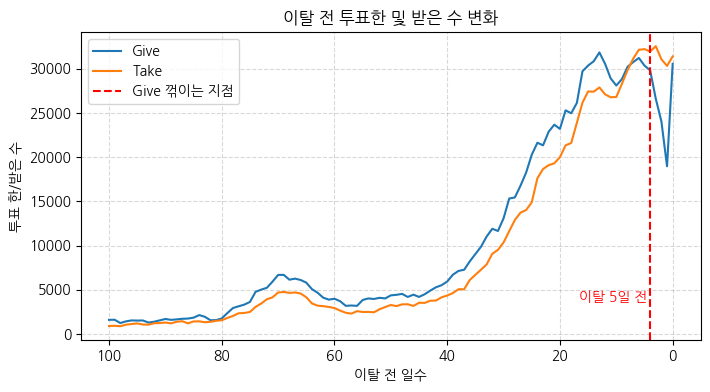

In [76]:
# 모든 데이터 sum: 이탈 전 투표한 및 받은 수 변화
plt.figure(figsize=(8, 4))

plt.plot(
    daily_100['days_before_churn'],
    daily_100['give'],
    label='Give'
)

plt.plot(
    daily_100['days_before_churn'],
    daily_100['take'],
    label='Take'
)

# Give가 꺾이는 지점 표시
plt.axvline(
    x=4,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Give 꺾이는 지점'
)

plt.text(
    4.5,  # 선 근처의 적절한 X 좌표
    plt.ylim()[1] * 0.1,  # Y축 최대값 부근 (데이터 스케일에 맞춤)
    '이탈 5일 전',
    color='red',
    ha='right',
    va='bottom',
)

plt.gca().invert_xaxis()

plt.xlabel('이탈 전 일수')
plt.ylabel('투표 한/받은 수')
plt.title('이탈 전 투표한 및 받은 수 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

##### 유저당 평균

In [77]:
daily_user_stats = (
    churn_relations
    .groupby(['days_before_churn', 'churned_user_id'])
    .agg(
        give=('role', lambda x: (x == 'give').sum()),
        take=('role', lambda x: (x == 'take').sum())
    )
    .reset_index()
)

In [78]:
# 그날 활동이 있었던 유저들의 (give+take) 분포 확인
active = daily_user_stats[daily_user_stats['give'] + daily_user_stats['take'] > 0]
(active['give'] + active['take']).describe()
(active['give'] + active['take']).quantile([0.5, 0.9, 0.99])

,0
0.50,3.00
0.90,39.00
0.99,134.00


give cap (P99): 116.0, take cap (P99): 74.0
Give 최고점: 이탈 전 13일 / Give 하락 지점: 이탈 전 6일


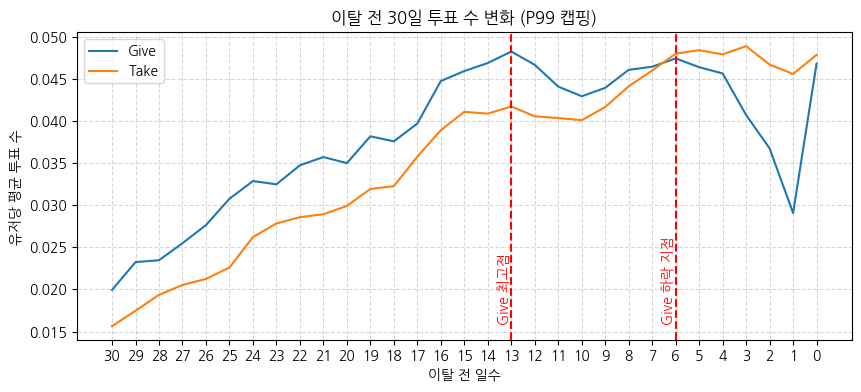

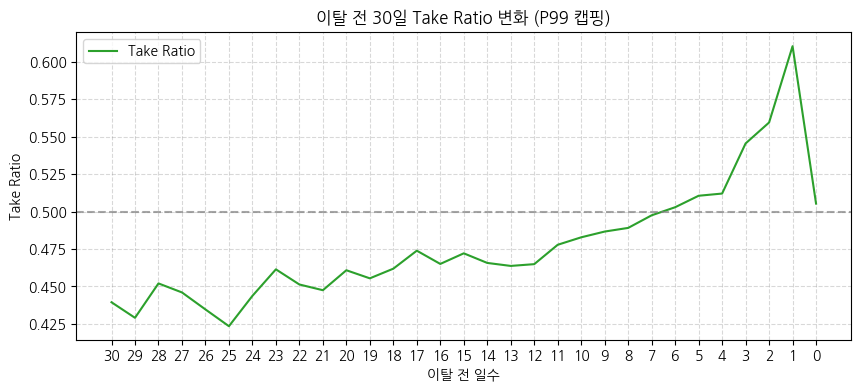

,days_before_churn,give,take,take_ratio
0,0,0.05,0.05,0.51
1,1,0.03,0.05,0.61
2,2,0.04,0.05,0.56
3,3,0.04,0.05,0.55
4,4,0.05,0.05,0.51


In [79]:
# ❌ 유저당 평균: 일자별 give 수, take 수 (P99 캡핑)

# ===== 이탈 전 0~30일 (P99 winsorize) =====

# 0~30일 구간으로 필터링
daily_user_stats_30 = daily_user_stats[
    daily_user_stats['days_before_churn'].between(0, 30)
].copy()

# give/take 각각 99th percentile로 상한 설정 (30일 구간 내, 활동 있었던 값 기준)
give_cap_30 = daily_user_stats_30.loc[daily_user_stats_30['give'] > 0, 'give'].quantile(0.99)
take_cap_30 = daily_user_stats_30.loc[daily_user_stats_30['take'] > 0, 'take'].quantile(0.99)
print(f'give cap (P99): {give_cap_30}, take cap (P99): {take_cap_30}')

daily_user_stats_30_capped = daily_user_stats_30.copy()
daily_user_stats_30_capped['give'] = daily_user_stats_30_capped['give'].clip(upper=give_cap_30)
daily_user_stats_30_capped['take'] = daily_user_stats_30_capped['take'].clip(upper=take_cap_30)

# 전체 이탈 유저 수 (고정 분모, 비활동 유저 포함)
total_churned_users = churned_users_list.nunique()

# 일자별 캡핑된 합계
daily_sum_capped_30 = (
    daily_user_stats_30_capped
    .groupby('days_before_churn')
    .agg(give_sum=('give', 'sum'), take_sum=('take', 'sum'))
    .reset_index()
)

# 유저당 평균 give/take (전체 이탈 유저 기준)
daily_sum_capped_30['give'] = daily_sum_capped_30['give_sum'] / total_churned_users
daily_sum_capped_30['take'] = daily_sum_capped_30['take_sum'] / total_churned_users

# take_ratio (캡핑된 합산 기준)
daily_sum_capped_30['take_ratio'] = (
    daily_sum_capped_30['take_sum'] / (daily_sum_capped_30['give_sum'] + daily_sum_capped_30['take_sum'])
)

daily_avg_capped_30 = daily_sum_capped_30[['days_before_churn', 'give', 'take', 'take_ratio']]

xticks_30 = range(0, 31, 1)

# give가 꺾이는 지점 자동 탐지: 30일 -> 0일(시간 순) 중 give가 최고점을 찍는 날
time_ordered = daily_avg_capped_30.sort_values('days_before_churn', ascending=False)
peak_day = time_ordered.loc[time_ordered['give'].idxmax(), 'days_before_churn']
decline_day = 6  # 하락이 실제로 시작되는 지점 (수동 지정, 캡핑 없는 버전과 동일 기준 유지)
print(f'Give 최고점: 이탈 전 {peak_day}일 / Give 하락 지점: 이탈 전 {decline_day}일')

# 시각화 1 - 투표 수
plt.figure(figsize=(10, 4))
plt.plot(daily_avg_capped_30['days_before_churn'], daily_avg_capped_30['give'], label='Give')
plt.plot(daily_avg_capped_30['days_before_churn'], daily_avg_capped_30['take'], label='Take')

y_min, y_max = plt.ylim()
text_y = y_min + (y_max - y_min) * 0.05

plt.axvline(x=peak_day, color='red', linestyle='--', linewidth=1.5)
plt.text(peak_day, text_y, 'Give 최고점', color='red', rotation=90, ha='right', va='bottom')

plt.axvline(x=decline_day, color='red', linestyle='--', linewidth=1.5)
plt.text(decline_day, text_y, 'Give 하락 지점', color='red', rotation=90, ha='right', va='bottom')

plt.xticks(xticks_30)
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('유저당 평균 투표 수')
plt.title('이탈 전 30일 투표 수 변화 (P99 캡핑)')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

# 시각화 2 - Take Ratio
plt.figure(figsize=(10, 4))
plt.plot(daily_avg_capped_30['days_before_churn'], daily_avg_capped_30['take_ratio'], color='tab:green', label='Take Ratio')
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.7)
plt.xticks(xticks_30)
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('Take Ratio')
plt.title('이탈 전 30일 Take Ratio 변화 (P99 캡핑)')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

daily_avg_capped_30.head()

Give 최고점: 이탈 전 13일 / Give 하락 지점: 이탈 전 6일


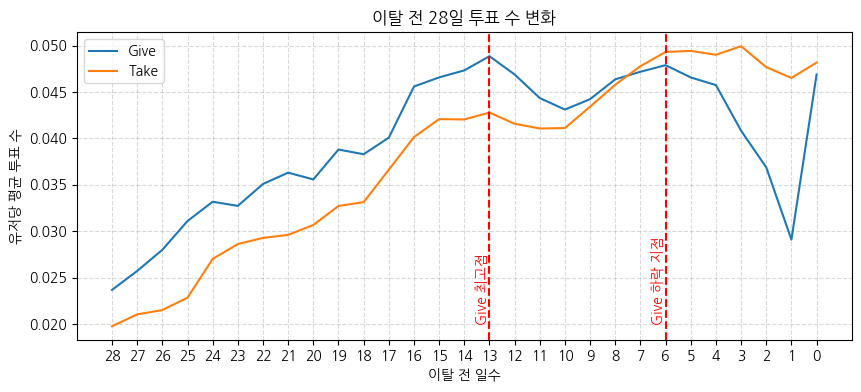

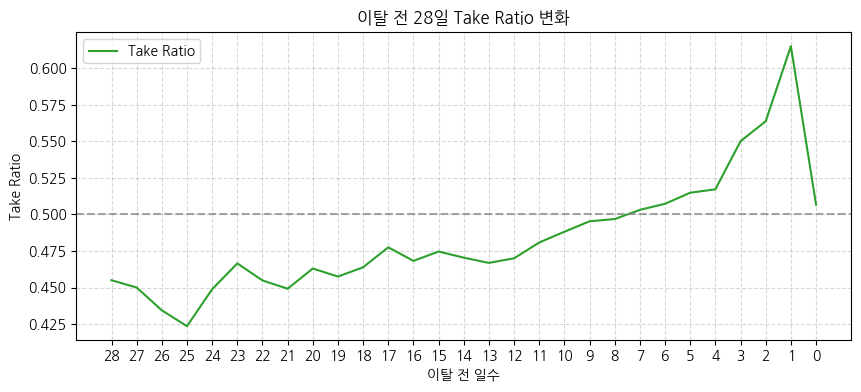

,days_before_churn,give,take,take_ratio
0,0,0.05,0.05,0.51
1,1,0.03,0.05,0.62
2,2,0.04,0.05,0.56
3,3,0.04,0.05,0.55
4,4,0.05,0.05,0.52


In [80]:
# ⭐ 유저당 평균: 일자별 give 수, take 수 (캡핑 X)

# ===== 이탈 전 0~28일 =====

# 0~28일 구간으로 필터링
daily_user_stats_28 = daily_user_stats[
    daily_user_stats['days_before_churn'].between(0, 28)
].copy()

# 전체 이탈 유저 수 (고정 분모, 비활동 유저 포함)
total_churned_users = churned_users_list.nunique()

# 일자별 give/take 합계
daily_sum_raw_28 = (
    daily_user_stats_28
    .groupby('days_before_churn')
    .agg(give_sum=('give', 'sum'), take_sum=('take', 'sum'))
    .reset_index()
)

# 유저당 평균 give/take (전체 이탈 유저 기준)
daily_sum_raw_28['give'] = daily_sum_raw_28['give_sum'] / total_churned_users
daily_sum_raw_28['take'] = daily_sum_raw_28['take_sum'] / total_churned_users

# take_ratio (합산 기준)
daily_sum_raw_28['take_ratio'] = (
    daily_sum_raw_28['take_sum'] / (daily_sum_raw_28['give_sum'] + daily_sum_raw_28['take_sum'])
)

daily_avg_raw_28 = daily_sum_raw_28[['days_before_churn', 'give', 'take', 'take_ratio']]

xticks_28 = range(0, 29, 1)

# give가 꺾이는 지점 자동 탐지: 28일 -> 0일(시간 순) 중 give가 최고점을 찍는 날
time_ordered = daily_avg_raw_28.sort_values('days_before_churn', ascending=False)
peak_day = time_ordered.loc[time_ordered['give'].idxmax(), 'days_before_churn']
decline_day = 6  # 하락이 실제로 시작되는 지점 (수동 지정)
print(f'Give 최고점: 이탈 전 {peak_day}일 / Give 하락 지점: 이탈 전 {decline_day}일')

# 시각화 1 - 투표 수
plt.figure(figsize=(10, 4))
plt.plot(daily_avg_raw_28['days_before_churn'], daily_avg_raw_28['give'], label='Give')
plt.plot(daily_avg_raw_28['days_before_churn'], daily_avg_raw_28['take'], label='Take')

y_min, y_max = plt.ylim()
text_y = y_min + (y_max - y_min) * 0.05

plt.axvline(x=peak_day, color='red', linestyle='--', linewidth=1.5)
plt.text(peak_day, text_y, 'Give 최고점', color='red', rotation=90, ha='right', va='bottom')

plt.axvline(x=decline_day, color='red', linestyle='--', linewidth=1.5)
plt.text(decline_day, text_y, 'Give 하락 지점', color='red', rotation=90, ha='right', va='bottom')

plt.xticks(xticks_28)
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('유저당 평균 투표 수')
plt.title('이탈 전 28일 투표 수 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

# 시각화 2 - Take Ratio
plt.figure(figsize=(10, 4))
plt.plot(daily_avg_raw_28['days_before_churn'], daily_avg_raw_28['take_ratio'], color='tab:green', label='Take Ratio')
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.7)
plt.xticks(xticks_28)
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('Take Ratio')
plt.title('이탈 전 28일 Take Ratio 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

daily_avg_raw_28.head()

#### 이탈 전 일자 구간별 투표 관계 수 변화

In [81]:
churn_relations.head()

,churned_user_id,other_user_id,action_date,role,last_active_date,pair_1,pair_2,days_before_churn,period
0,849436,849469,2023-04-28,give,2023-06-06,849436,849469,39,over D-28
1,849436,849446,2023-04-28,give,2023-06-06,849436,849446,39,over D-28
2,849436,849454,2023-04-28,give,2023-06-06,849436,849454,39,over D-28
3,849436,847375,2023-04-28,give,2023-06-06,847375,849436,39,over D-28
4,849436,849477,2023-04-28,give,2023-06-06,849436,849477,39,over D-28


In [82]:
# 투표 유저 조합 별 투표 수, 투표 받은 수

pair_period = (
    churn_relations
    .groupby([
        'churned_user_id',
        'period',
        'pair_1',
        'pair_2'
    ], observed=True)
    .agg(
        give_count=('role', lambda x: (x == 'give').sum()),
        take_count=('role', lambda x: (x == 'take').sum())
    )
    .reset_index()
)

pair_period['total_interaction'] = (
    pair_period['give_count'] +
    pair_period['take_count']
)

pair_period['take_ratio'] = (
    pair_period['take_count'] /
    pair_period['total_interaction']
)

pair_period.head()

,churned_user_id,period,pair_1,pair_2,give_count,take_count,total_interaction,take_ratio
0,833112,over D-28,833112,885881,0,2,2,1.00
1,833203,over D-28,833203,855110,0,5,5,1.00
2,833203,over D-28,833203,855728,0,1,1,1.00
3,833203,over D-28,833203,855809,0,97,97,1.00
4,833203,over D-28,833203,856062,0,1,1,1.00


In [83]:
# 관계 설정 기준을 정하기 위해 기술 통계 확인

pair_period['take_ratio'].describe()

,take_ratio
count,377334.00
mean,0.45
std,0.43
min,0.00
25%,0.00
50%,0.38
75%,1.00
max,1.00


In [84]:
# 관계 설정 기준을 정하기 위해 구간별 확인
# 백분위수

pair_period['take_ratio'].quantile(
    [0, .1, .2, .25, .3, .4, .45, .5, .6, .7, .75, .8, .9, 1]
)

,take_ratio
0.00,0.00
0.10,0.00
0.20,0.00
0.25,0.00
0.30,0.00
0.40,0.11
0.45,0.25
0.50,0.38
0.60,0.60
0.70,0.86


In [85]:
# 관계 설정 기준을 정하기 위해 구간별 확인
# 구간별 분포
pd.cut(
    pair_period['take_ratio'],
    bins=[0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1],
).value_counts().sort_index()

,count
take_ratio,
"(0.0, 0.1]",4515
"(0.1, 0.2]",13026
"(0.2, 0.3]",12140
"(0.3, 0.4]",17864
"(0.4, 0.5]",26725
"(0.5, 0.6]",9708
"(0.6, 0.7]",15011
"(0.7, 0.8]",14785
"(0.8, 0.9]",9680


In [86]:
# take ratio가 0또는 1 제외한 값들의 백분위수 확인

# take ratio가 0또는 1 제외한 값 추출
not_0 = pair_period['take_ratio'] != 0
not_1 = pair_period['take_ratio'] != 1

pair_period_not_0_or_1 = pair_period[not_0 & not_1]

# 백분위수
pair_period_not_0_or_1['take_ratio'].quantile(
    [0, .1, .2, .25, .3, .4, .5, .6, .7, .75, .8, .9, 1]
)

,take_ratio
0.00,0.00
0.10,0.17
0.20,0.25
0.25,0.33
0.30,0.33
0.40,0.44
0.50,0.50
0.60,0.55
0.70,0.67
0.75,0.67


* 일방적 give 관계, give 우세 관계, 상호관계, take 우세 관계, 일방적 take 관계 구간 설정
| Take Ratio | 투표 관계 유형 1 | 투표 관계 유형 2 |
| :---: | :--- | :--- |
| 0 ~ 0.15 | 일방적 Give 관계 | Give 우세 관계 |
| 0.16 ~ 0.33 | Give 우세 관계 | Give 우세 관계 |
| 0.34 ~ 0.66 | 상호관계 | 상호관계 |
| 0.67 ~ 0.85 | Take 우세 관계 | Take 우세 관계 |
| 0.86 ~ 1 | 일방적 Take 관계 | Take 우세 관계 |


##### 투표 관계 유형 1 / 모든 유저의 합

In [87]:
# 투표 관계 유형 라벨링
pair_period['relation_type'] = pd.cut(
    pair_period['take_ratio'],
    bins=[-0.01, 0.15, 0.33, 0.66, 0.85, 1],
    labels=[
        '일방적 Give 관계',
        'Give 우세 관계',
        '상호관계',
        'Take 우세 관계',
        '일방적 Take 관계'
    ]
)

pair_period.head()

,churned_user_id,period,pair_1,pair_2,give_count,take_count,total_interaction,take_ratio,relation_type
0,833112,over D-28,833112,885881,0,2,2,1.00,일방적 Take 관계
1,833203,over D-28,833203,855110,0,5,5,1.00,일방적 Take 관계
2,833203,over D-28,833203,855728,0,1,1,1.00,일방적 Take 관계
3,833203,over D-28,833203,855809,0,97,97,1.00,일방적 Take 관계
4,833203,over D-28,833203,856062,0,1,1,1.00,일방적 Take 관계


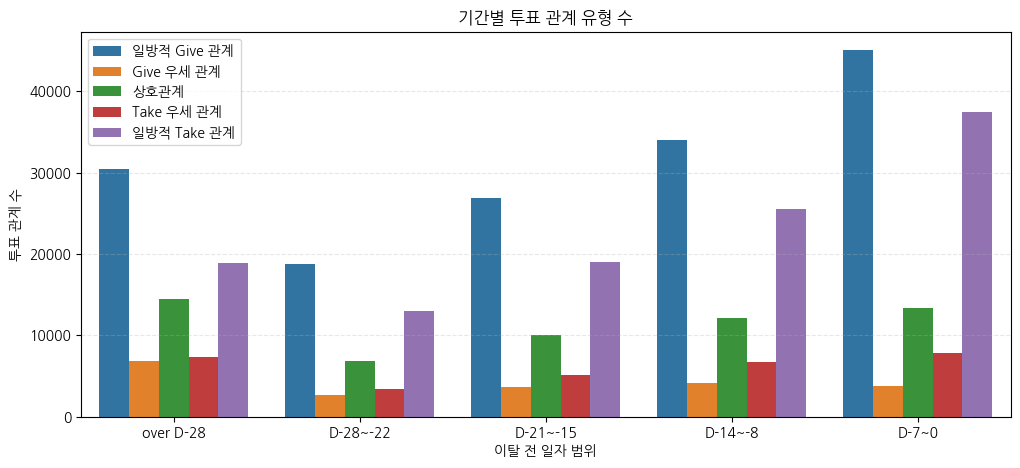

In [88]:
# 기간별 투표 관계 유형의 비율 변화

period_order = [
    'over D-28',
    'D-28~-22',
    'D-21~-15',
    'D-14~-8',
    'D-7~0'
]

pair_period['period'] = pd.Categorical(
    pair_period['period'],
    categories=period_order,
    ordered=True
)

# 기간별 투표 관계 수
relation_count = (
    pair_period
    .groupby(['period', 'relation_type'], observed=True)
    .size()
    .reset_index(name='count')
)

# 시각화
plt.figure(figsize=(12, 5))

sns.barplot(
    data=relation_count,
    x='period',
    y='count',
    hue='relation_type'
)

plt.xlabel('이탈 전 일자 범위')
plt.ylabel('투표 관계 수')
plt.title('기간별 투표 관계 유형 수')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.legend(title=None)

plt.show()

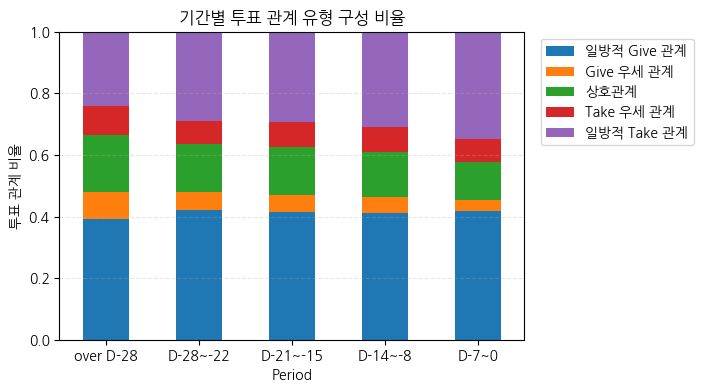

In [89]:
# 기간별 투표 관계 유형 비율 계산
relation_ratio = relation_count.copy()

# groupby 시 observed=False 명시하여 FutureWarning 해결
relation_ratio['ratio'] = (
    relation_ratio['count'] /
    relation_ratio.groupby('period', observed=False)['count'].transform('sum')
)

# 100% 누적 막대그래프용 Pivot Table 생성
pivot = relation_ratio.pivot(
    index='period',
    columns='relation_type',
    values='ratio'
)

# sns.barplot.plot 대신 pivot.plot 사용
pivot.plot(
    kind='bar',
    stacked=True,
    figsize=(6, 4)
)

plt.xlabel('Period')
plt.ylabel('투표 관계 비율')
plt.title('기간별 투표 관계 유형 구성 비율')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

##### 투표 관계 유형 2 / 모든 유저의 합

In [90]:
# 투표 관계 유형 라벨링 (3구간)
pair_period['relation_type_2'] = pd.cut(
    pair_period['take_ratio'],
    bins=[-0.01, 0.33, 0.66, 1],
    labels=[
        'Give 우세 관계',
        '상호관계',
        'Take 우세 관계'
    ]
)

pair_period.head()

,churned_user_id,period,pair_1,pair_2,give_count,take_count,total_interaction,take_ratio,relation_type,relation_type_2
0,833112,over D-28,833112,885881,0,2,2,1.00,일방적 Take 관계,Take 우세 관계
1,833203,over D-28,833203,855110,0,5,5,1.00,일방적 Take 관계,Take 우세 관계
2,833203,over D-28,833203,855728,0,1,1,1.00,일방적 Take 관계,Take 우세 관계
3,833203,over D-28,833203,855809,0,97,97,1.00,일방적 Take 관계,Take 우세 관계
4,833203,over D-28,833203,856062,0,1,1,1.00,일방적 Take 관계,Take 우세 관계


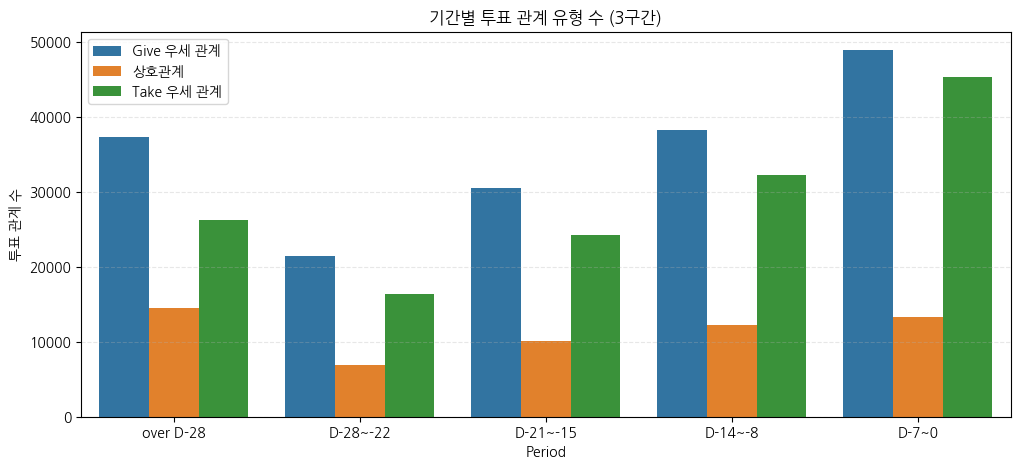

In [91]:
# 기간별 투표 관계 유형의 비율 변화 (3구간)

period_order = [
    'over D-28',
    'D-28~-22',
    'D-21~-15',
    'D-14~-8',
    'D-7~0'
]

pair_period['period'] = pd.Categorical(
    pair_period['period'],
    categories=period_order,
    ordered=True
)

# 기간별 투표 관계 수
relation_count_2 = (
    pair_period
    .groupby(['period', 'relation_type_2'], observed=True)
    .size()
    .reset_index(name='count')
)

# 시각화
plt.figure(figsize=(12, 5))

sns.barplot(
    data=relation_count_2,
    x='period',
    y='count',
    hue='relation_type_2'
)

plt.xlabel('Period')
plt.ylabel('투표 관계 수')
plt.title('기간별 투표 관계 유형 수 (3구간)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.legend(title=None)

plt.show()

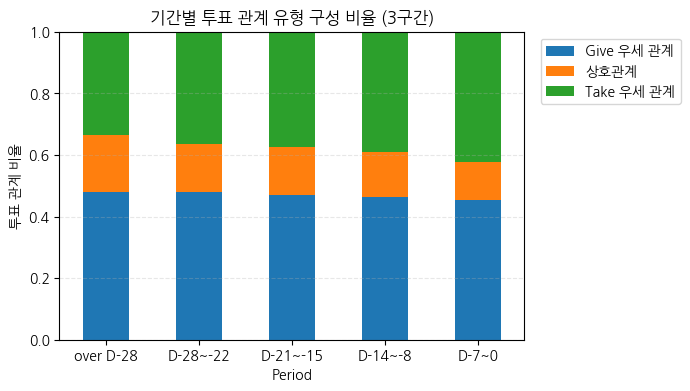

In [92]:
# 기간별 투표 관계 유형 비율 계산 (3구간)
relation_ratio_2 = relation_count_2.copy()

# groupby 시 observed=False 명시하여 FutureWarning 해결
relation_ratio_2['ratio'] = (
    relation_ratio_2['count'] /
    relation_ratio_2.groupby('period', observed=False)['count'].transform('sum')
)

# 100% 누적 막대그래프용 Pivot Table 생성
pivot_2 = relation_ratio_2.pivot(
    index='period',
    columns='relation_type_2',
    values='ratio'
)

pivot_2.plot(
    kind='bar',
    stacked=True,
    figsize=(6, 4)
)

plt.xlabel('Period')
plt.ylabel('투표 관계 비율')
plt.title('기간별 투표 관계 유형 구성 비율 (3구간)')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

##### 모든 유저 기준 일자별 투표 관계 수

,period,relation_count
0,over D-28,77959
1,D-28~-22,44621
2,D-21~-15,64676
3,D-14~-8,82555
4,D-7~0,107523


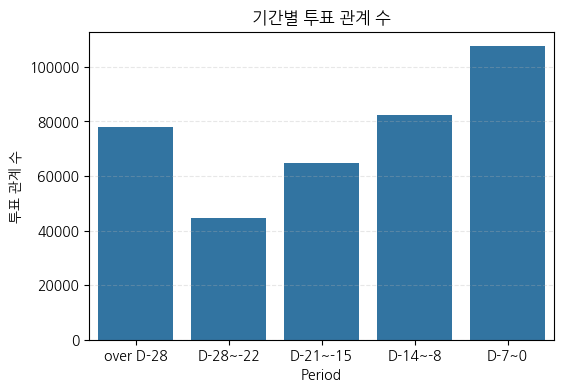

In [93]:
# 기간별 단순 투표 관계 수 (give/take 구분 없이, 그 기간에 존재했던 pair 수)

period_relation_count = (
    pair_period
    .groupby('period', observed=True)
    .size()
    .reset_index(name='relation_count')
)

display(period_relation_count)

# 시각화
plt.figure(figsize=(6, 4))
sns.barplot(
    data=period_relation_count,
    x='period',
    y='relation_count',
    color='tab:blue'
)
plt.xlabel('Period')
plt.ylabel('투표 관계 수')
plt.title('기간별 투표 관계 수')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.show()

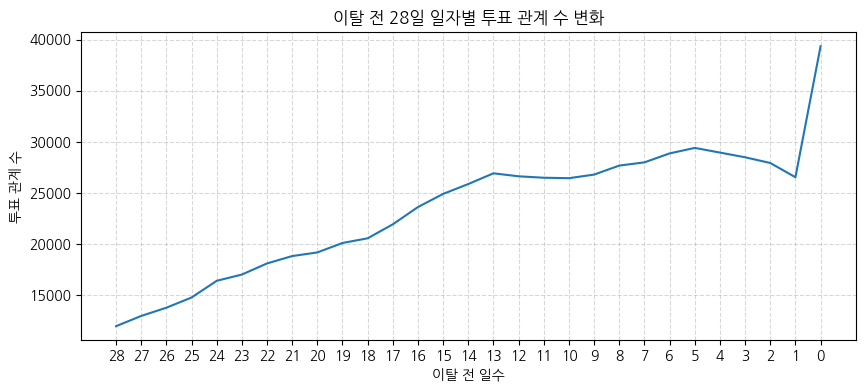

In [94]:
# 일자별 투표 관계 수 (0~30일, give/take 구분 없이 그날 상호작용이 있었던 pair 총 개수)

daily_pair_count = (
    churn_relations[churn_relations['days_before_churn'].between(0, 28)]
    .groupby(['days_before_churn', 'churned_user_id', 'pair_1', 'pair_2'], observed=True)
    .size()
    .reset_index(name='dummy')
    .groupby('days_before_churn')
    .size()
    .reset_index(name='relation_count')
)

plt.figure(figsize=(10, 4))
plt.plot(daily_pair_count['days_before_churn'], daily_pair_count['relation_count'])
plt.xticks(range(0, 29, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('투표 관계 수')
plt.title('이탈 전 28일 일자별 투표 관계 수 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.show()

##### 투표 관계 유형 1 / 유저당 평균

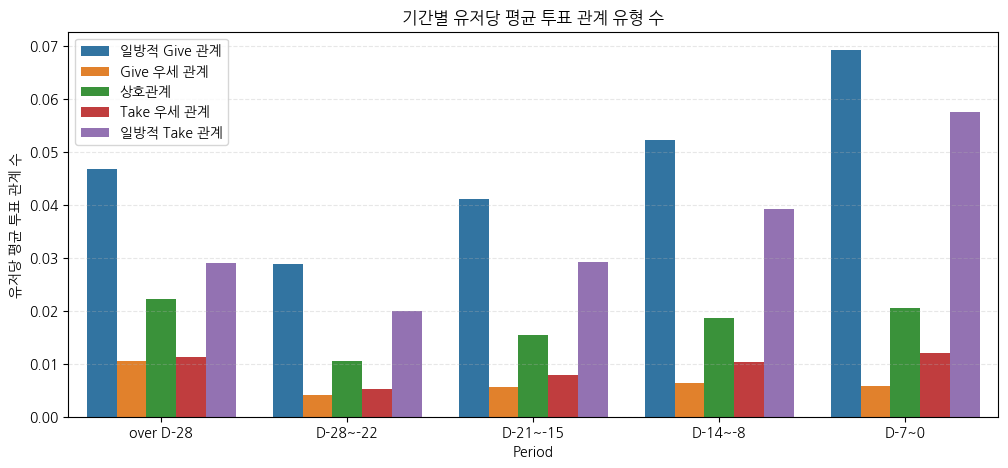

In [95]:
# 기간별 유저당 평균 투표 관계 유형 수

period_order = [
    'over D-28',
    'D-28~-22',
    'D-21~-15',
    'D-14~-8',
    'D-7~0'
]

pair_period['period'] = pd.Categorical(
    pair_period['period'],
    categories=period_order,
    ordered=True
)

# 전체 이탈 유저 수 (고정 분모, 관계 없는 유저도 포함)
total_churned_users = churned_users_list.nunique()

# 기간별 투표 관계 유형 총 수 -> 전체 이탈 유저 수로 나눠 평균화
relation_avg = (
    pair_period
    .groupby(['period', 'relation_type'], observed=True)
    .size()
    .reset_index(name='count')
)
relation_avg['count'] = relation_avg['count'] / total_churned_users

# 시각화
plt.figure(figsize=(12, 5))

sns.barplot(
    data=relation_avg,
    x='period',
    y='count',
    hue='relation_type'
)

plt.xlabel('Period')
plt.ylabel('유저당 평균 투표 관계 수')
plt.title('기간별 유저당 평균 투표 관계 유형 수')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.legend(title=None)

plt.show()

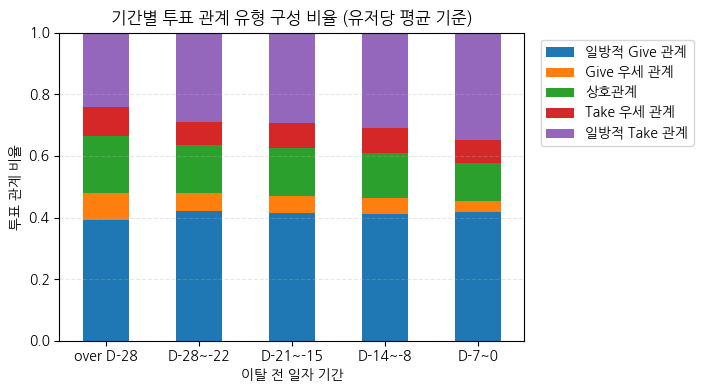

In [96]:
# 기간별 투표 관계 유형 구성 비율 (유저당 평균 기준)
relation_ratio = relation_avg.copy()

relation_ratio['ratio'] = (
    relation_ratio['count'] /
    relation_ratio.groupby('period', observed=False)['count'].transform('sum')
)

# 100% 누적 막대그래프용 Pivot Table 생성
pivot = relation_ratio.pivot(
    index='period',
    columns='relation_type',
    values='ratio'
)

pivot.plot(
    kind='bar',
    stacked=True,
    figsize=(6, 4)
)

plt.xlabel('이탈 전 일자 기간')
plt.ylabel('투표 관계 비율')
plt.title('기간별 투표 관계 유형 구성 비율 (유저당 평균 기준)')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

##### 투표 관계 유형 2 / 유저당 평균

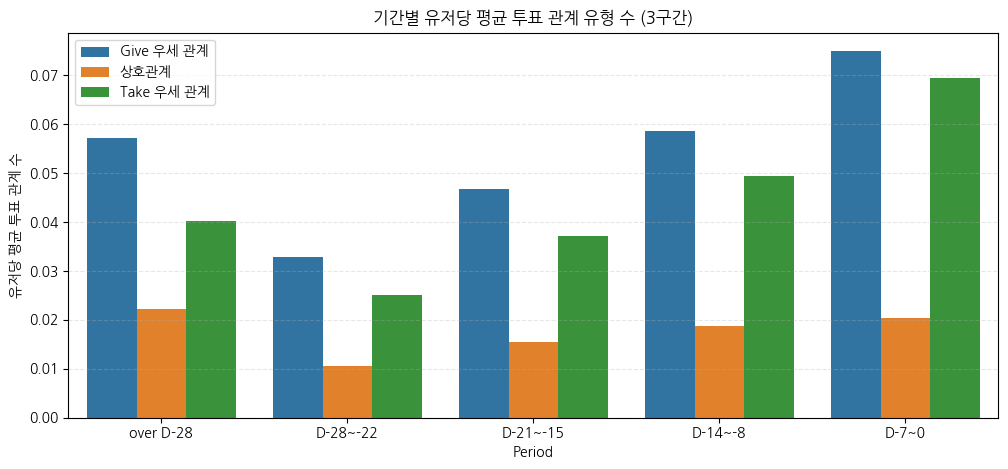

In [97]:
# 기간별 유저당 평균 투표 관계 유형 수 (3구간)

period_order = [
    'over D-28',
    'D-28~-22',
    'D-21~-15',
    'D-14~-8',
    'D-7~0'
]

pair_period['period'] = pd.Categorical(
    pair_period['period'],
    categories=period_order,
    ordered=True
)

# 전체 이탈 유저 수 (고정 분모, 관계 없는 유저도 포함)
total_churned_users = churned_users_list.nunique()

# 기간별 투표 관계 유형 총 수 -> 전체 이탈 유저 수로 나눠 평균화
relation_avg_2 = (
    pair_period
    .groupby(['period', 'relation_type_2'], observed=True)
    .size()
    .reset_index(name='count')
)
relation_avg_2['count'] = relation_avg_2['count'] / total_churned_users

# 시각화
plt.figure(figsize=(12, 5))

sns.barplot(
    data=relation_avg_2,
    x='period',
    y='count',
    hue='relation_type_2'
)

plt.xlabel('Period')
plt.ylabel('유저당 평균 투표 관계 수')
plt.title('기간별 유저당 평균 투표 관계 유형 수 (3구간)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.legend(title=None)

plt.show()

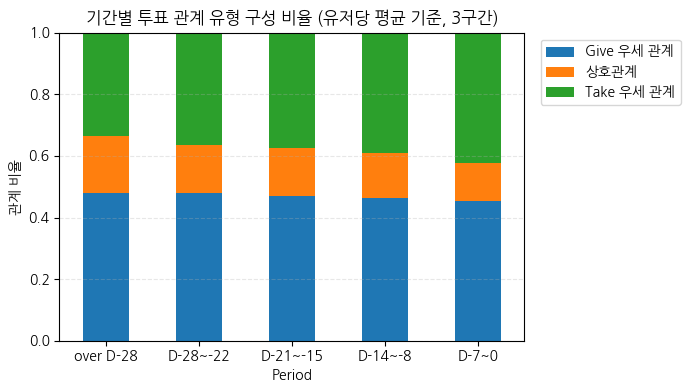

In [98]:
# 기간별 투표 관계 유형 구성 비율 (유저당 평균 기준, 3구간)
relation_ratio_2 = relation_avg_2.copy()

relation_ratio_2['ratio'] = (
    relation_ratio_2['count'] /
    relation_ratio_2.groupby('period', observed=False)['count'].transform('sum')
)

# 100% 누적 막대그래프용 Pivot Table 생성
pivot_2 = relation_ratio_2.pivot(
    index='period',
    columns='relation_type_2',
    values='ratio'
)

pivot_2.plot(
    kind='bar',
    stacked=True,
    figsize=(6, 4)
)

plt.xlabel('Period')
plt.ylabel('관계 비율')
plt.title('기간별 투표 관계 유형 구성 비율 (유저당 평균 기준, 3구간)')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

In [99]:
# d0 제외, d1~d28을 3일 간격으로 구성
bin_edges_3d = [0, 3, 6, 9, 12, 15, 18, 21, 24, 27, float('inf')]
bin_labels_3d = ['D1-3', 'D4-6', 'D7-9', 'D10-12', 'D13-15', 'D16-18',
                  'D19-21', 'D22-24', 'D25-27', 'over D27']

churn_relations_no_d0 = churn_relations[churn_relations['days_before_churn'] > 0].copy()

churn_relations_no_d0['period_3d'] = pd.cut(
    churn_relations_no_d0['days_before_churn'],
    bins=bin_edges_3d,
    labels=bin_labels_3d
)

# lambda 대신 boolean(0/1) 컬럼을 미리 만들어서 sum()만 쓰기 (훨씬 빠름)
churn_relations_no_d0['is_give'] = (churn_relations_no_d0['role'] == 'give').astype(int)
churn_relations_no_d0['is_take'] = (churn_relations_no_d0['role'] == 'take').astype(int)

# pair 단위 재집계
pair_period_3d = (
    churn_relations_no_d0
    .groupby(['churned_user_id', 'period_3d', 'pair_1', 'pair_2'], observed=True)
    .agg(
        give_count=('is_give', 'sum'),
        take_count=('is_take', 'sum')
    )
    .reset_index()
)

pair_period_3d['total_interaction'] = pair_period_3d['give_count'] + pair_period_3d['take_count']
pair_period_3d['take_ratio'] = pair_period_3d['take_count'] / pair_period_3d['total_interaction']

# 3구간 관계 유형 라벨링
pair_period_3d['relation_type_2'] = pd.cut(
    pair_period_3d['take_ratio'],
    bins=[-0.01, 0.33, 0.66, 1],
    labels=['Give 우세 관계', '상호관계', 'Take 우세 관계']
)

pair_period_3d.head()

,churned_user_id,period_3d,pair_1,pair_2,give_count,take_count,total_interaction,take_ratio,relation_type_2
0,833112,over D27,833112,885881,0,2,2,1.00,Take 우세 관계
1,833203,over D27,833203,855110,0,5,5,1.00,Take 우세 관계
2,833203,over D27,833203,855728,0,1,1,1.00,Take 우세 관계
3,833203,over D27,833203,855809,0,97,97,1.00,Take 우세 관계
4,833203,over D27,833203,856062,0,1,1,1.00,Take 우세 관계


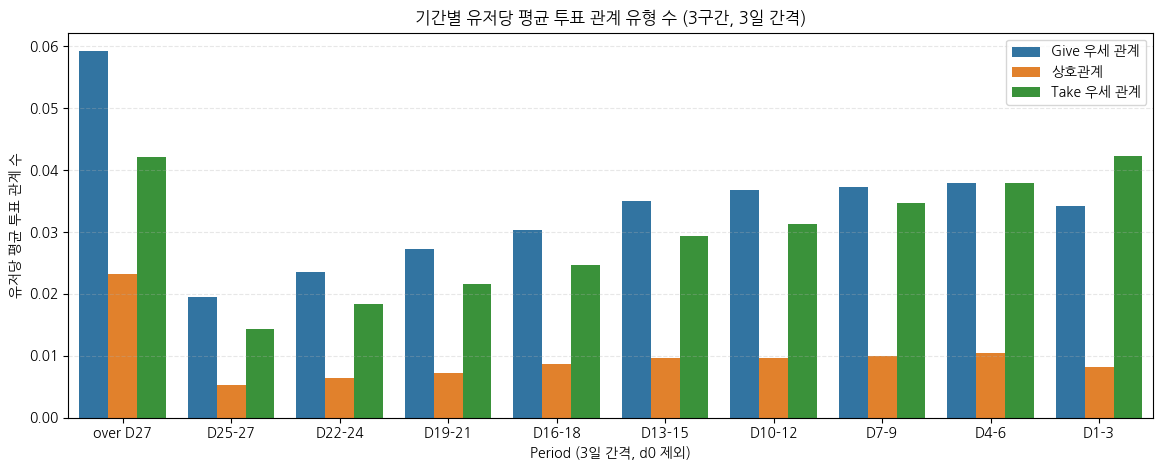

In [100]:
# 기간별 유저당 평균 투표 관계 유형 수 (3구간)
# 구간을 촘촘하게

period_order_3d = bin_labels_3d[::-1]  # 먼 과거 -> 이탈일 방향

pair_period_3d['period_3d'] = pd.Categorical(
    pair_period_3d['period_3d'],
    categories=period_order_3d,
    ordered=True
)

total_churned_users = churned_users_list.nunique()

relation_avg_2_3d = (
    pair_period_3d
    .groupby(['period_3d', 'relation_type_2'], observed=True)
    .size()
    .reset_index(name='count')
)
relation_avg_2_3d['count'] = relation_avg_2_3d['count'] / total_churned_users

plt.figure(figsize=(14, 5))
sns.barplot(
    data=relation_avg_2_3d,
    x='period_3d',
    y='count',
    hue='relation_type_2'
)
plt.xlabel('Period (3일 간격, d0 제외)')
plt.ylabel('유저당 평균 투표 관계 수')
plt.title('기간별 유저당 평균 투표 관계 유형 수 (3구간, 3일 간격)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.legend(title=None)
plt.show()

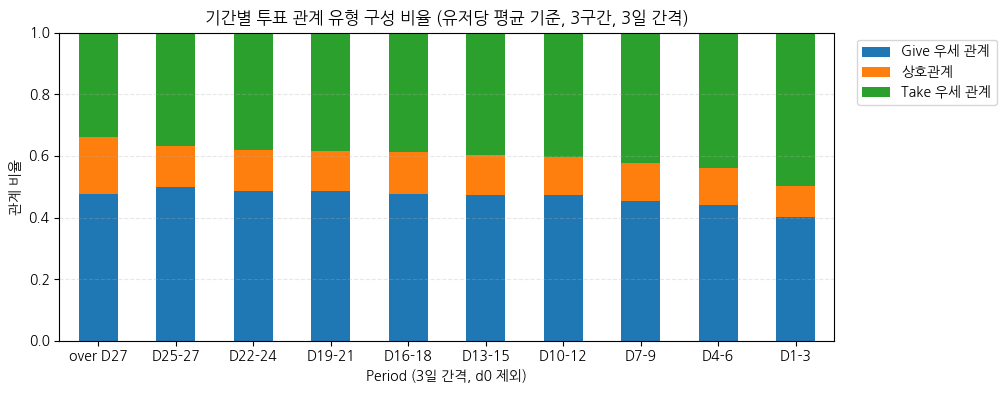

In [101]:
# 기간별 투표 관계 유형 구성 비율 (유저당 평균 기준, 3구간)
# 구간을 촘촘하게

relation_ratio_2_3d = relation_avg_2_3d.copy()

relation_ratio_2_3d['ratio'] = (
    relation_ratio_2_3d['count'] /
    relation_ratio_2_3d.groupby('period_3d', observed=False)['count'].transform('sum')
)

pivot_2_3d = relation_ratio_2_3d.pivot(
    index='period_3d',
    columns='relation_type_2',
    values='ratio'
)

pivot_2_3d.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 4)
)

plt.xlabel('Period (3일 간격, d0 제외)')
plt.ylabel('관계 비율')
plt.title('기간별 투표 관계 유형 구성 비율 (유저당 평균 기준, 3구간, 3일 간격)')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show()

##### 유저당 평균 일자별 투표 관계 수

,period,relation_count
0,over D-28,0.12
1,D-28~-22,0.07
2,D-21~-15,0.10
3,D-14~-8,0.13
4,D-7~0,0.16


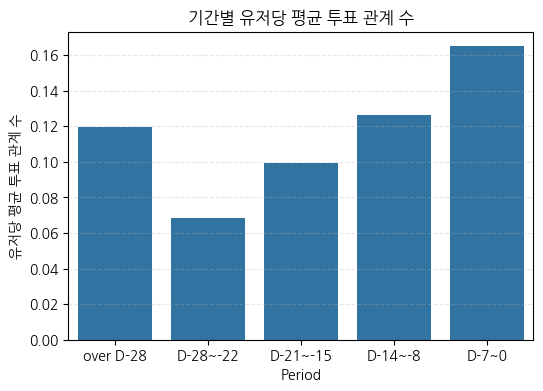

In [102]:
# 기간별 유저당 평균 투표 관계 수 (give/take 구분 없이, 전체 이탈 유저 기준)

total_churned_users = churned_users_list.nunique()

period_relation_avg = (
    pair_period
    .groupby('period', observed=True)
    .size()
    .reset_index(name='relation_count')
)
period_relation_avg['relation_count'] = period_relation_avg['relation_count'] / total_churned_users

display(period_relation_avg)

# 시각화
plt.figure(figsize=(6, 4))
sns.barplot(
    data=period_relation_avg,
    x='period',
    y='relation_count',
    color='tab:blue'
)
plt.xlabel('Period')
plt.ylabel('유저당 평균 투표 관계 수')
plt.title('기간별 유저당 평균 투표 관계 수')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.show()

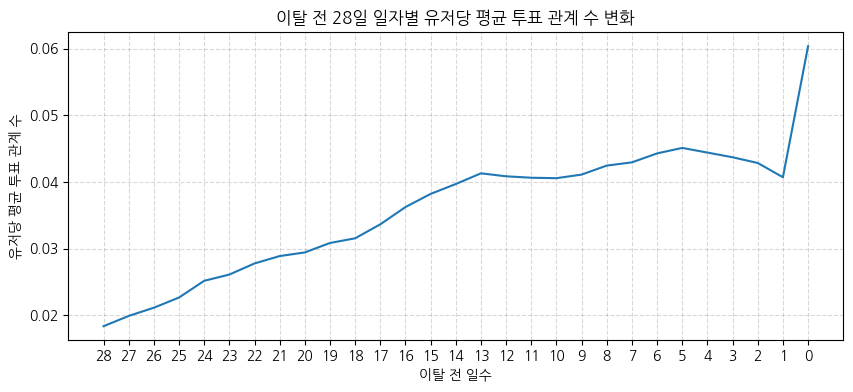

In [103]:
# 일자별 유저당 평균 투표 관계 수 (0~28일, give/take 구분 없이 그날 상호작용이 있었던 pair 수)
# A→B와 B→A가 같은 날 동시에 있으면 1로 카운트

daily_pair_avg = (
    churn_relations[churn_relations['days_before_churn'].between(0, 28)]
    .groupby(['days_before_churn', 'churned_user_id', 'pair_1', 'pair_2'], observed=True)
    .size()
    .reset_index(name='dummy')
    .groupby('days_before_churn')
    .size()
    .reset_index(name='relation_count')
)
daily_pair_avg['relation_count'] = daily_pair_avg['relation_count'] / total_churned_users

plt.figure(figsize=(10, 4))
plt.plot(daily_pair_avg['days_before_churn'], daily_pair_avg['relation_count'])
plt.xticks(range(0, 29, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('유저당 평균 투표 관계 수')
plt.title('이탈 전 28일 일자별 유저당 평균 투표 관계 수 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.show()

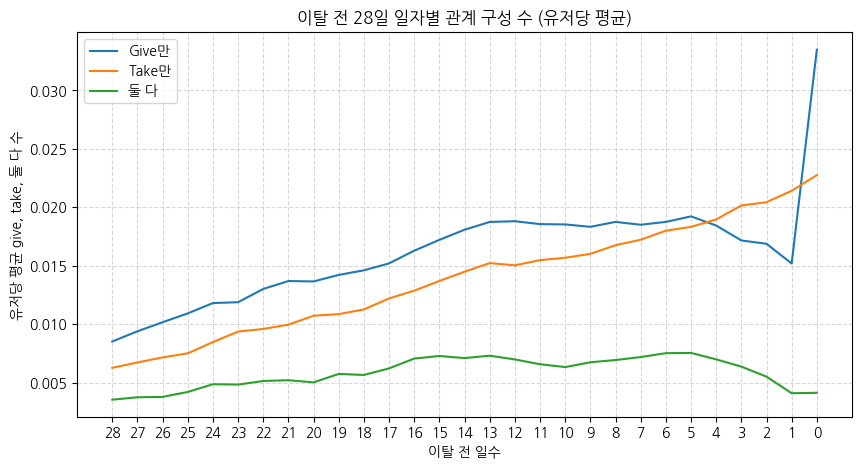

In [104]:
total_churned_users = churned_users_list.nunique()

# 필터링 먼저
filtered = churn_relations[churn_relations['days_before_churn'].between(0, 28)].copy()

# give/take를 미리 boolean(0/1)으로 변환 -> groupby에서 sum()만 쓰면 빠름
filtered['is_give'] = (filtered['role'] == 'give').astype(int)
filtered['is_take'] = (filtered['role'] == 'take').astype(int)

daily_pair_stats = (
    filtered
    .groupby(['days_before_churn', 'churned_user_id', 'pair_1', 'pair_2'], observed=True)
    .agg(
        give_count=('is_give', 'sum'),
        take_count=('is_take', 'sum')
    )
    .reset_index()
)

# 그날 하루 기준 구성 분류 (벡터화)
conditions = [
    (daily_pair_stats['give_count'] > 0) & (daily_pair_stats['take_count'] > 0),
    (daily_pair_stats['give_count'] > 0)
]
choices = ['둘 다', 'Give만']
daily_pair_stats['daily_type'] = np.select(conditions, choices, default='Take만')

# 일자별, 구성 유형별 투표 관계 수 -> 유저당 평균
daily_type_avg = (
    daily_pair_stats
    .groupby(['days_before_churn', 'daily_type'])
    .size()
    .reset_index(name='relation_count')
)
daily_type_avg['relation_count'] = daily_type_avg['relation_count'] / total_churned_users

# 시각화
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=daily_type_avg,
    x='days_before_churn',
    y='relation_count',
    hue='daily_type'
)
plt.xticks(range(0, 29, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('유저당 평균 give, take, 둘 다 수')
plt.title('이탈 전 28일 일자별 관계 구성 수 (유저당 평균)')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend(title=None)
plt.show()

##### 상관분석: 이탈일에 가까워질수록 take_ratio(투표 받은 비율)이 높아지는가?

In [105]:
corr, p_value = spearmanr(daily_avg_raw_28['days_before_churn'], daily_avg_raw_28['take_ratio'])
print(f'Spearman correlation: {corr:.3f}, p-value: {p_value:.4f}')

Spearman correlation: -0.950, p-value: 0.0000


In [106]:
daily_user_stats_28

,days_before_churn,churned_user_id,give,take
60508,0,833294,0,1
60509,0,833525,0,7
60510,0,837528,0,3
60511,0,837530,0,14
60512,0,837564,0,2
...,...,...,...,...
139807,28,1533397,7,0
139808,28,1534806,0,1
139809,28,1550972,27,1
139810,28,1554009,37,5


##### 일자별 접속 유저의 평균 투표 수 변화

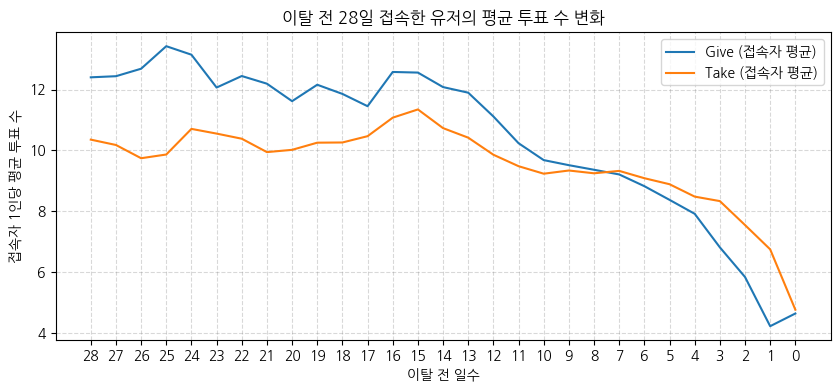

In [107]:
# 1. 일자별 접속(활동)률: 그날 give든 take든 뭐라도 활동이 있었던 유저 비율

# 2. 접속한 사람들만의 평균 give/take (조건부 평균)
active_only = daily_user_stats_28[
    (daily_user_stats_28['give'] + daily_user_stats_28['take']) > 0
].copy()

conditional_avg = (
    active_only
    .groupby('days_before_churn')
    .agg(give_cond=('give', 'mean'), take_cond=('take', 'mean'))
    .reset_index()
)

# 시각화 2 - 접속한 사람들만의 평균 give/take
plt.figure(figsize=(10, 4))
plt.plot(conditional_avg['days_before_churn'], conditional_avg['give_cond'], label='Give (접속자 평균)')
plt.plot(conditional_avg['days_before_churn'], conditional_avg['take_cond'], label='Take (접속자 평균)')
plt.xticks(range(0, 29, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('접속자 1인당 평균 투표 수')
plt.title('이탈 전 28일 접속한 유저의 평균 투표 수 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

##### 잔존 유저 분석

In [108]:
# 잔존 유저 추출
# 28일 미만 연속 비활성 이후 재유입 또는 데이터 마지막 시점까지 활동 기록이 있는 유저

retained_users = last_activity[inactive_days < 28].reset_index()
retained_users = retained_users.rename(columns={'event_time': 'last_active_date'})
retained_users_list = retained_users['user_id']

print(f'활동 기록이 있는 유저 수: {engaged_user_count:,}')
print(f'잔존 유저 수: {len(retained_users):,}')
print(f'잔존 유저 비율: {len(retained_users) / engaged_user_count:,.2%}')

retained_users.head()

활동 기록이 있는 유저 수: 653,085
잔존 유저 수: 1,295
잔존 유저 비율: 0.20%


,user_id,last_active_date
0,837587,2024-05-08
1,837697,2024-04-28
2,838492,2024-04-22
3,839006,2024-04-25
4,839027,2024-04-25


In [109]:
# 잔존 유저의 give/take 관계 테이블 구축 (churn_relations와 대칭 구조)

# 1. 잔존 유저가 투표한(Give) 기록
give_side_retained = pd.merge(
    accounts_userquestionrecord_revised,
    retained_users,
    on='user_id',
    how='inner'
)
give_side_retained['role'] = 'give'
give_side_retained['retained_user_id'] = give_side_retained['user_id']
give_side_retained['other_user_id'] = give_side_retained['chosen_user_id']
give_side_retained['action_date'] = give_side_retained['created_at']

# 2. 잔존 유저가 투표받은(Take) 기록
take_side_retained = pd.merge(
    accounts_userquestionrecord_revised,
    retained_users.rename(columns={'user_id': 'chosen_user_id'}),
    on='chosen_user_id',
    how='inner'
)
take_side_retained['role'] = 'take'
take_side_retained['retained_user_id'] = take_side_retained['chosen_user_id']
take_side_retained['other_user_id'] = take_side_retained['user_id']
take_side_retained['action_date'] = take_side_retained['created_at']

# 3. Give + Take 합치기
cols_retained = [
    'retained_user_id',
    'other_user_id',
    'action_date',
    'role'
]

retained_relations = pd.concat(
    [give_side_retained[cols_retained], take_side_retained[cols_retained]],
    ignore_index=True
)

# 4. 데이터 종료일까지 며칠 전인지 계산 (churn_relations의 days_before_churn과 대응)
reference_date = tables_combined['event_time'].max().normalize()

retained_relations['days_before_end'] = (
    reference_date - retained_relations['action_date']
).dt.days

# 5. 기간 구분 (churn_relations의 period와 동일한 bin 사용)
retained_relations['period'] = pd.cut(
    retained_relations['days_before_end'],
    bins=[-1, 7, 14, 21, 28, float('inf')],
    labels=[
        'D-7~0',
        'D-14~-8',
        'D-21~-15',
        'D-28~-22',
        'over D-28'
    ]
)

retained_relations.head()

,retained_user_id,other_user_id,action_date,role,days_before_end,period
0,855525,850774,2023-04-29,give,376,over D-28
1,855525,855509,2023-04-29,give,376,over D-28
2,855525,855509,2023-04-29,give,376,over D-28
3,855525,855526,2023-04-29,give,376,over D-28
4,855525,855340,2023-04-29,give,376,over D-28


In [110]:
# 잔존 유저: 유저-일자별 give/take 집계 (daily_user_stats와 동일한 구조)

retained_daily_user_stats = (
    retained_relations
    .groupby(['days_before_end', 'retained_user_id'])
    .agg(
        give=('role', lambda x: (x == 'give').sum()),
        take=('role', lambda x: (x == 'take').sum())
    )
    .reset_index()
)

retained_daily_user_stats.head()

,days_before_end,retained_user_id,give,take
0,1,855525,4,0
1,1,874566,0,1
2,2,945560,0,1
3,2,1001607,1,0
4,2,1208878,10,0


Give 최고점: 종료일 전 2일


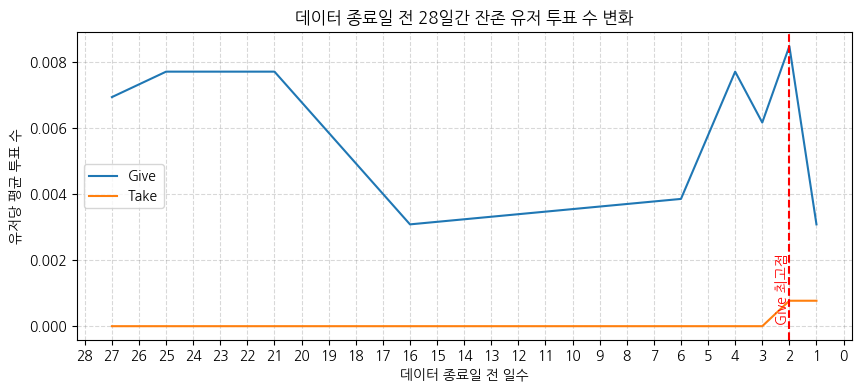

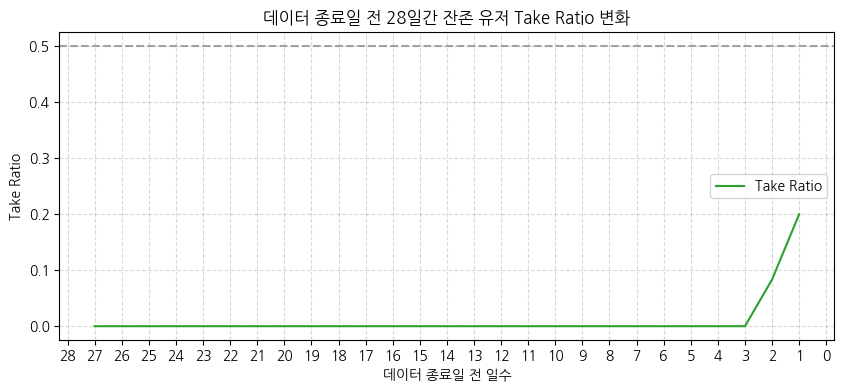

,days_before_end,give,take,take_ratio
0,1,0.00,0.00,0.20
1,2,0.01,0.00,0.08
2,3,0.01,0.00,0.00
3,4,0.01,0.00,0.00
4,6,0.00,0.00,0.00


In [111]:
# 유저당 평균: 일자별 give 수, take 수 (캡핑 X) - 잔존 유저

# ===== 데이터 종료일 전 0~28일 =====

# 0~28일 구간으로 필터링
retained_daily_user_stats_28 = retained_daily_user_stats[
    retained_daily_user_stats['days_before_end'].between(0, 28)
].copy()

# 전체 잔존 유저 수 (고정 분모, 비활동 유저 포함)
total_retained_users = retained_users_list.nunique()

# 일자별 give/take 합계
retained_sum_raw_28 = (
    retained_daily_user_stats_28
    .groupby('days_before_end')
    .agg(give_sum=('give', 'sum'), take_sum=('take', 'sum'))
    .reset_index()
)

# 유저당 평균 give/take (전체 잔존 유저 기준)
retained_sum_raw_28['give'] = retained_sum_raw_28['give_sum'] / total_retained_users
retained_sum_raw_28['take'] = retained_sum_raw_28['take_sum'] / total_retained_users

# take_ratio (합산 기준)
retained_sum_raw_28['take_ratio'] = (
    retained_sum_raw_28['take_sum'] / (retained_sum_raw_28['give_sum'] + retained_sum_raw_28['take_sum'])
)

retained_avg_raw_28 = retained_sum_raw_28[['days_before_end', 'give', 'take', 'take_ratio']]

xticks_28 = range(0, 29, 1)

# give가 꺾이는 지점 자동 탐지: 28일 -> 0일(시간 순) 중 give가 최고점을 찍는 날
time_ordered = retained_avg_raw_28.sort_values('days_before_end', ascending=False)
peak_day = time_ordered.loc[time_ordered['give'].idxmax(), 'days_before_end']
print(f'Give 최고점: 종료일 전 {peak_day}일')

# 시각화 1 - 투표 수
plt.figure(figsize=(10, 4))
plt.plot(retained_avg_raw_28['days_before_end'], retained_avg_raw_28['give'], label='Give')
plt.plot(retained_avg_raw_28['days_before_end'], retained_avg_raw_28['take'], label='Take')

y_min, y_max = plt.ylim()
text_y = y_min + (y_max - y_min) * 0.05

plt.axvline(x=peak_day, color='red', linestyle='--', linewidth=1.5)
plt.text(peak_day, text_y, 'Give 최고점', color='red', rotation=90, ha='right', va='bottom')

plt.xticks(xticks_28)
plt.gca().invert_xaxis()
plt.xlabel('데이터 종료일 전 일수')
plt.ylabel('유저당 평균 투표 수')
plt.title('데이터 종료일 전 28일간 잔존 유저 투표 수 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

# 시각화 2 - Take Ratio
plt.figure(figsize=(10, 4))
plt.plot(retained_avg_raw_28['days_before_end'], retained_avg_raw_28['take_ratio'], color='tab:green', label='Take Ratio')
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.7)
plt.xticks(xticks_28)
plt.gca().invert_xaxis()
plt.xlabel('데이터 종료일 전 일수')
plt.ylabel('Take Ratio')
plt.title('데이터 종료일 전 28일간 잔존 유저 Take Ratio 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

retained_avg_raw_28.head()

## 중복된 질문이 노출된 횟수

In [112]:
cols = ['question_id', 'user_id']

question_and_user_ids = accounts_userquestionrecord[cols]

question_and_user_ids_cnt = len(question_and_user_ids)
dup_question_cnt = question_and_user_ids.duplicated().sum()
dup_question_ratio = dup_question_cnt / len(question_and_user_ids) * 100

print(f'전체 질문 수: {question_and_user_ids_cnt:,}')
print(f'중복된 질문 수: {dup_question_cnt:,}')
print(f'중복된 질문 비율: {dup_question_ratio:.2f}%')

전체 질문 수: 1,213,926
중복된 질문 수: 227,926
중복된 질문 비율: 18.78%


In [113]:
question_and_user_ids.head()

,question_id,user_id
0,252,849436
1,244,849436
2,183,849436
3,101,849436
4,209,849436


In [114]:
question_view_cnt = question_and_user_ids.groupby(['user_id', 'question_id']).size().reset_index(name='view_count')
view_count_distribution = question_view_cnt.groupby('view_count').size().reset_index(name='count')
view_count_distribution['ratio(%)'] = view_count_distribution['count'] / view_count_distribution['count'].sum() * 100

view_count_distribution

,view_count,count,ratio(%)
0,1,807225,81.87
1,2,141054,14.31
2,3,29155,2.96
3,4,6460,0.66
4,5,1553,0.16
5,6,407,0.04
6,7,106,0.01
7,8,28,0.00
8,9,6,0.00
9,10,5,0.00


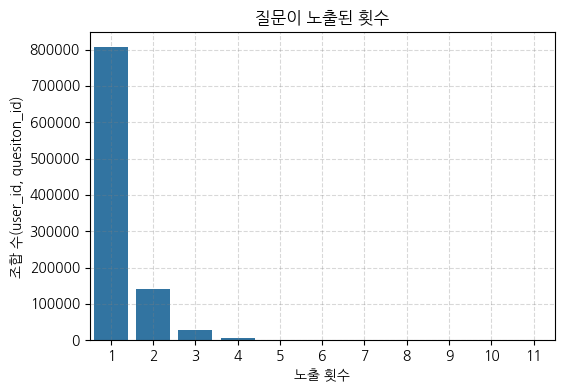

In [115]:
plt.figure(figsize=(6, 4))
sns.barplot(data=view_count_distribution, x='view_count', y='count')
plt.title('질문이 노출된 횟수')
plt.xlabel('노출 횟수')
plt.ylabel('조합 수(user_id, quesiton_id)')
plt.grid(color='gray', alpha=0.3, linestyle='--')
plt.show()

In [116]:
accounts_userquestionrecord

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
0,771777,C,2023-04-28 12:27:49,849469,252,849436,998458,0,N,2023-04-28 12:27:49,0,0
1,771800,C,2023-04-28 12:28:02,849446,244,849436,998459,0,N,2023-04-28 12:28:02,0,0
2,771812,C,2023-04-28 12:28:09,849454,183,849436,998460,1,N,2023-04-28 12:28:09,0,0
3,771828,C,2023-04-28 12:28:16,847375,101,849436,998461,0,N,2023-04-28 12:28:16,0,0
4,771851,C,2023-04-28 12:28:26,849477,209,849436,998462,1,N,2023-04-28 12:28:26,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1213921,161666166,C,2024-05-07 11:29:07,945560,2614,1001607,190864020,1,N,2024-05-07 11:29:07,0,0
1213922,161666461,C,2024-05-08 01:34:56,850774,1679,855525,200139931,0,N,2024-05-08 01:34:56,0,0
1213923,161666462,C,2024-05-08 01:35:02,855509,2605,855525,200139932,0,N,2024-05-08 01:35:02,0,0
1213924,161666463,C,2024-05-08 01:36:00,855526,3801,855525,200139933,0,N,2024-05-08 01:36:00,0,0


### 가설 검증: 이탈에 가까워질수록 중복된 질문을 보는 비율이 높아지는가?

In [117]:
# 1. 이탈 유저 기록만 필터링, days_before_churn 부여
question_records = pd.merge(
    accounts_userquestionrecord_revised,
    churned_users,
    on='user_id',
    how='inner'
)

question_records['days_before_churn'] = (
    question_records['last_active_date'] - question_records['created_at']
).dt.days

# 2. 유저별, 시간순 정렬 후 이전에 같은 question_id를 받은 적 있는지 표시
question_records = question_records.sort_values(['user_id', 'created_at'])

question_records['seen_count_so_far'] = (
    question_records.groupby(['user_id', 'question_id']).cumcount()
)
question_records['is_duplicate'] = question_records['seen_count_so_far'] > 0

question_records[['user_id', 'question_id', 'created_at', 'days_before_churn', 'is_duplicate']].head()

,user_id,question_id,created_at,days_before_churn,is_duplicate
12062,838023,121,2023-04-29,5,False
16220,838023,224,2023-04-30,4,False
16222,838023,121,2023-04-30,4,True
16223,838023,310,2023-04-30,4,False
16225,838023,203,2023-04-30,4,False


In [118]:
question_records

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times,pair_1,pair_2,last_active_date,days_before_churn,seen_count_so_far,is_duplicate
12062,1010814,C,2023-04-29,854596,121,838023,1167335,0,N,2023-04-29,0,0,838023,854596,2023-05-04,5,0,False
16220,1105460,C,2023-04-30,855117,224,838023,1327698,1,N,2023-04-30,0,0,838023,855117,2023-05-04,4,0,False
16222,1105509,C,2023-04-30,855340,121,838023,1327699,0,N,2023-04-30,0,0,838023,855340,2023-05-04,4,1,True
16223,1105536,C,2023-04-30,855953,310,838023,1327700,0,N,2023-04-30,0,0,838023,855953,2023-05-04,4,0,False
16225,1105598,C,2023-04-30,854615,203,838023,1327702,0,N,2023-04-30,0,0,838023,854615,2023-05-04,4,0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1202480,160418395,C,2023-08-05,1575359,3264,1579418,206172529,0,N,2023-08-05,0,0,1575359,1579418,2023-08-05,0,0,False
1205007,161100138,C,2023-09-20,1566708,1487,1580578,207530981,0,N,2023-09-20,0,0,1566708,1580578,2023-09-20,0,0,False
1205008,161100139,C,2023-09-20,1576039,3807,1580578,207530984,1,N,2023-09-20,0,0,1576039,1580578,2023-09-20,0,0,False
1207046,161643072,C,2024-03-19,1552803,4975,1583358,208351463,0,N,2024-03-19,0,0,1552803,1583358,2024-03-19,0,0,False


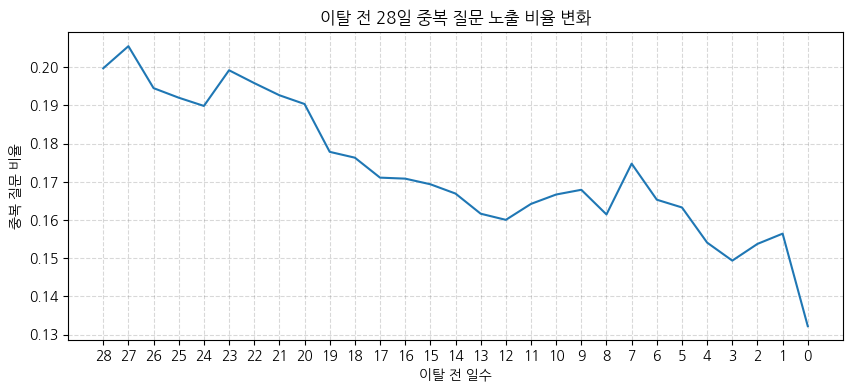

In [119]:
# 일자별 중복 질문 비율 (0~28일)
daily_duplicate = (
    question_records[question_records['days_before_churn'].between(0, 28)]
    .groupby('days_before_churn')['is_duplicate']
    .mean()
    .reset_index(name='duplicate_ratio')
)

plt.figure(figsize=(10, 4))
plt.plot(daily_duplicate['days_before_churn'], daily_duplicate['duplicate_ratio'])
plt.xticks(range(0, 29, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('중복 질문 비율')
plt.title('이탈 전 28일 중복 질문 노출 비율 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.show()

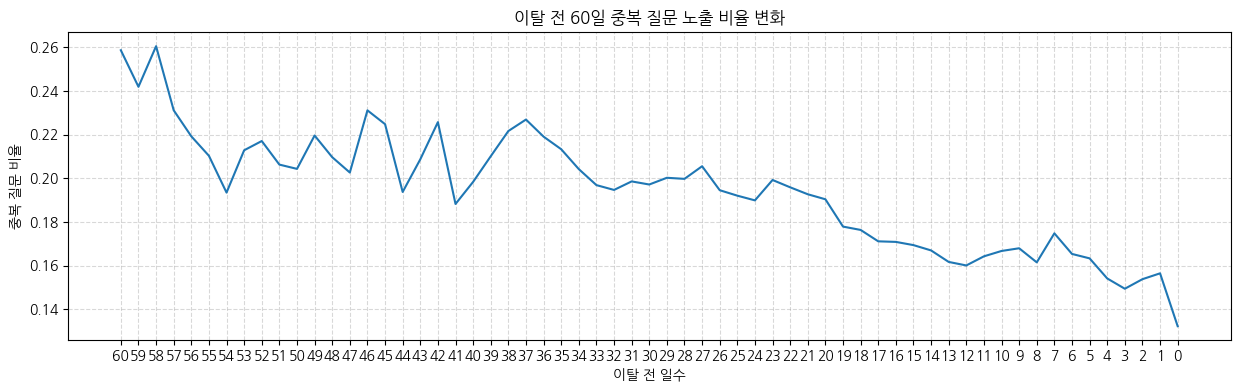

In [120]:
# 일자별 중복 질문 비율 (0~60일)
daily_duplicate = (
    question_records[question_records['days_before_churn'].between(0, 60)]
    .groupby('days_before_churn')['is_duplicate']
    .mean()
    .reset_index(name='duplicate_ratio')
)

plt.figure(figsize=(15, 4))
plt.plot(daily_duplicate['days_before_churn'], daily_duplicate['duplicate_ratio'])
plt.xticks(range(0, 61, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('중복 질문 비율')
plt.title('이탈 전 60일 중복 질문 노출 비율 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.show()

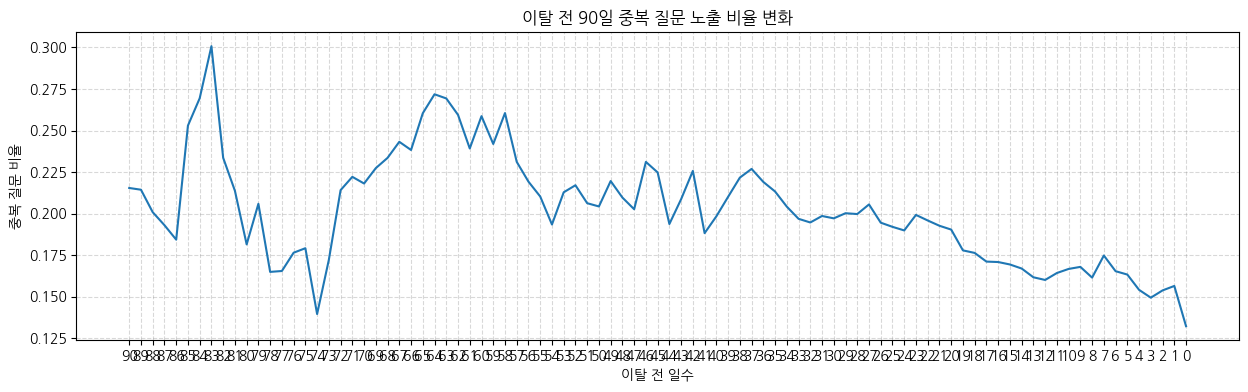

In [121]:
# 일자별 중복 질문 비율 (0~90일)
daily_duplicate = (
    question_records[question_records['days_before_churn'].between(0, 90)]
    .groupby('days_before_churn')['is_duplicate']
    .mean()
    .reset_index(name='duplicate_ratio')
)

plt.figure(figsize=(15, 4))
plt.plot(daily_duplicate['days_before_churn'], daily_duplicate['duplicate_ratio'])
plt.xticks(range(0, 91, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('중복 질문 비율')
plt.title('이탈 전 90일 중복 질문 노출 비율 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.show()

## 이탈 전 일자별 투표자 수 확인

In [122]:
churn_relations.head()

,churned_user_id,other_user_id,action_date,role,last_active_date,pair_1,pair_2,days_before_churn,period
0,849436,849469,2023-04-28,give,2023-06-06,849436,849469,39,over D-28
1,849436,849446,2023-04-28,give,2023-06-06,849436,849446,39,over D-28
2,849436,849454,2023-04-28,give,2023-06-06,849436,849454,39,over D-28
3,849436,847375,2023-04-28,give,2023-06-06,847375,849436,39,over D-28
4,849436,849477,2023-04-28,give,2023-06-06,849436,849477,39,over D-28


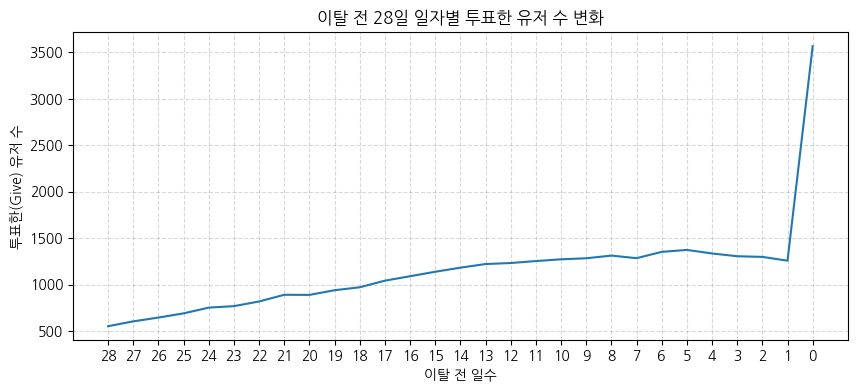

,days_before_churn,give_user_count
0,0,3567
1,1,1258
2,2,1299
3,3,1306
4,4,1336


In [123]:
# ⭐ 일자별 give를 한 이탈 유저 수 (0~28일)

daily_give_user_count = (
    churn_relations[
        (churn_relations['days_before_churn'].between(0, 28)) &
        (churn_relations['role'] == 'give')
    ]
    .groupby('days_before_churn')['churned_user_id']
    .nunique()
    .reset_index(name='give_user_count')
)

plt.figure(figsize=(10, 4))
plt.plot(daily_give_user_count['days_before_churn'], daily_give_user_count['give_user_count'])
plt.xticks(range(0, 29, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('투표한(Give) 유저 수')
plt.title('이탈 전 28일 일자별 투표한 유저 수 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.show()

daily_give_user_count.head()

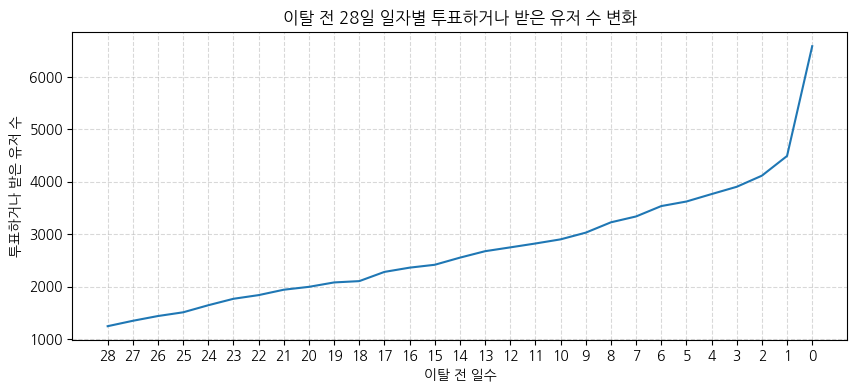

,days_before_churn,active_user_count
0,0,6588
1,1,4493
2,2,4117
3,3,3905
4,4,3766


In [124]:
# 일자별 give 또는 take가 있었던 이탈 유저 수 (0~28일)

daily_any_user_count = (
    churn_relations[churn_relations['days_before_churn'].between(0, 28)]
    .groupby('days_before_churn')['churned_user_id']
    .nunique()
    .reset_index(name='active_user_count')
)

plt.figure(figsize=(10, 4))
plt.plot(daily_any_user_count['days_before_churn'], daily_any_user_count['active_user_count'])
plt.xticks(range(0, 29, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('투표하거나 받은 유저 수')
plt.title('이탈 전 28일 일자별 투표하거나 받은 유저 수 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.show()

daily_any_user_count.head()

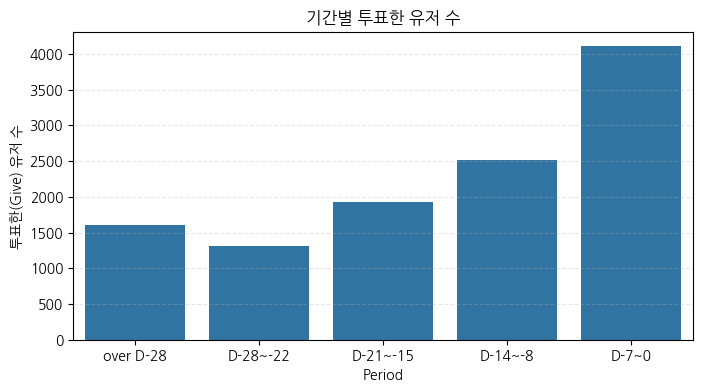

,period,give_user_count
0,over D-28,1599
1,D-28~-22,1306
2,D-21~-15,1928
3,D-14~-8,2514
4,D-7~0,4104


In [125]:
# 구간별 give를 한 이탈 유저 수 (고유 유저)

period_order = [
    'over D-28',
    'D-28~-22',
    'D-21~-15',
    'D-14~-8',
    'D-7~0'
]

churn_relations['period'] = pd.Categorical(
    churn_relations['period'],
    categories=period_order,
    ordered=True
)

period_give_user_count = (
    churn_relations[churn_relations['role'] == 'give']
    .groupby('period', observed=True)['churned_user_id']
    .nunique()
    .reset_index(name='give_user_count')
)

# 시각화
plt.figure(figsize=(8, 4))
sns.barplot(
    data=period_give_user_count,
    x='period',
    y='give_user_count',
    color='tab:blue'
)
plt.xlabel('Period')
plt.ylabel('투표한(Give) 유저 수')
plt.title('기간별 투표한 유저 수')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.show()

period_give_user_count

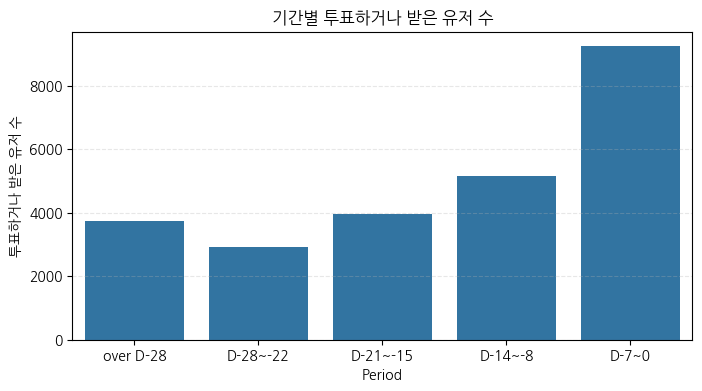

,period,active_user_count
0,over D-28,3748
1,D-28~-22,2926
2,D-21~-15,3974
3,D-14~-8,5159
4,D-7~0,9236


In [126]:
# 구간별 give 또는 take, 즉 뭐라도 활동이 있었던 이탈 유저 수 (고유 유저)

period_any_user_count = (
    churn_relations
    .groupby('period', observed=True)['churned_user_id']
    .nunique()
    .reset_index(name='active_user_count')
)

# 시각화
plt.figure(figsize=(8, 4))
sns.barplot(
    data=period_any_user_count,
    x='period',
    y='active_user_count',
    color='tab:blue'
)
plt.xlabel('Period')
plt.ylabel('투표하거나 받은 유저 수')
plt.title('기간별 투표하거나 받은 유저 수')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.show()

period_any_user_count

### 활동일 기간별 give 변화 비교

In [127]:
# 유저별 첫 활동일 계산
first_activity = tables_combined.groupby('user_id')['event_time'].min().dt.normalize()

# churned_users에 첫 활동일 병합, 활동 기간(tenure) 계산
churned_users_tenure = churned_users.merge(
    first_activity.rename('first_active_date'),
    left_on='user_id', right_index=True,
    how='left'
)

churned_users_tenure['tenure_days'] = (
    churned_users_tenure['last_active_date'] - churned_users_tenure['first_active_date']
).dt.days

churned_users_tenure[['user_id', 'first_active_date', 'last_active_date', 'tenure_days']].head()

,user_id,first_active_date,last_active_date,tenure_days
0,831962,2023-07-13,2023-07-13,0
1,832151,2023-04-22,2023-05-29,37
2,832340,2023-04-22,2023-06-06,45
3,832986,2023-05-28,2023-05-28,0
4,833024,2023-05-20,2023-05-28,8


In [128]:
# 활동 기간 14일 미만인 유저 비율 확인
short_tenure_ratio = (churned_users_tenure['tenure_days'] < 14).mean()
print(f'활동 기간 14일 미만 유저 비율: {short_tenure_ratio:.2%}')

# 참고로 분포도 같이 확인
churned_users_tenure['tenure_days'].describe()

활동 기간 14일 미만 유저 비율: 53.95%


,tenure_days
count,651790.00
mean,25.07
std,41.00
min,0.00
25%,1.00
50%,11.00
75%,27.00
max,353.00


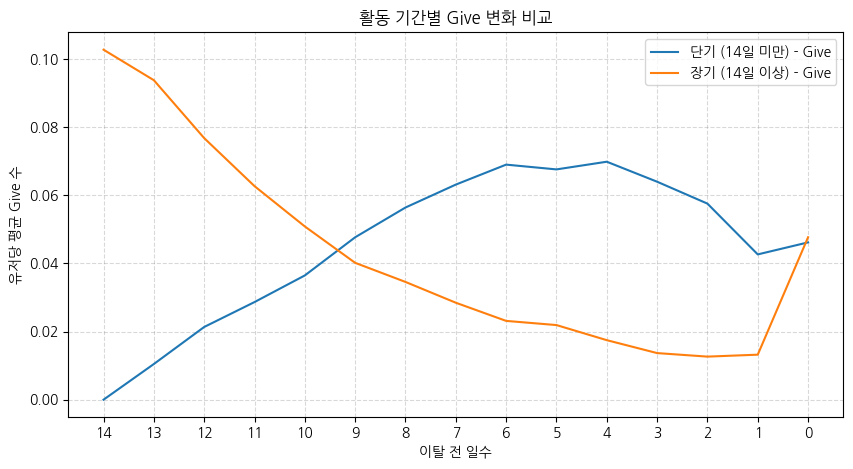

In [129]:
# tenure 기준으로 단기/장기 유저 구분
churned_users_tenure['tenure_group'] = np.where(
    churned_users_tenure['tenure_days'] < 14,
    '단기 (14일 미만)', '장기 (14일 이상)'
)

# daily_user_stats에 그룹 정보 병합
daily_user_stats_tenure = daily_user_stats.merge(
    churned_users_tenure[['user_id', 'tenure_group']],
    left_on='churned_user_id', right_on='user_id',
    how='left'
)

total_by_tenure_group = churned_users_tenure.groupby('tenure_group')['user_id'].nunique()

tenure_14 = daily_user_stats_tenure[
    daily_user_stats_tenure['days_before_churn'].between(0, 14)
]

tenure_sum = (
    tenure_14
    .groupby(['tenure_group', 'days_before_churn'])
    .agg(give_sum=('give', 'sum'), take_sum=('take', 'sum'))
    .reset_index()
)

tenure_sum['total_users'] = tenure_sum['tenure_group'].map(total_by_tenure_group)
tenure_sum['give'] = tenure_sum['give_sum'] / tenure_sum['total_users']
tenure_sum['take'] = tenure_sum['take_sum'] / tenure_sum['total_users']

# 시각화 - 그룹별 Give 비교
plt.figure(figsize=(10, 5))
for group in ['단기 (14일 미만)', '장기 (14일 이상)']:
    subset = tenure_sum[tenure_sum['tenure_group'] == group]
    plt.plot(subset['days_before_churn'], subset['give'], label=f'{group} - Give')

plt.xticks(range(0, 15, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('유저당 평균 Give 수')
plt.title('활동 기간별 Give 변화 비교')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

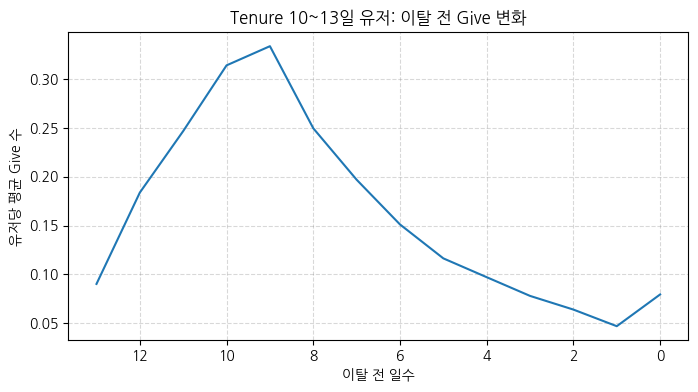

In [130]:
# 단기 유저 중에서도 tenure 10~13일인 사람만 추출
mid_short_users = churned_users_tenure[
    (churned_users_tenure['tenure_days'] >= 10) & (churned_users_tenure['tenure_days'] < 14)
]['user_id']

daily_user_stats_midshort = daily_user_stats[
    daily_user_stats['churned_user_id'].isin(mid_short_users)
]

total_midshort = mid_short_users.nunique()

midshort_sum = (
    daily_user_stats_midshort[daily_user_stats_midshort['days_before_churn'].between(0, 13)]
    .groupby('days_before_churn')
    .agg(give_sum=('give', 'sum'))
    .reset_index()
)
midshort_sum['give'] = midshort_sum['give_sum'] / total_midshort

plt.figure(figsize=(8, 4))
plt.plot(midshort_sum['days_before_churn'], midshort_sum['give'])
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('유저당 평균 Give 수')
plt.title('Tenure 10~13일 유저: 이탈 전 Give 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.show()

## 유저 활동 기간별 give & take 확인

In [131]:
# 전체 이탈 유저의 활동 기간(tenure) 분포
print('=== 전체 이탈 유저 tenure 분포 ===')
print(churned_users_tenure['tenure_days'].describe())
print(f"\n평균: {churned_users_tenure['tenure_days'].mean():.1f}일")
print(f"중위값: {churned_users_tenure['tenure_days'].median():.1f}일")

=== 전체 이탈 유저 tenure 분포 ===
count   651790.00
mean        25.07
std         41.00
min          0.00
25%          1.00
50%         11.00
75%         27.00
max        353.00
Name: tenure_days, dtype: float64

평균: 25.1일
중위값: 11.0일


In [132]:
# 장기 유저(14일 이상)만의 tenure 분포
long_term_tenure = churned_users_tenure[churned_users_tenure['tenure_days'] >= 14]['tenure_days']

print('=== 장기 유저(14일 이상) tenure 분포 ===')
print(long_term_tenure.describe())
print(f"\n평균: {long_term_tenure.mean():.1f}일")
print(f"중위값: {long_term_tenure.median():.1f}일")
print(f"\n분위수:")
print(long_term_tenure.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

=== 장기 유저(14일 이상) tenure 분포 ===
count   300168.00
mean        50.48
std         49.35
min         14.00
25%         20.00
50%         29.00
75%         65.00
max        353.00
Name: tenure_days, dtype: float64

평균: 50.5일
중위값: 29.0일

분위수:
0.10    16.00
0.25    20.00
0.50    29.00
0.75    65.00
0.90   125.00
0.99   246.00
Name: tenure_days, dtype: float64


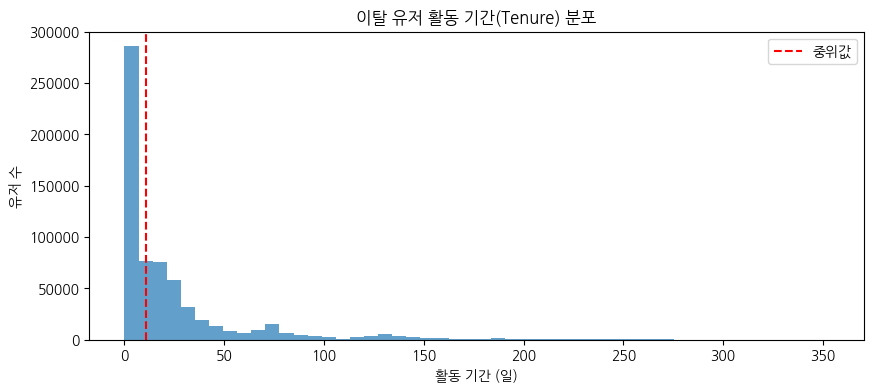

In [133]:
plt.figure(figsize=(10, 4))
plt.hist(churned_users_tenure['tenure_days'], bins=50, color='tab:blue', alpha=0.7)
plt.axvline(churned_users_tenure['tenure_days'].median(), color='red', linestyle='--', label='중위값')
plt.xlabel('활동 기간 (일)')
plt.ylabel('유저 수')
plt.title('이탈 유저 활동 기간(Tenure) 분포')
plt.legend()
plt.show()

In [134]:
churned_users_tenure['tenure_group_4'] = pd.qcut(
    churned_users_tenure['tenure_days'],
    q=4,
    labels=['Q1', 'Q2', 'Q3', 'Q4']
)

# 각 구간의 실제 범위와 중앙값 확인
churned_users_tenure.groupby('tenure_group_4', observed=True)['tenure_days'].agg(['min', 'max', 'median', 'mean', 'count'])

,min,max,median,mean,count
tenure_group_4,,,,,
Q1,0,1,0.00,0.21,171351
Q2,2,11,5.00,5.62,160221
Q3,12,27,19.00,19.10,158350
Q4,28,353,58.00,76.47,161868


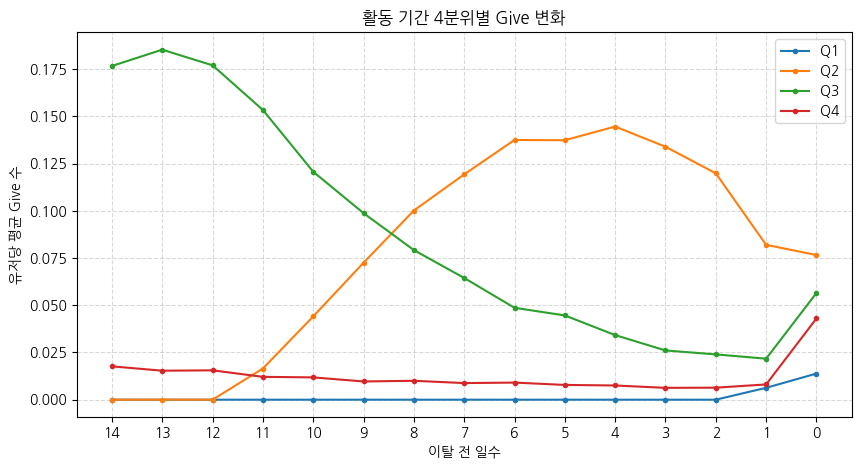

In [135]:
daily_user_stats_q4 = daily_user_stats.merge(
    churned_users_tenure[['user_id', 'tenure_group_4']],
    left_on='churned_user_id', right_on='user_id',
    how='left'
)

total_by_q4 = churned_users_tenure.groupby('tenure_group_4', observed=True)['user_id'].nunique()

q4_14 = daily_user_stats_q4[
    daily_user_stats_q4['days_before_churn'].between(0, 14)
]

q4_sum = (
    q4_14
    .groupby(['tenure_group_4', 'days_before_churn'], observed=True)
    .agg(give_sum=('give', 'sum'), take_sum=('take', 'sum'))
    .reset_index()
)

q4_sum['total_users'] = q4_sum['tenure_group_4'].map(total_by_q4).astype(int)
q4_sum['give'] = q4_sum['give_sum'] / q4_sum['total_users']

plt.figure(figsize=(10, 5))
for group in ['Q1', 'Q2', 'Q3', 'Q4']:
    subset = q4_sum[q4_sum['tenure_group_4'] == group]
    plt.plot(subset['days_before_churn'], subset['give'], label=group, marker='o', markersize=3)

plt.xticks(range(0, 15, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('유저당 평균 Give 수')
plt.title('활동 기간 4분위별 Give 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

In [136]:
# 그룹별, 날짜별로 "그 날짜에 활동 이력이 있을 수 있는(tenure >= day) 유저 수"를 분모로 계산

max_day = 28

# 각 그룹, 각 day에 대해 eligible(자격 있는) 유저 수 계산
eligible_counts = []
for group in ['Q2', 'Q3', 'Q4']:
    group_tenure = churned_users_tenure[churned_users_tenure['tenure_group_4'] == group]['tenure_days']
    for day in range(0, max_day + 1):
        eligible = (group_tenure >= day).sum()
        eligible_counts.append({'tenure_group_4': group, 'days_before_churn': day, 'eligible_users': eligible})

eligible_df = pd.DataFrame(eligible_counts)

# 기존 q4_sum과 병합
q4_sum_28 = (
    daily_user_stats_q4[daily_user_stats_q4['days_before_churn'].between(0, max_day)]
    .groupby(['tenure_group_4', 'days_before_churn'], observed=True)
    .agg(give_sum=('give', 'sum'), take_sum=('take', 'sum'))
    .reset_index()
)

q4_sum_28 = q4_sum_28.merge(eligible_df, on=['tenure_group_4', 'days_before_churn'])

q4_sum_28['give'] = q4_sum_28['give_sum'] / q4_sum_28['eligible_users']
q4_sum_28['take'] = q4_sum_28['take_sum'] / q4_sum_28['eligible_users']

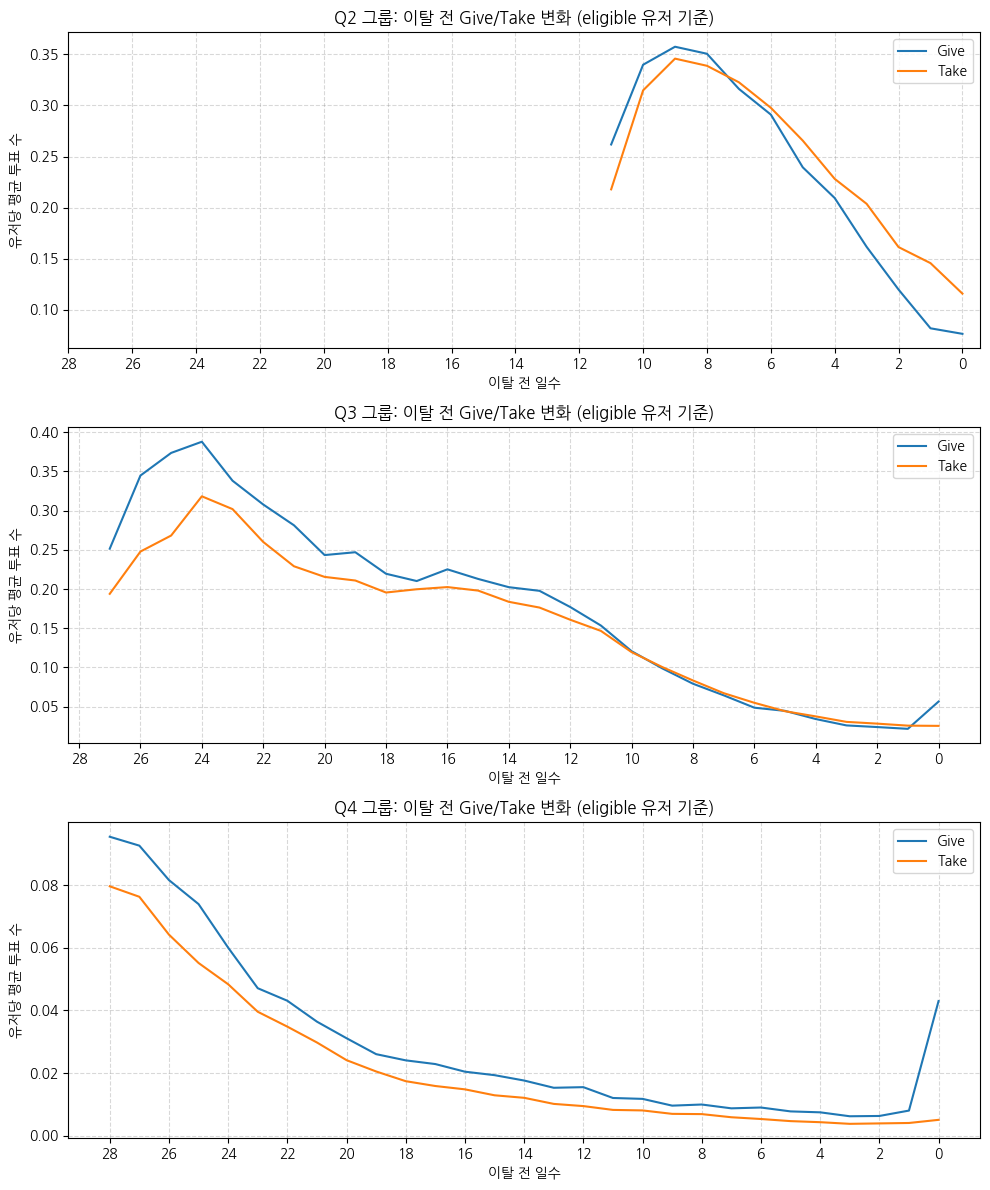

In [137]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for ax, group in zip(axes, ['Q2', 'Q3', 'Q4']):
    subset = q4_sum_28[q4_sum_28['tenure_group_4'] == group]
    ax.plot(subset['days_before_churn'], subset['give'], label='Give')
    ax.plot(subset['days_before_churn'], subset['take'], label='Take')
    ax.set_xticks(range(0, max_day + 1, 2))
    ax.invert_xaxis()
    ax.set_xlabel('이탈 전 일수')
    ax.set_ylabel('유저당 평균 투표 수')
    ax.set_title(f'{group} 그룹: 이탈 전 Give/Take 변화 (eligible 유저 기준)')
    ax.grid(color='gray', linestyle='--', alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [138]:
# Q1 제외, Q2~Q4만 남기기
churned_users_tenure_q = churned_users_tenure[
    churned_users_tenure['tenure_group_4'] != 'Q1'
]

total_by_q = churned_users_tenure_q.groupby('tenure_group_4', observed=True)['user_id'].nunique().to_dict()

# daily_user_stats에 그룹 정보 병합
daily_user_stats_q = daily_user_stats.merge(
    churned_users_tenure_q[['user_id', 'tenure_group_4']],
    left_on='churned_user_id', right_on='user_id',
    how='inner'
)

# 관계 수용: churn_relations에도 그룹 정보 병합
churn_relations_q = churn_relations.merge(
    churned_users_tenure_q[['user_id', 'tenure_group_4']],
    left_on='churned_user_id', right_on='user_id',
    how='inner'
)

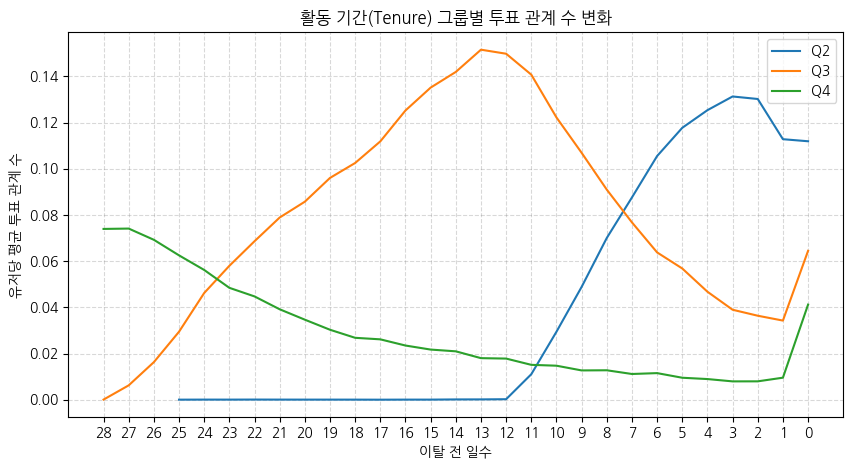

In [139]:
q_pair_avg = (
    churn_relations_q[churn_relations_q['days_before_churn'].between(0, 28)]
    .groupby(['tenure_group_4', 'days_before_churn', 'churned_user_id', 'pair_1', 'pair_2'], observed=True)
    .size()
    .reset_index(name='dummy')
    .groupby(['tenure_group_4', 'days_before_churn'], observed=True)
    .size()
    .reset_index(name='relation_count')
)
q_pair_avg['total_users'] = q_pair_avg['tenure_group_4'].map(total_by_q)
q_pair_avg['relation_count'] = q_pair_avg['relation_count'] / q_pair_avg['total_users']

plt.figure(figsize=(10, 5))
for group in ['Q2', 'Q3', 'Q4']:
    subset = q_pair_avg[q_pair_avg['tenure_group_4'] == group]
    plt.plot(subset['days_before_churn'], subset['relation_count'], label=group)

plt.xticks(range(0, 29, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('유저당 평균 투표 관계 수')
plt.title('활동 기간(Tenure) 그룹별 투표 관계 수 변화')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

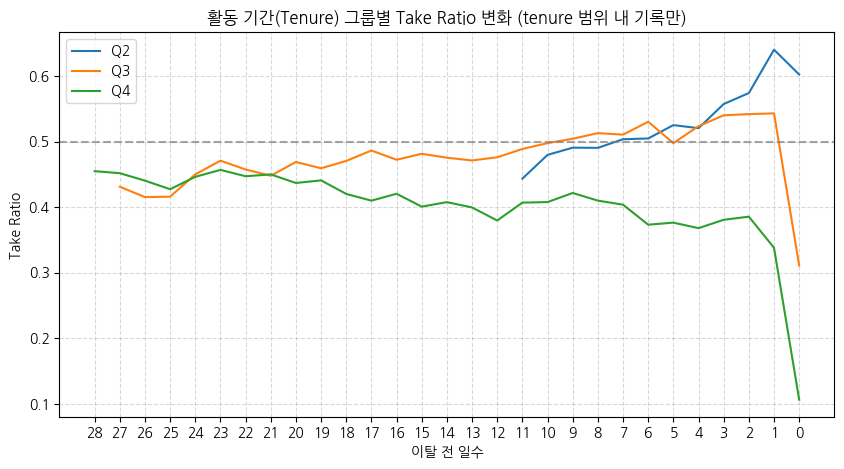

In [140]:
# tenure 범위 안의 기록만 사용 (172번 셀의 eligible 기준과 정합성을 맞추기 위함)
churn_relations_q2 = churn_relations_q.merge(
    churned_users_tenure_q[['user_id', 'tenure_days']],
    left_on='churned_user_id', right_on='user_id',
    how='left',
    suffixes=('', '_tenure')
)

churn_relations_q2 = churn_relations_q2[
    churn_relations_q2['days_before_churn'] <= churn_relations_q2['tenure_days']
]

q_daily = (
    churn_relations_q2[churn_relations_q2['days_before_churn'].between(0, 28)]
    .groupby(['tenure_group_4', 'days_before_churn'], observed=True)
    .agg(
        give_sum=('role', lambda x: (x == 'give').sum()),
        take_sum=('role', lambda x: (x == 'take').sum())
    )
    .reset_index()
)

q_daily['take_ratio'] = q_daily['take_sum'] / (q_daily['give_sum'] + q_daily['take_sum'])

# Take Ratio 비교
plt.figure(figsize=(10, 5))
for group in ['Q2', 'Q3', 'Q4']:
    subset = q_daily[q_daily['tenure_group_4'] == group]
    plt.plot(subset['days_before_churn'], subset['take_ratio'], label=group)

plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.7)
plt.xticks(range(0, 29, 1))
plt.gca().invert_xaxis()
plt.xlabel('이탈 전 일수')
plt.ylabel('Take Ratio')
plt.title('활동 기간(Tenure) 그룹별 Take Ratio 변화 (tenure 범위 내 기록만)')
plt.grid(color='gray', linestyle='--', alpha=0.3)
plt.legend()
plt.show()

In [141]:
pair_period_3d_q = pair_period_3d.merge(
    churned_users_tenure[churned_users_tenure['tenure_group_4'] != 'Q1'][['user_id', 'tenure_group_4']],
    left_on='churned_user_id', right_on='user_id',
    how='inner'
)

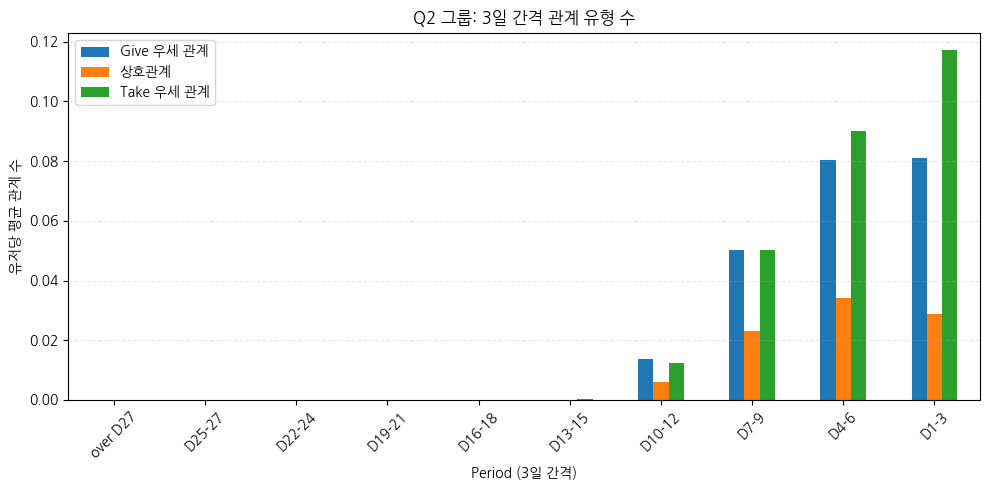

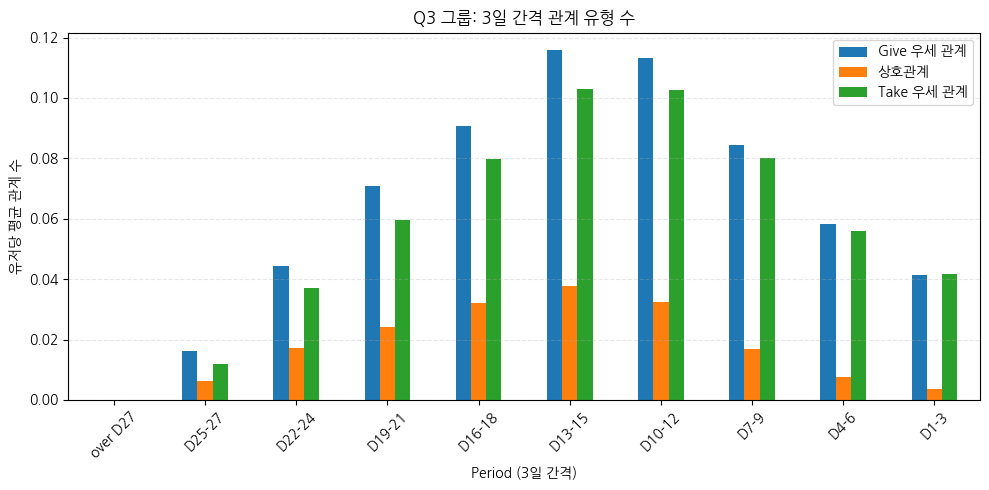

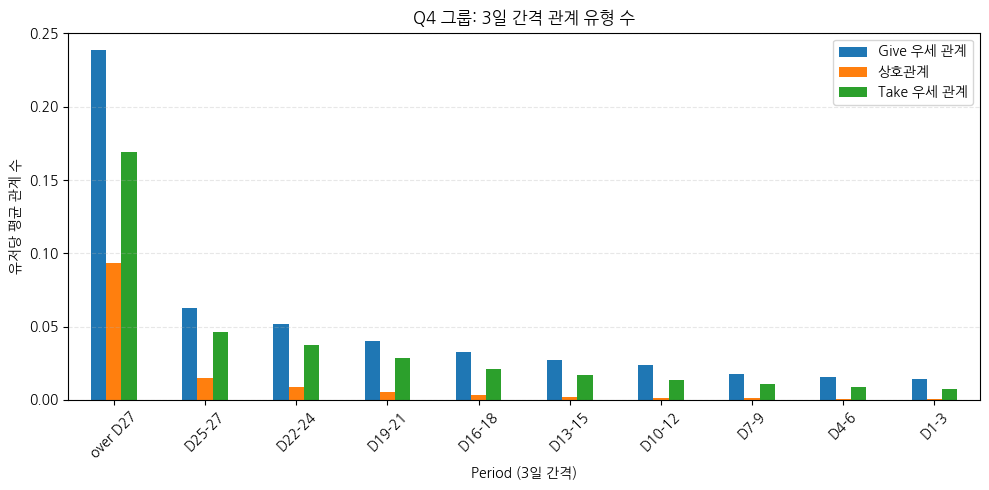

In [142]:
period_order_3d = bin_labels_3d[::-1]

pair_period_3d_q['period_3d'] = pd.Categorical(
    pair_period_3d_q['period_3d'],
    categories=period_order_3d,
    ordered=True
)

total_by_q = churned_users_tenure[churned_users_tenure['tenure_group_4'] != 'Q1'].groupby('tenure_group_4', observed=True)['user_id'].nunique().to_dict()

for group in ['Q2', 'Q3', 'Q4']:
    subset_q = pair_period_3d_q[pair_period_3d_q['tenure_group_4'] == group]

    relation_avg_q = (
        subset_q
        .groupby(['period_3d', 'relation_type_2'], observed=True)
        .size()
        .reset_index(name='count')
    )
    relation_avg_q['count'] = relation_avg_q['count'] / total_by_q[group]

    pivot_q = relation_avg_q.pivot(index='period_3d', columns='relation_type_2', values='count')
    pivot_q = pivot_q.reindex(period_order_3d)

    plt.figure(figsize=(10, 5))
    pivot_q.plot(kind='bar', ax=plt.gca())
    plt.title(f'{group} 그룹: 3일 간격 관계 유형 수')
    plt.xlabel('Period (3일 간격)')
    plt.ylabel('유저당 평균 관계 수')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend(title=None)
    plt.tight_layout()
    plt.show()

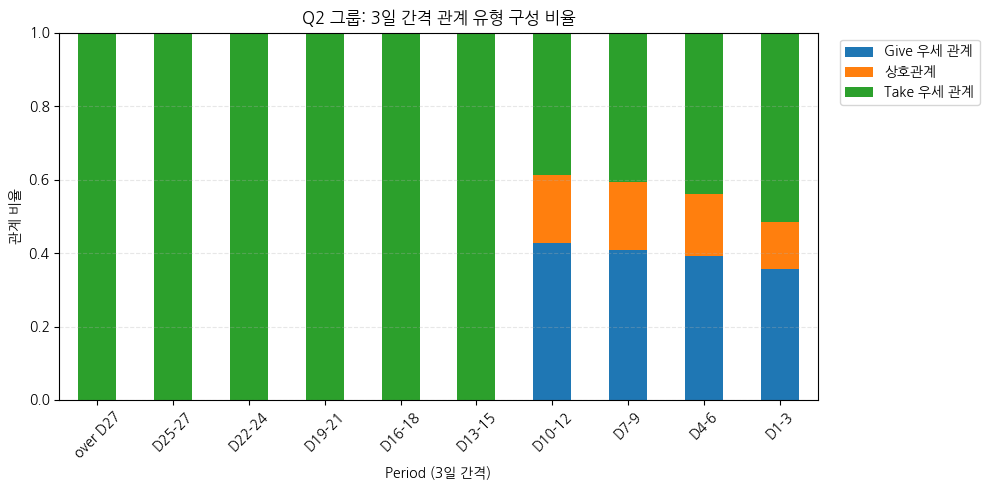

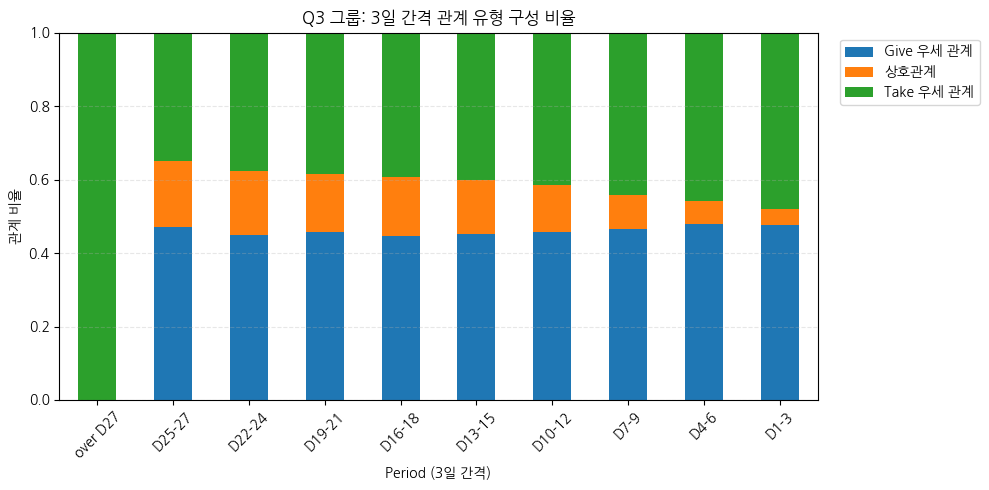

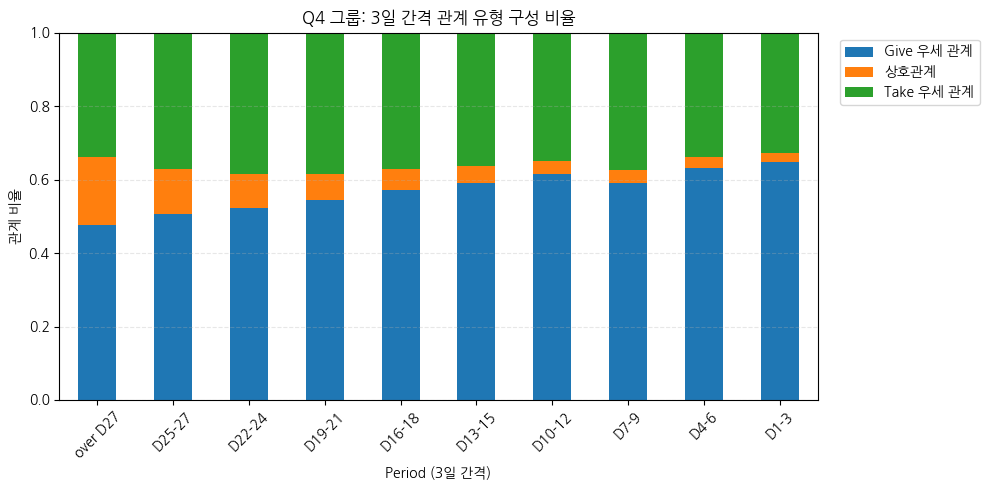

In [143]:
for group in ['Q2', 'Q3', 'Q4']:
    subset_q = pair_period_3d_q[pair_period_3d_q['tenure_group_4'] == group]

    relation_count_q = (
        subset_q
        .groupby(['period_3d', 'relation_type_2'], observed=True)
        .size()
        .reset_index(name='count')
    )
    relation_count_q['ratio'] = (
        relation_count_q['count'] /
        relation_count_q.groupby('period_3d', observed=False)['count'].transform('sum')
    )

    pivot_ratio_q = relation_count_q.pivot(index='period_3d', columns='relation_type_2', values='ratio')
    pivot_ratio_q = pivot_ratio_q.reindex(period_order_3d)

    plt.figure(figsize=(10, 5))
    pivot_ratio_q.plot(kind='bar', stacked=True, ax=plt.gca())
    plt.title(f'{group} 그룹: 3일 간격 관계 유형 구성 비율')
    plt.xlabel('Period (3일 간격)')
    plt.ylabel('관계 비율')
    plt.ylim(0, 1)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

## 투표 한 유저만 대상으로 추출
조건
* 3일 이상 투표
* 첫 투표에서 마지막 투표일까지 최소 7일 이상
* 28일 연속 비활성 이후 재유입하지 않음

In [144]:
accounts_userquestionrecord = clean_accounts_userquestionrecord()

In [145]:
# 데이터 준비
df = accounts_userquestionrecord.copy()
df["created_at"] = pd.to_datetime(df["created_at"]).dt.date
result = df[["user_id", "chosen_user_id", "created_at"]]

result.head()

,user_id,chosen_user_id,created_at
0,849436,849469,2023-04-28
1,849436,849446,2023-04-28
2,849436,849454,2023-04-28
3,849436,847375,2023-04-28
4,849436,849477,2023-04-28


In [146]:
# 유저별 활동일수(active_days) / 활동 기간(span) 계산

# 유저별로 며칠 동안 활동했는지 (고유 활동일 수)
active_days = (
    result.groupby('user_id')['created_at']
    .nunique()
    .reset_index(name='active_days')
)

# 유저별 첫 활동일 / 마지막 활동일 / 그 사이 기간(span_days)
span = (
    result.groupby('user_id')['created_at']
    .agg(first_day='min', last_day='max')
    .reset_index()
)
span['first_day'] = pd.to_datetime(span['first_day'])
span['last_day'] = pd.to_datetime(span['last_day'])
span['span_days'] = (span['last_day'] - span['first_day']).dt.days

display(active_days.head())
display(span.head())

,user_id,active_days
0,838023,5
1,838466,8
2,838642,2
3,839357,9
4,840293,7


,user_id,first_day,last_day,span_days
0,838023,2023-04-29,2023-05-04,5
1,838466,2023-05-02,2023-09-18,139
2,838642,2023-04-28,2023-04-29,1
3,839357,2023-04-29,2023-05-26,27
4,840293,2023-05-03,2023-05-15,12


In [147]:
# 필터 조건별 유저 집합 정리 + 전체 요약 출력

# 조건별 유저 id 집합
total_ids    = set(result['user_id'])
active_3_ids = set(active_days.loc[active_days['active_days'] >= 3, 'user_id'])
span_7_ids   = set(span.loc[span['span_days'] >= 7, 'user_id'])
both_ids     = active_3_ids & span_7_ids

total = len(total_ids)

def pct(n):
    return f"{n / total * 100:.1f}%"

print(f"전체 투표 유저                       : {total:,}명")
print()
print(f"3일 이상 투표 유저                    : {len(active_3_ids):,}명 ({pct(len(active_3_ids))})")
print(f"첫~마지막 투표 간격 7일 이상 유저      : {len(span_7_ids):,}명 ({pct(len(span_7_ids))})")
print(f"3일 이상 + 간격 7일 이상 유저 (둘 다)  : {len(both_ids):,}명 ({pct(len(both_ids))})")

전체 투표 유저                       : 4,849명

3일 이상 투표 유저                    : 4,564명 (94.1%)
첫~마지막 투표 간격 7일 이상 유저      : 3,827명 (78.9%)
3일 이상 + 간격 7일 이상 유저 (둘 다)  : 3,811명 (78.6%)


In [148]:
# 활동 기간(span_days)을 구간(span_group)으로 나누고 그룹별 집계

bins = [7, 14, 21, 28, 56, float('inf')]
labels = ['7~13일', '14~20일', '21~27일', '28~55일', '56일 이상']
span['span_group'] = pd.cut(span['span_days'], bins=bins, labels=labels, right=False)
span['is_active_3'] = span['user_id'].isin(active_3_ids)

# 구간별 유저 수 / 3일 이상 투표 유저 수 / 비율
group_df = (
    span.dropna(subset=['span_group'])
    .groupby('span_group', observed=True)
    .agg(users=('user_id', 'nunique'), active_3_users=('is_active_3', 'sum'))
)
group_df['전체 대비 비율(%)'] = (group_df['active_3_users'] / total * 100).round(2)
group_df['3일 이상 투표 비율(%)'] = (group_df['active_3_users'] / group_df['users'] * 100).round(1)

group_df[['active_3_users', '전체 대비 비율(%)']]

,active_3_users,전체 대비 비율(%)
span_group,,
7~13일,1106,22.81
14~20일,827,17.06
21~27일,579,11.94
28~55일,707,14.58
56일 이상,592,12.21


In [149]:
# 분석 대상(target) 유저 추출 — 3일 이상 투표 + 간격 7일 이상

target_ids = both_ids
target_span = span.loc[
    span['user_id'].isin(target_ids),
    ['user_id', 'first_day', 'last_day', 'span_days', 'span_group']
].reset_index(drop=True)

print(f"대상 유저 : {len(target_ids):,}명")
print(target_span['span_group'].value_counts(sort=False))
print()
target_span.head()

대상 유저 : 3,811명
span_group
7~13일     1106
14~20일     827
21~27일     579
28~55일     707
56일 이상     592
Name: count, dtype: int64



,user_id,first_day,last_day,span_days,span_group
0,838466,2023-05-02,2023-09-18,139,56일 이상
1,839357,2023-04-29,2023-05-26,27,21~27일
2,840293,2023-05-03,2023-05-15,12,7~13일
3,840473,2023-05-03,2023-06-16,44,28~55일
4,840512,2023-05-03,2023-07-11,69,56일 이상


In [150]:
# '진짜 이탈' 조건 추가 — 마지막 활동 후 N일 이상 미접속 (90일 / 28일 각각 독립 계산)

# 데이터셋 마지막 날짜 기준, 유저별 마지막 활동 후 며칠 지났는지
data_end = pd.to_datetime(result['created_at'].max())
target_span['days_since_last'] = (data_end - target_span['last_day']).dt.days

def apply_churn_filter(n_days):
    ids = set(target_span.loc[target_span['days_since_last'] >= n_days, 'user_id'])
    span_filtered = target_span[target_span['user_id'].isin(ids)].reset_index(drop=True)
    print(f"{n_days}일 이상 미접속(진짜 이탈) 유저 : {len(ids):,}명 ({pct(len(ids))})")

    # 그룹별 인원수 + 전체(4,849명) 대비 비율
    summary = span_filtered['span_group'].value_counts(sort=False).to_frame('users')
    summary['전체 대비 비율(%)'] = (summary['users'] / total * 100).round(2)
    display(summary)

    return ids, span_filtered

target_ids_90, target_span_90 = apply_churn_filter(90)
print()
target_ids_28, target_span_28 = apply_churn_filter(28)

print()
display(target_span_90.head())
display(target_span_28.head())

# 최종적으로 사용할 이탈 기준: 28일 이상 미접속
target_ids, target_span = target_ids_28, target_span_28

90일 이상 미접속(진짜 이탈) 유저 : 3,785명 (78.1%)


,users,전체 대비 비율(%)
span_group,,
7~13일,1106,22.81
14~20일,827,17.06
21~27일,579,11.94
28~55일,707,14.58
56일 이상,566,11.67



28일 이상 미접속(진짜 이탈) 유저 : 3,801명 (78.4%)


,users,전체 대비 비율(%)
span_group,,
7~13일,1106,22.81
14~20일,827,17.06
21~27일,579,11.94
28~55일,707,14.58
56일 이상,582,12.00


,user_id,first_day,last_day,span_days,span_group,days_since_last
0,838466,2023-05-02,2023-09-18,139,56일 이상,233
1,839357,2023-04-29,2023-05-26,27,21~27일,348
2,840293,2023-05-03,2023-05-15,12,7~13일,359
3,840473,2023-05-03,2023-06-16,44,28~55일,327
4,840512,2023-05-03,2023-07-11,69,56일 이상,302


,user_id,first_day,last_day,span_days,span_group,days_since_last
0,838466,2023-05-02,2023-09-18,139,56일 이상,233
1,839357,2023-04-29,2023-05-26,27,21~27일,348
2,840293,2023-05-03,2023-05-15,12,7~13일,359
3,840473,2023-05-03,2023-06-16,44,28~55일,327
4,840512,2023-05-03,2023-07-11,69,56일 이상,302


In [151]:
# 최종적으로 사용할 이탈 기준: 28일 이상 미접속
target_ids, target_span = target_ids_28, target_span_28

In [152]:
# give: 대상 유저가 투표한 행
give_df = result[result['user_id'].isin(target_ids)].copy()

# take: 대상 유저가 투표받은 행 (투표한 사람은 대상이 아니어도 포함)
take_df = result[result['chosen_user_id'].isin(target_ids)].copy()

print(f"give 행 수 : {len(give_df):,}")
print(f"take 행 수 : {len(take_df):,}")

give 행 수 : 1,115,856
take 행 수 : 870,478


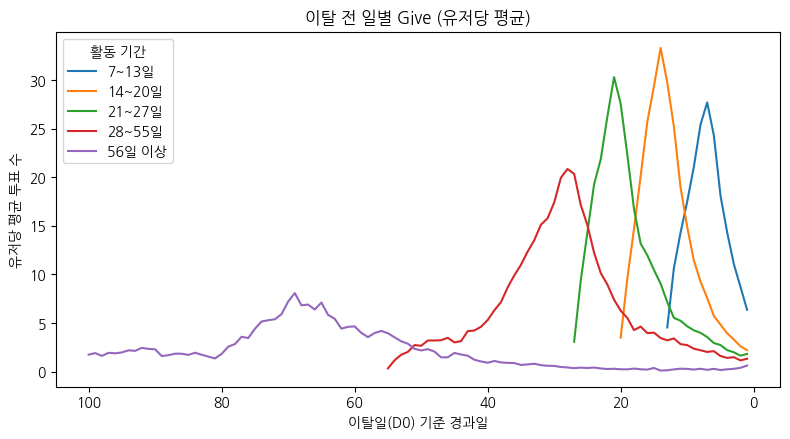

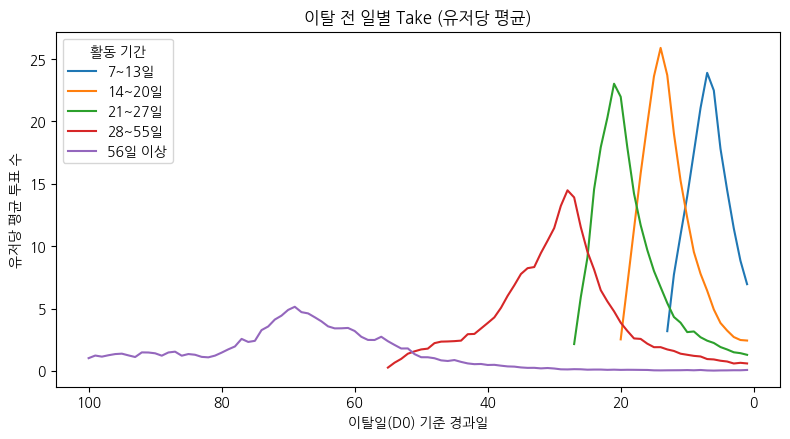

In [153]:
def daily_avg(df, user_col, group_label):
    """이탈일(D0) 기준, 특정 그룹의 일별 유저당 평균 투표 수"""
    users = target_span[target_span['span_group'] == group_label]
    df = df[df[user_col].isin(users['user_id'])].copy()

    last_day = df[user_col].map(users.set_index('user_id')['last_day'])
    df['days_before'] = (last_day - pd.to_datetime(df['created_at'])).dt.days
    df = df[df['days_before'] > 0]

    return df.groupby('days_before').size() / len(users)

max_days = {'7~13일': 13, '14~20일': 20, '21~27일': 27, '28~55일': 55, '56일 이상': 100}

for title, source, col in [('Give', give_df, 'user_id'), ('Take', take_df, 'chosen_user_id')]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for label in labels:
        series = daily_avg(source, col, label)
        n = max_days[label]
        ax.plot(series.loc[:n].index, series.loc[:n].values, label=label)

    ax.set_title(f'이탈 전 일별 {title} (유저당 평균)')
    ax.set_xlabel('이탈일(D0) 기준 경과일')
    ax.set_ylabel('유저당 평균 투표 수')
    ax.invert_xaxis()
    ax.legend(title='활동 기간')
    plt.tight_layout()
    plt.show()

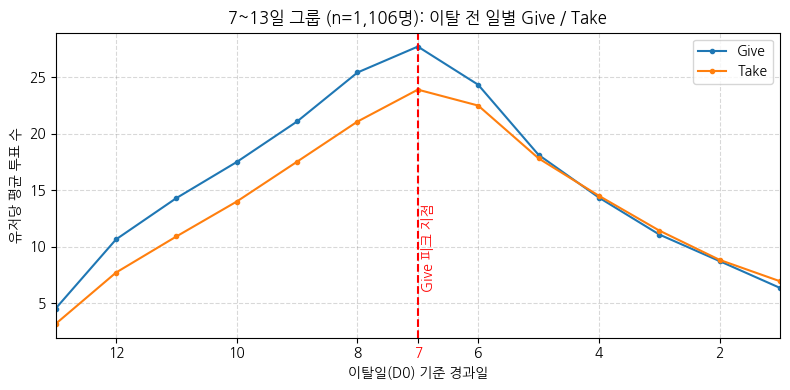

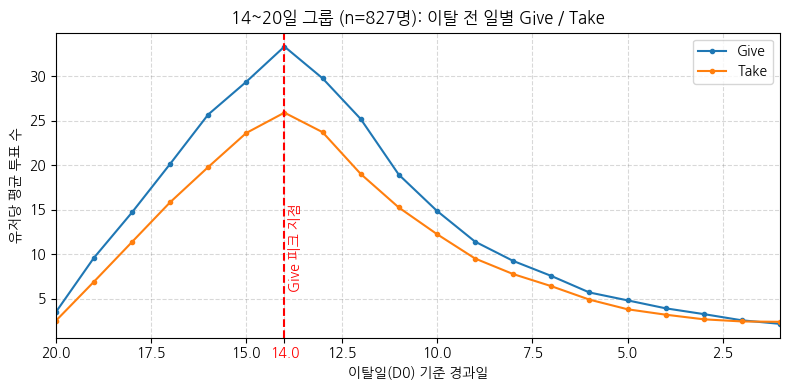

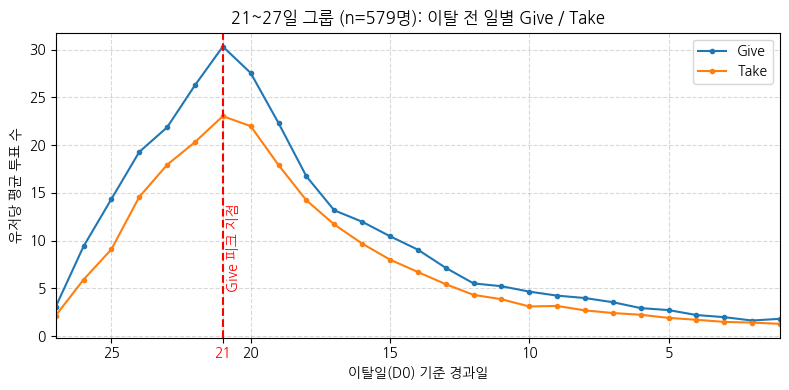

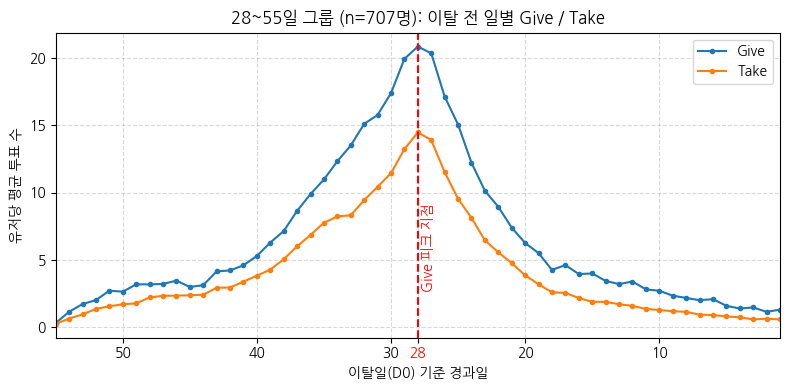

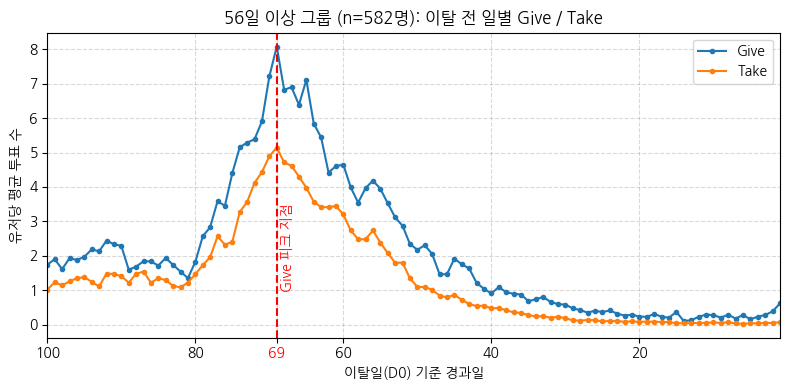

In [154]:
max_days = {'7~13일': 13, '14~20일': 20, '21~27일': 27, '28~55일': 55, '56일 이상': 100}

for label in labels:
    give = daily_avg(give_df, 'user_id', label).loc[:max_days[label]]
    take = daily_avg(take_df, 'chosen_user_id', label).loc[:max_days[label]]
    users = (target_span['span_group'] == label).sum()

    peak_day = give.idxmax()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(give.index, give.values, marker='o', markersize=3, label='Give')
    ax.plot(take.index, take.values, marker='o', markersize=3, label='Take')

    ax.axvline(x=peak_day, color='red', linestyle='--', linewidth=1.5)
    y_min, y_max = ax.get_ylim()
    ax.annotate('Give 피크 지점', xy=(peak_day, y_min + (y_max - y_min) * 0.15),
                xytext=(3, 0), textcoords='offset points',
                color='red', rotation=90, ha='left', va='bottom')

    ax.set_title(f'{label} 그룹 (n={users:,}명): 이탈 전 일별 Give / Take')
    ax.set_xlabel('이탈일(D0) 기준 경과일')
    ax.set_ylabel('유저당 평균 투표 수')
    ax.grid(color='gray', linestyle='--', alpha=0.3)

    ax.set_xticks(sorted(set(ax.get_xticks()) | {peak_day}))
    for tick, tick_label in zip(ax.get_xticks(), ax.get_xticklabels()):
        if tick == peak_day:
            tick_label.set_color('red')

    ax.set_xlim(max_days[label], 1)   # 오른쪽 끝을 정확히 0으로 고정 (invert_xaxis 대체)
    ax.legend()
    plt.tight_layout()
    plt.show()

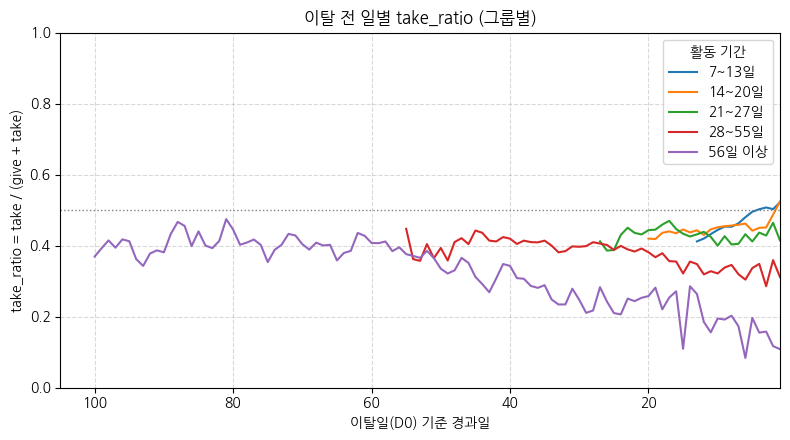

In [155]:
max_days = {'7~13일': 13, '14~20일': 20, '21~27일': 27, '28~55일': 55, '56일 이상': 100}

fig, ax = plt.subplots(figsize=(8, 4.5))

for label in labels:
    give = daily_avg(give_df, 'user_id', label).loc[:max_days[label]]
    take = daily_avg(take_df, 'chosen_user_id', label).loc[:max_days[label]]

    # give/take 날짜(days_before)를 맞춰서 정렬 (한쪽에만 있는 날은 0으로 채움)
    idx = sorted(set(give.index) | set(take.index))
    give_aligned = give.reindex(idx, fill_value=0)
    take_aligned = take.reindex(idx, fill_value=0)

    total = give_aligned + take_aligned
    take_ratio = (take_aligned / total).where(total > 0)  # 그날 활동이 아예 없으면 제외

    ax.plot(take_ratio.index, take_ratio.values, label=label)

ax.axhline(y=0.5, color='gray', linestyle=':', linewidth=1)  # 0.5 = give/take 균형선

ax.set_title('이탈 전 일별 take_ratio (그룹별)')
ax.set_xlabel('이탈일(D0) 기준 경과일')
ax.set_ylabel('take_ratio = take / (give + take)')
ax.grid(color='gray', linestyle='--', alpha=0.3)
ax.set_ylim(0, 1)
ax.invert_xaxis()
ax.set_xlim(right=1)
ax.legend(title='활동 기간')
plt.tight_layout()
plt.show()

# 투표관계 재설정
| take_ratio | 관계 유형 |
|---|---|
| 0 ~ 1/3 | Give 우세 관계 |
| 1/3 ~ 2/3 | 상호관계 |
| 2/3 ~ 1 | Take 우세 관계 |



In [156]:
bin_size = {'7~13일': 3, '14~20일': 3, '21~27일': 3, '28~55일': 3, '56일 이상': 3}
max_days = {'7~13일': 13, '14~20일': 20, '21~27일': 27, '28~55일': 55, '56일 이상': 100}

def relation_counts(group_label):
    size = bin_size[group_label]
    n_bins = max_days[group_label] // size          # 그룹의 최대 구간 수
    users = target_span[target_span['span_group'] == group_label]
    last_day = users.set_index('user_id')['last_day']

    give = give_df[give_df['user_id'].isin(users['user_id'])].copy()
    give['me'], give['other'], give['give'], give['take'] = give['user_id'], give['chosen_user_id'], 1, 0

    take = take_df[take_df['chosen_user_id'].isin(users['user_id'])].copy()
    take['me'], take['other'], take['give'], take['take'] = take['chosen_user_id'], take['user_id'], 0, 1

    events = pd.concat([give, take])
    events = events[events['me'] != events['other']]

    events['days_before'] = (events['me'].map(last_day) - pd.to_datetime(events['created_at'])).dt.days
    events = events[(events['days_before'] > 0) & (events['days_before'] <= n_bins * size)]  # 상한 추가

    events['period'] = (events['days_before'] - 1) // size

    pair = events.groupby(['period', 'me', 'other'])[['give', 'take']].sum().reset_index()
    pair['take_ratio'] = pair['take'] / (pair['give'] + pair['take'])
    pair['type'] = pd.cut(pair['take_ratio'], bins=[-0.01, 1/3, 2/3, 1],
                           labels=['Give 우세 관계', '상호관계', 'Take 우세 관계'])

    table = pd.crosstab(pair['period'], pair['type'])
    table = table.reindex(range(n_bins), fill_value=0) / len(users)   # 빈 구간도 0으로 채우기
    table.index = [f'D{p*size+1}-{p*size+size}' for p in table.index]
    return table.iloc[::-1]

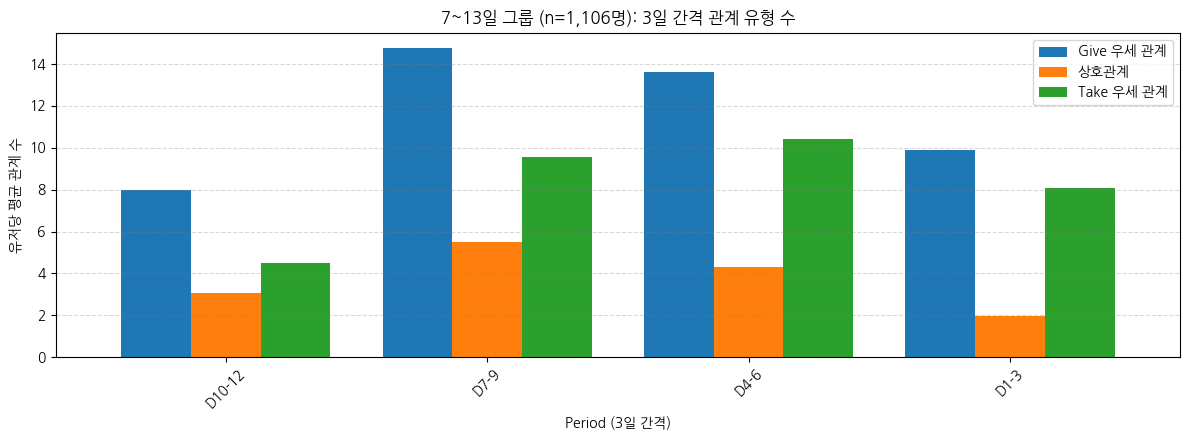

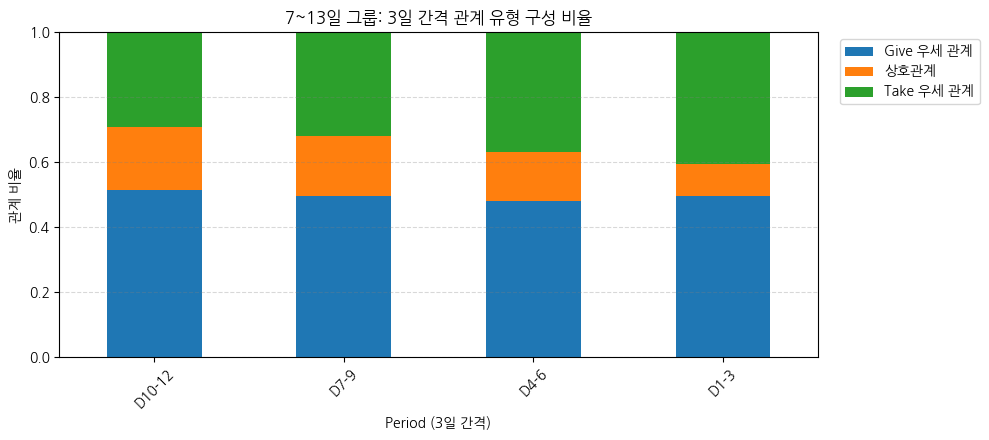

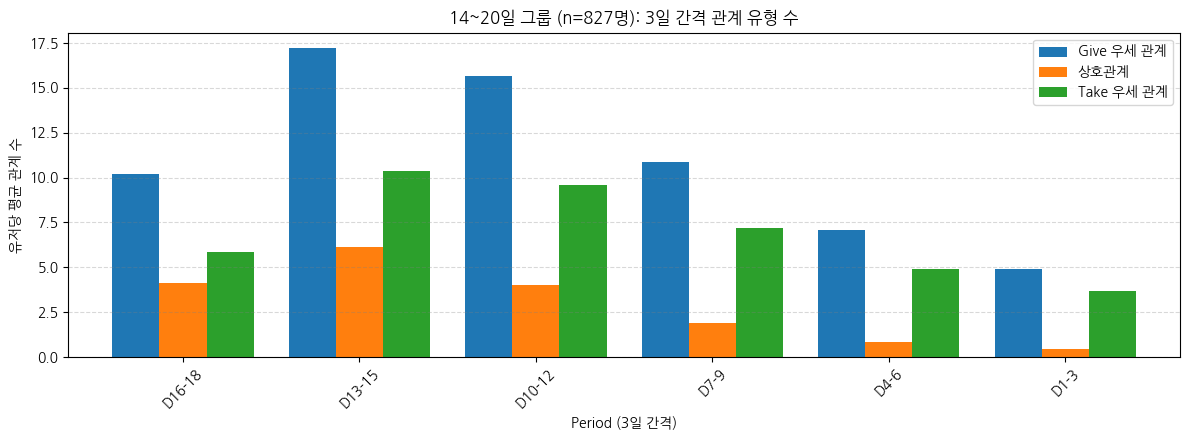

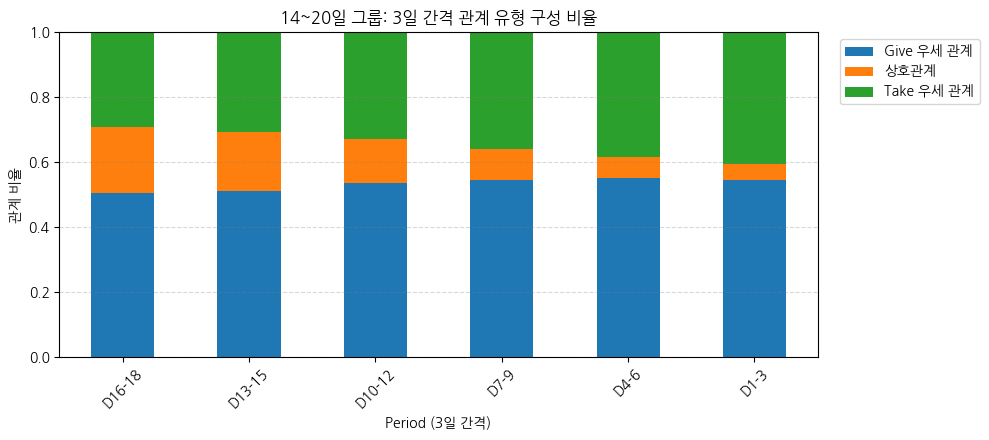

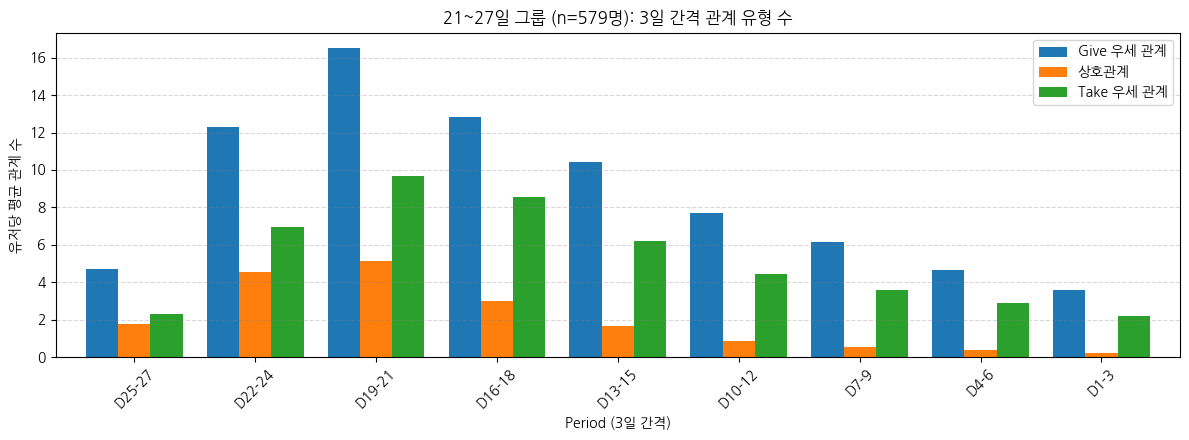

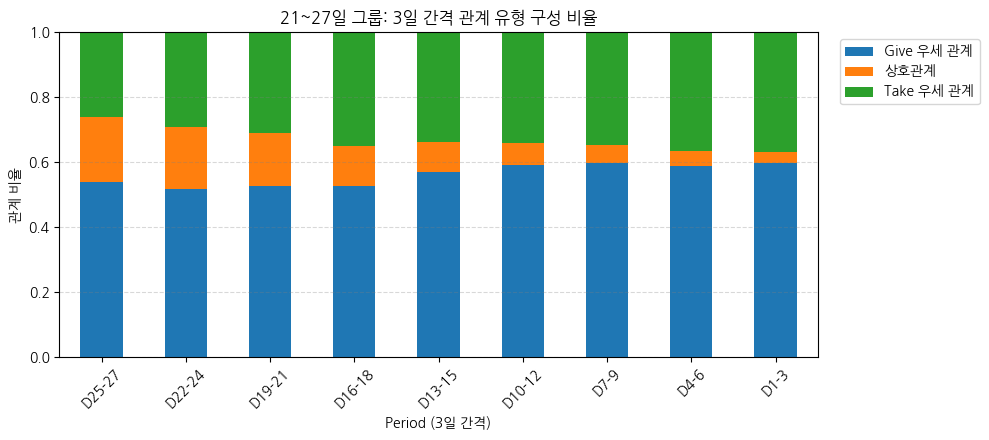

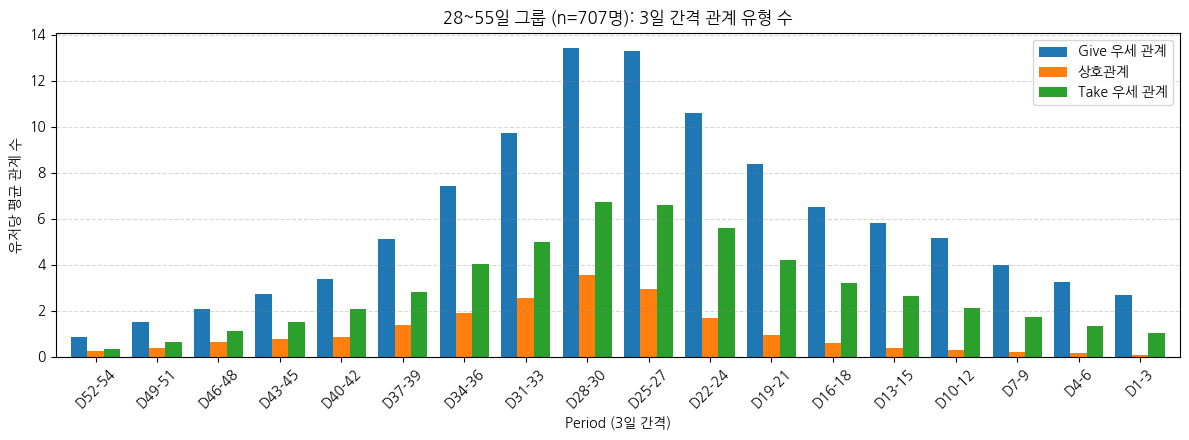

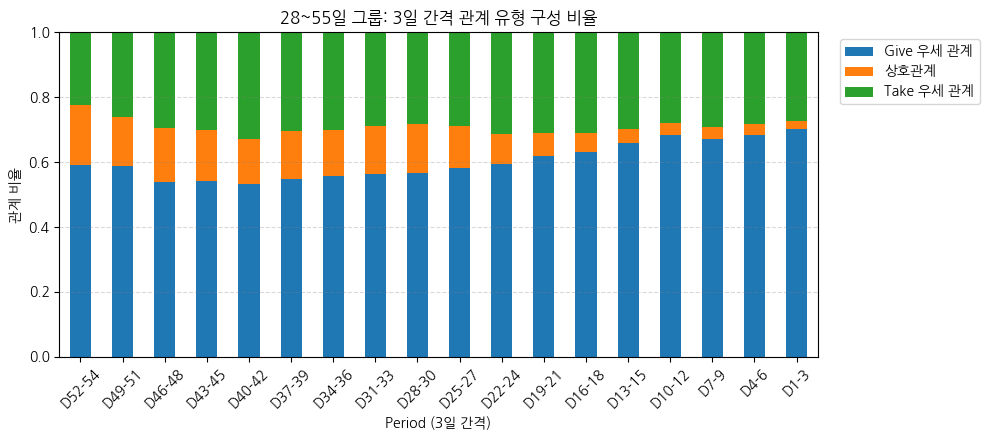

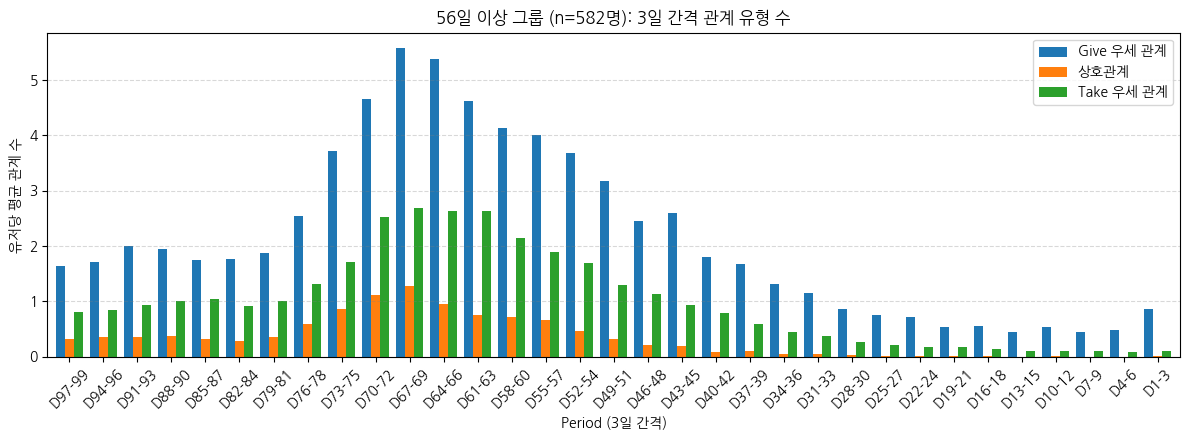

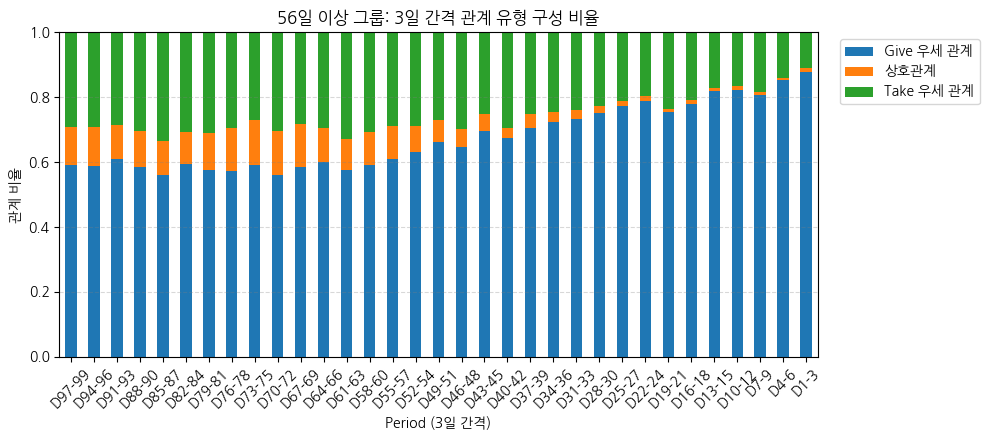

In [157]:
for label in labels:
    cnt = relation_counts(label)
    ratio = cnt.div(cnt.sum(axis=1), axis=0)
    n_users = (target_span['span_group'] == label).sum()

    ax = cnt.plot(kind='bar', figsize=(12, 4.5), width=0.8, rot=45)
    ax.set_title(f'{label} 그룹 (n={n_users:,}명): 3일 간격 관계 유형 수')
    ax.set_xlabel('Period (3일 간격)')
    ax.set_ylabel('유저당 평균 관계 수')
    ax.grid(axis='y', color='gray', linestyle='--', alpha=0.3)
    ax.legend(title=None)
    plt.tight_layout()
    plt.show()

    ax = ratio.plot(kind='bar', stacked=True, figsize=(10, 4.5), rot=45)
    ax.set_title(f'{label} 그룹: 3일 간격 관계 유형 구성 비율')
    ax.set_xlabel('Period (3일 간격)')
    ax.set_ylabel('관계 비율')
    ax.set_ylim(0, 1)
    ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(axis='y', color='gray', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

In [158]:
# 범위를 일주일 단위로 늘리기
bin_size = {'7~13일': 3, '14~20일': 7, '21~27일': 7, '28~55일': 7, '56일 이상': 7}
max_days = {'7~13일': 13, '14~20일': 21, '21~27일': 28, '28~55일': 56, '56일 이상': 98}

def relation_counts(group_label):
    size = bin_size[group_label]
    n_bins = max_days[group_label] // size          # 그룹의 최대 구간 수
    users = target_span[target_span['span_group'] == group_label]
    last_day = users.set_index('user_id')['last_day']

    give = give_df[give_df['user_id'].isin(users['user_id'])].copy()
    give['me'], give['other'], give['give'], give['take'] = give['user_id'], give['chosen_user_id'], 1, 0

    take = take_df[take_df['chosen_user_id'].isin(users['user_id'])].copy()
    take['me'], take['other'], take['give'], take['take'] = take['chosen_user_id'], take['user_id'], 0, 1

    events = pd.concat([give, take])
    events = events[events['me'] != events['other']]

    events['days_before'] = (events['me'].map(last_day) - pd.to_datetime(events['created_at'])).dt.days
    events = events[(events['days_before'] > 0) & (events['days_before'] <= n_bins * size)]  # 상한 추가

    events['period'] = (events['days_before'] - 1) // size

    pair = events.groupby(['period', 'me', 'other'])[['give', 'take']].sum().reset_index()
    pair['take_ratio'] = pair['take'] / (pair['give'] + pair['take'])
    pair['type'] = pd.cut(pair['take_ratio'], bins=[-0.01, 1/3, 2/3, 1],
                           labels=['Give 우세 관계', '상호관계', 'Take 우세 관계'])

    table = pd.crosstab(pair['period'], pair['type'])
    table = table.reindex(range(n_bins), fill_value=0) / len(users)   # 빈 구간도 0으로 채우기
    table.index = [f'D{p*size+1}-{p*size+size}' for p in table.index]
    return table.iloc[::-1]

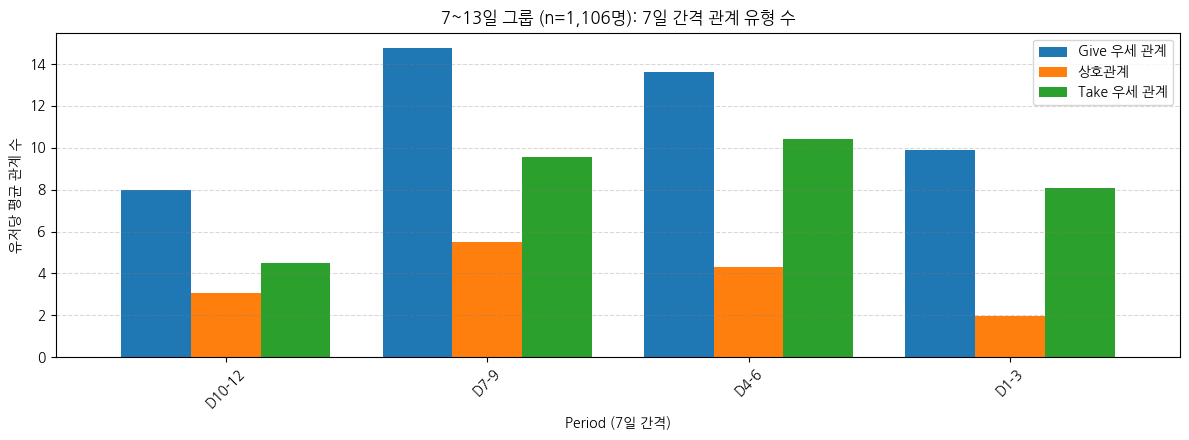

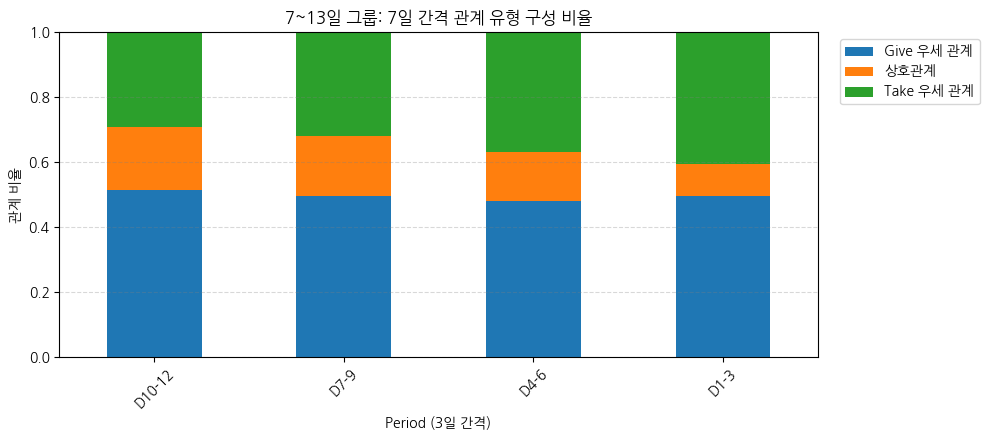

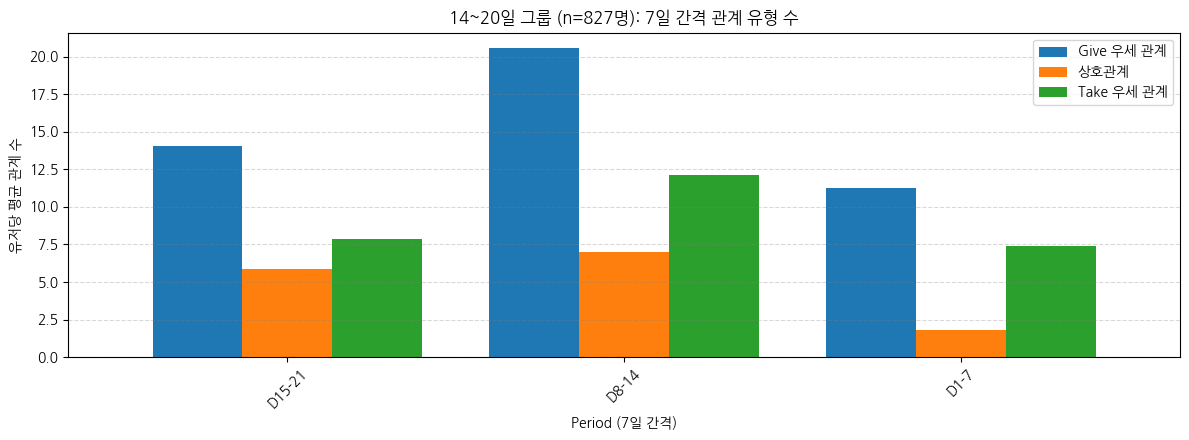

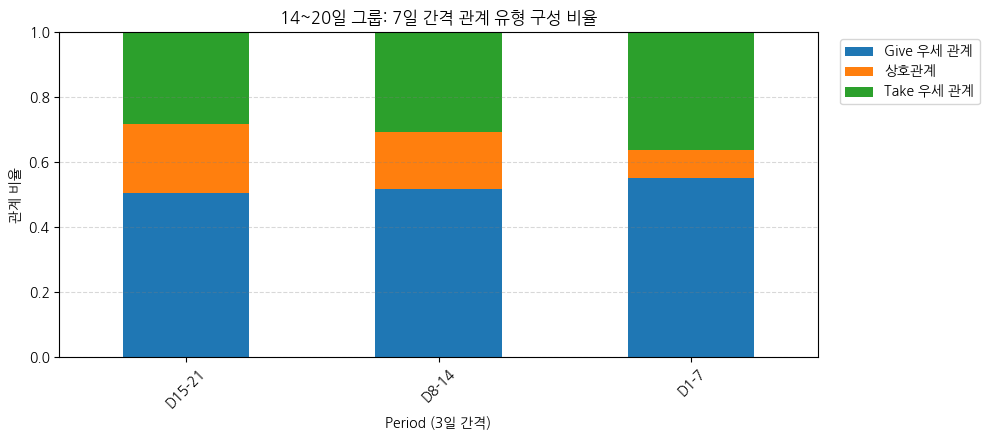

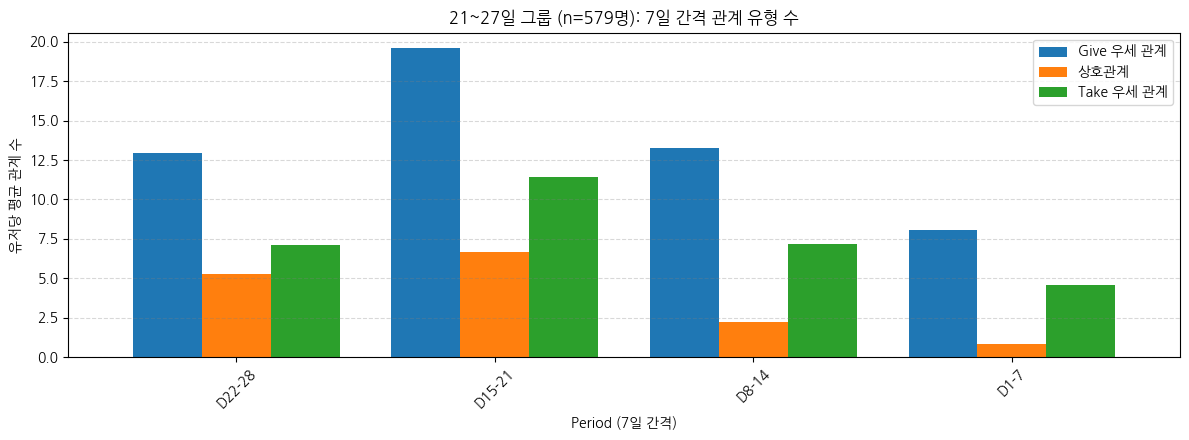

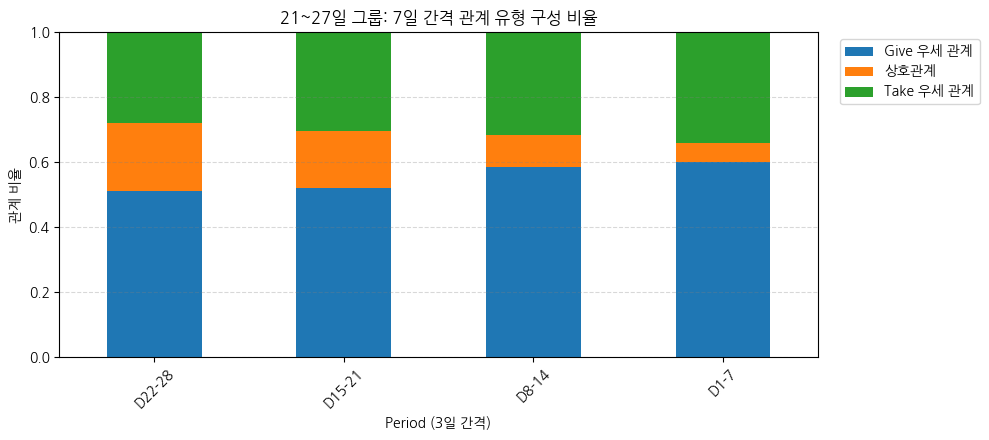

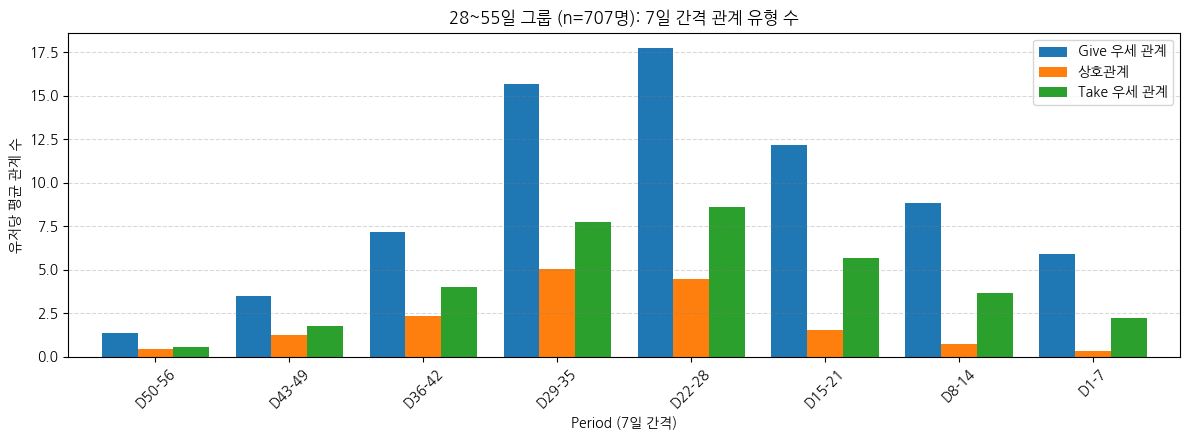

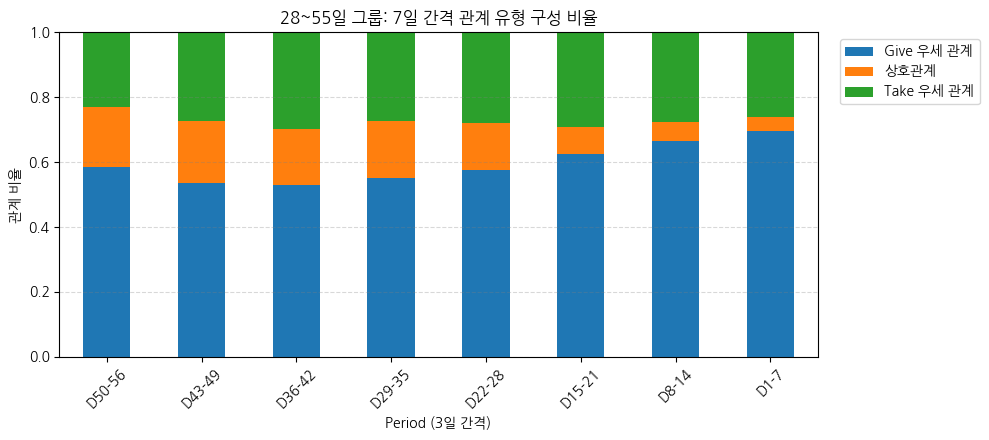

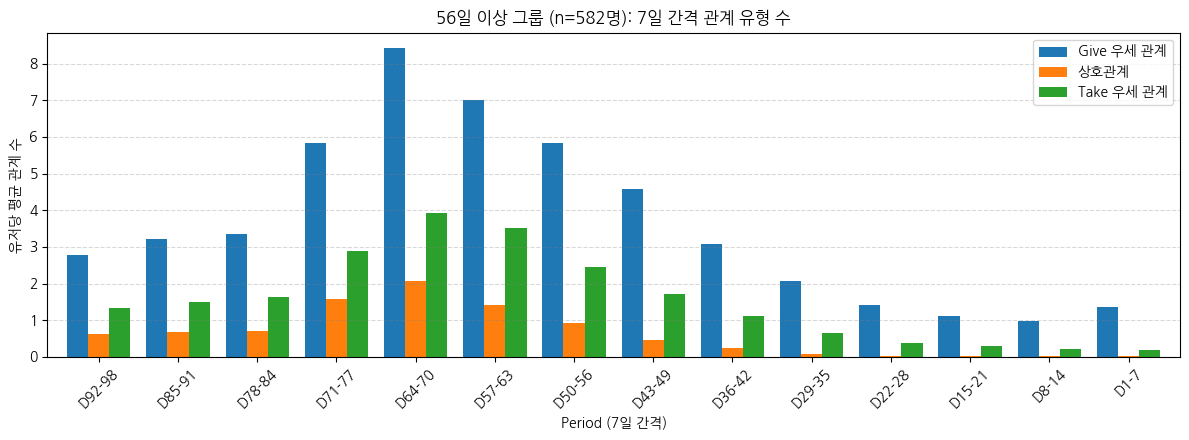

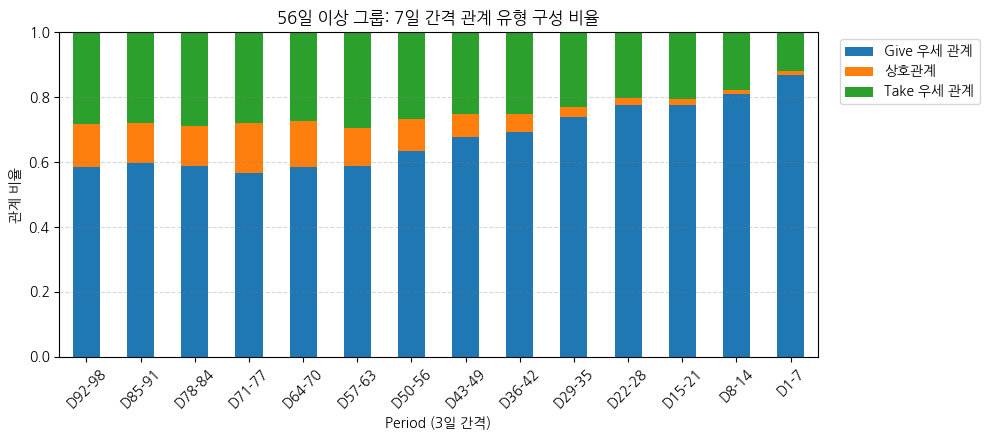

In [159]:
for label in labels:
    cnt = relation_counts(label)
    ratio = cnt.div(cnt.sum(axis=1), axis=0)
    n_users = (target_span['span_group'] == label).sum()

    ax = cnt.plot(kind='bar', figsize=(12, 4.5), width=0.8, rot=45)
    ax.set_title(f'{label} 그룹 (n={n_users:,}명): 7일 간격 관계 유형 수')
    ax.set_xlabel('Period (7일 간격)')
    ax.set_ylabel('유저당 평균 관계 수')
    ax.grid(axis='y', color='gray', linestyle='--', alpha=0.3)
    ax.legend(title=None)
    plt.tight_layout()
    plt.show()

    ax = ratio.plot(kind='bar', stacked=True, figsize=(10, 4.5), rot=45)
    ax.set_title(f'{label} 그룹: 7일 간격 관계 유형 구성 비율')
    ax.set_xlabel('Period (3일 간격)')
    ax.set_ylabel('관계 비율')
    ax.set_ylim(0, 1)
    ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(axis='y', color='gray', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

In [160]:
# 단위: 3일
# 상관분석: 이탈일이 가까워질수록 take_ratio와의 상관관계

def take_ratio_by_period(group_label, size=3):
    """구간별 전체 take / (give+take) 비율 (구간 순서: 위=이탈에서 먼 구간 → 아래=D0)"""
    n_bins = max_days[group_label] // size
    users = target_span[target_span['span_group'] == group_label]
    last_day = users.set_index('user_id')['last_day']

    g = give_df[give_df['user_id'].isin(users['user_id'])].copy()
    g['days_before'] = (g['user_id'].map(last_day) - pd.to_datetime(g['created_at'])).dt.days
    t = take_df[take_df['chosen_user_id'].isin(users['user_id'])].copy()
    t['days_before'] = (t['chosen_user_id'].map(last_day) - pd.to_datetime(t['created_at'])).dt.days

    g = g[(g['days_before'] > 0) & (g['days_before'] <= n_bins * size)]
    t = t[(t['days_before'] > 0) & (t['days_before'] <= n_bins * size)]
    g['period'] = (g['days_before'] - 1) // size
    t['period'] = (t['days_before'] - 1) // size

    give_cnt = g.groupby('period').size().reindex(range(n_bins), fill_value=0)
    take_cnt = t.groupby('period').size().reindex(range(n_bins), fill_value=0)

    ratio = (take_cnt / (give_cnt + take_cnt)).sort_index(ascending=False)
    return ratio

for label in labels:
    ratio = take_ratio_by_period(label, size=3)   # 상관분석은 3일 고정
    order = range(len(ratio))

    corr, p = spearmanr(order, ratio)

    is_sig = '유의함' if p < 0.05 else '유의하지 않음'
    direction = '이탈일이 가까워질수록 올라감' if corr > 0 else '이탈일이 가까워질수록 내려감'

    print(f'{label}: 상관계수 {corr:.3f}, p-value {p:.4f} → {is_sig}, {direction}')
    print(ratio.round(3).values)
    print()

7~13일: 상관계수 1.000, p-value 0.0000 → 유의함, 이탈일이 가까워질수록 올라감
[0.435 0.457 0.491 0.51 ]

14~20일: 상관계수 0.929, p-value 0.0025 → 유의함, 이탈일이 가까워질수록 올라감
[0.423 0.437 0.442 0.441 0.457 0.453 0.485]

21~27일: 상관계수 -0.117, p-value 0.7650 → 유의하지 않음, 이탈일이 가까워질수록 내려감
[0.39  0.439 0.44  0.459 0.431 0.423 0.413 0.427 0.436]

28~55일: 상관계수 -0.728, p-value 0.0006 → 유의함, 이탈일이 가까워질수록 내려감
[0.379 0.372 0.412 0.43  0.419 0.41  0.408 0.389 0.402 0.4   0.392 0.382
 0.364 0.341 0.323 0.335 0.327 0.317]

56일 이상: 상관계수 -0.912, p-value 0.0000 → 유의함, 이탈일이 가까워질수록 내려감
[0.397 0.371 0.425 0.432 0.402 0.435 0.41  0.384 0.421 0.399 0.38  0.415
 0.409 0.386 0.374 0.341 0.347 0.293 0.332 0.302 0.273 0.248 0.228 0.246
 0.231 0.264 0.246 0.181 0.178 0.192 0.138 0.123]



In [161]:
# 단위: 3일
# 상관분석: 이탈일이 가까워질수록 상호관계 비율과의 상관관계

def mutual_ratio_by_period(group_label, size=3):
    """구간별 상호관계 비율 (구간 순서: 위=이탈에서 먼 구간 → 아래=D0)"""
    n_bins = max_days[group_label] // size
    users = target_span[target_span['span_group'] == group_label]
    ids = set(users['user_id'])
    last_day = users.set_index('user_id')['last_day']

    g = give_df[give_df['user_id'].isin(ids)].rename(columns={'user_id': 'me', 'chosen_user_id': 'other'})
    g['give'], g['take'] = 1, 0
    t = take_df[take_df['chosen_user_id'].isin(ids)].rename(columns={'chosen_user_id': 'me', 'user_id': 'other'})
    t['give'], t['take'] = 0, 1

    ev = pd.concat([g, t], ignore_index=True)
    ev = ev[ev['me'] != ev['other']]
    ev['days_before'] = (ev['me'].map(last_day) - pd.to_datetime(ev['created_at'])).dt.days
    ev = ev[(ev['days_before'] > 0) & (ev['days_before'] <= n_bins * size)]
    ev['period'] = (ev['days_before'] - 1) // size

    pair = ev.groupby(['period', 'me', 'other'])[['give', 'take']].sum().reset_index()
    pair['take_ratio'] = pair['take'] / (pair['give'] + pair['take'])
    pair['is_mutual'] = (pair['take_ratio'] > 1/3) & (pair['take_ratio'] < 2/3)

    mutual = pair.groupby('period')['is_mutual'].mean().reindex(range(n_bins), fill_value=0)
    return mutual.sort_index(ascending=False)

for label in labels:
    ratio = mutual_ratio_by_period(label, size=3)   # 상관분석은 3일 고정
    order = range(len(ratio))

    corr, p = spearmanr(order, ratio)

    is_sig = '유의함' if p < 0.05 else '유의하지 않음'
    direction = '이탈일이 가까워질수록 올라감' if corr > 0 else '이탈일이 가까워질수록 내려감'

    print(f'{label}: 상관계수 {corr:.3f}, p-value {p:.4f} → {is_sig}, {direction}')
    print(ratio.round(3).values)
    print()

7~13일: 상관계수 -1.000, p-value 0.0000 → 유의함, 이탈일이 가까워질수록 내려감
[0.159 0.149 0.119 0.077]

14~20일: 상관계수 -0.964, p-value 0.0005 → 유의함, 이탈일이 가까워질수록 내려감
[0.155 0.17  0.147 0.109 0.074 0.05  0.036]

21~27일: 상관계수 -1.000, p-value 0.0000 → 유의함, 이탈일이 가까워질수록 내려감
[0.162 0.158 0.131 0.096 0.07  0.052 0.042 0.033 0.028]

28~55일: 상관계수 -0.938, p-value 0.0000 → 유의함, 이탈일이 가까워질수록 내려감
[0.156 0.123 0.132 0.129 0.106 0.12  0.115 0.121 0.124 0.105 0.076 0.056
 0.046 0.036 0.029 0.029 0.027 0.022]

56일 이상: 상관계수 -0.922, p-value 0.0000 → 유의함, 이탈일이 가까워질수록 내려감
[0.098 0.084 0.087 0.079 0.084 0.09  0.111 0.114 0.103 0.109 0.082 0.077
 0.083 0.082 0.065 0.051 0.044 0.041 0.028 0.035 0.024 0.02  0.018 0.014
 0.009 0.007 0.01  0.009 0.013 0.006 0.003 0.011]



## 추가 EDA

### Q1. 같은 사람에게 몇 번이나 투표하는가?
한 유저가 얕고 넓게 다양한 유저에게 투표하는지, 소수의 주변 유저에게 중복해서 투표를 쏠려서 하는지

In [162]:
result.head()

,user_id,chosen_user_id,created_at
0,849436,849469,2023-04-28
1,849436,849446,2023-04-28
2,849436,849454,2023-04-28
3,849436,847375,2023-04-28
4,849436,849477,2023-04-28


In [163]:
# 10번 이상 투표한 사람만 추출
result_user_cnt = result.groupby('user_id').size().reset_index(name='vote_cnt')
vote_10_and_more = result_user_cnt.loc[result_user_cnt['vote_cnt'] >= 10, 'user_id']
result_10 = result[result['user_id'].isin(vote_10_and_more)]

# 누가 누구에게 몇 번 투표했는지
pair_votes_10 = result_10.groupby(['user_id', 'chosen_user_id']).size().reset_index(name='votes')

display(pair_votes_10.describe())
pair_votes_10.head()

,user_id,chosen_user_id,votes
count,180208.00,180208.00,180208.00
mean,1100305.79,1092148.71,6.73
std,208629.15,205093.67,9.85
min,838023.00,833112.00,1.00
25%,884287.00,884218.00,2.00
50%,1102695.00,1084727.00,4.00
75%,1262226.00,1242668.00,8.00
max,1579418.00,1579422.00,887.00


,user_id,chosen_user_id,votes
0,838023,845238,1
1,838023,850601,3
2,838023,854596,2
3,838023,854615,1
4,838023,855117,2


In [164]:
# 투표 횟수에 라벨 붙이기 (20번 이상은 하나로 묶음)
def label_votes(v):
    if v >= 20:
        return '20번 이상'
    return f'{v}번'

pair_votes_10['votes_label'] = pair_votes_10['votes'].apply(label_votes)

order = [f'{i}번' for i in range(1, 20)] + ['20번 이상']
vote_dist_10 = pair_votes_10['votes_label'].value_counts().reindex(order).reset_index(drop=False)
vote_dist_10['비율(%)'] = vote_dist_10['count'] / vote_dist_10['count'].sum()*100

vote_dist_10

,votes_label,count,비율(%)
0,1번,42358,23.51
1,2번,26666,14.80
2,3번,19434,10.78
3,4번,14740,8.18
4,5번,11780,6.54
5,6번,9212,5.11
6,7번,7648,4.24
7,8번,6147,3.41
8,9번,5319,2.95
9,10번,4414,2.45


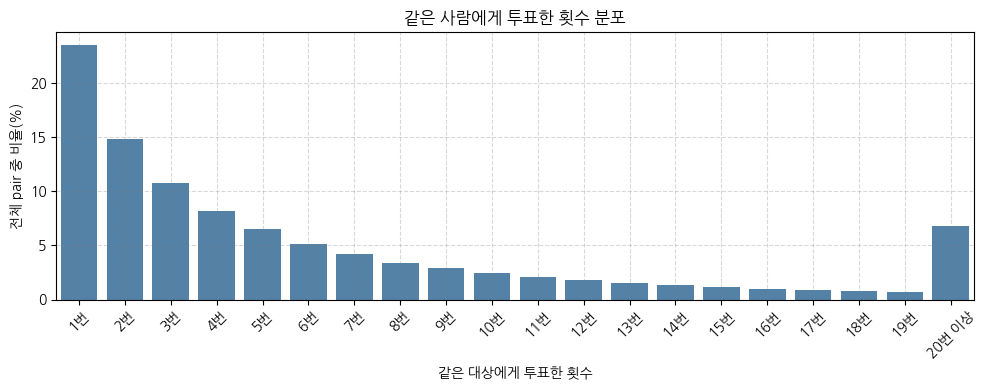

In [165]:
plt.figure(figsize=(10, 4))
sns.barplot(data=vote_dist_10, x='votes_label', y='비율(%)', color='steelblue', order=order)

plt.title('같은 사람에게 투표한 횟수 분포')
plt.xlabel('같은 대상에게 투표한 횟수')
plt.ylabel('전체 pair 중 비율(%)')
plt.xticks(rotation=45)
plt.grid(color='gray', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [166]:
# 20번 이상 투표한 사람만 추출
result_user_cnt = result.groupby('user_id').size().reset_index(name='vote_cnt')
vote_20_and_more = result_user_cnt.loc[result_user_cnt['vote_cnt'] >= 20, 'user_id']
result_20 = result[result['user_id'].isin(vote_20_and_more)]

# 누가 누구에게 몇 번 투표했는지
pair_votes_20 = result_20.groupby(['user_id', 'chosen_user_id']).size().reset_index(name='votes')

display(pair_votes_20.describe())
pair_votes_20.head()

,user_id,chosen_user_id,votes
count,179277.00,179277.00,179277.00
mean,1100003.78,1092281.16,6.76
std,208315.51,205043.46,9.87
min,838023.00,833112.00,1.00
25%,884238.00,884238.00,2.00
50%,1102560.00,1085098.00,4.00
75%,1261250.00,1242882.00,8.00
max,1579418.00,1579422.00,887.00


,user_id,chosen_user_id,votes
0,838023,845238,1
1,838023,850601,3
2,838023,854596,2
3,838023,854615,1
4,838023,855117,2


In [167]:
# 투표 횟수에 라벨 붙이기 (20번 이상은 하나로 묶음)
def label_votes(v):
    if v >= 20:
        return '20번 이상'
    return f'{v}번'

pair_votes_20['votes_label'] = pair_votes_20['votes'].apply(label_votes)

order = [f'{i}번' for i in range(1, 20)] + ['20번 이상']
vote_dist_20 = pair_votes_20['votes_label'].value_counts().reindex(order).reset_index(drop=False)
vote_dist_20['비율(%)'] = vote_dist_20['count'] / vote_dist_20['count'].sum()*100

vote_dist_20

,votes_label,count,비율(%)
0,1번,41801,23.32
1,2번,26447,14.75
2,3번,19352,10.79
3,4번,14702,8.20
4,5번,11758,6.56
5,6번,9206,5.14
6,7번,7643,4.26
7,8번,6147,3.43
8,9번,5319,2.97
9,10번,4414,2.46


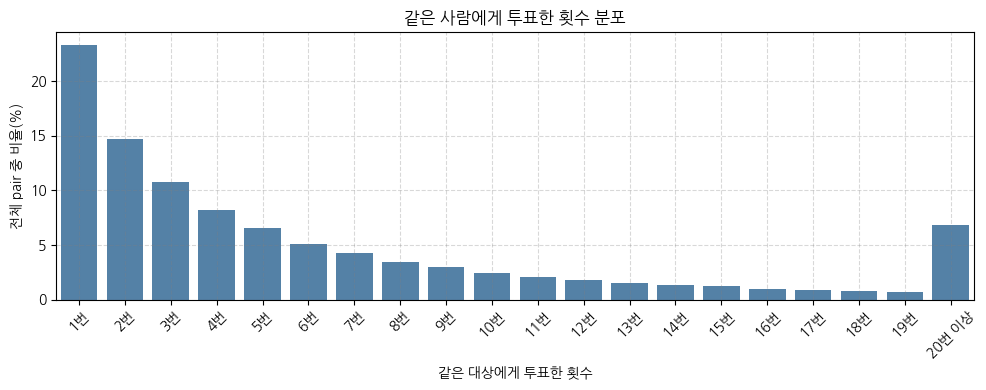

In [168]:
plt.figure(figsize=(10, 4))
sns.barplot(data=vote_dist_20, x='votes_label', y='비율(%)', color='steelblue', order=order)

plt.title('같은 사람에게 투표한 횟수 분포')
plt.xlabel('같은 대상에게 투표한 횟수')
plt.ylabel('전체 pair 중 비율(%)')
plt.xticks(rotation=45)
plt.grid(color='gray', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [169]:
order = ['1번', '2번', '3번', '4번', '5번 이상']
pair_sets = {
    '10번 이상': pair_votes_10,
    '20번 이상': pair_votes_20,
}

def bucket(v):
    return np.where(v >= 5, '5번 이상', v.astype(str) + '번')

def pair_counts(pv):
    p = pv.copy()
    p['bucket'] = bucket(p['votes'])
    return p['bucket'].value_counts().reindex(order, fill_value=0)

vote_counts = pd.DataFrame(
    {name: pair_counts(pv) for name, pv in pair_sets.items()}
).T
vote_counts.index.name = '유저 필터'
vote_counts

bucket,1번,2번,3번,4번,5번 이상
유저 필터,,,,,
10번 이상,42358,26666,19434,14740,77010
20번 이상,41801,26447,19352,14702,76975


### Q2. 친구 등록되지 않은 유저에게 투표하는 비율


In [170]:
result.head()

,user_id,chosen_user_id,created_at
0,849436,849469,2023-04-28
1,849436,849446,2023-04-28
2,849436,849454,2023-04-28
3,849436,847375,2023-04-28
4,849436,849477,2023-04-28


In [171]:
# 1) A->B 투표 횟수 집계 (이걸 먼저!)
votes_pairs = result.groupby(['user_id', 'chosen_user_id']).size().reset_index(name='votes')

# 2) 친구 목록 읽기 — 필요한 두 컬럼만
friend_raw = pd.read_csv(
    '/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv/accounts_user.csv',
    usecols=['id', 'friend_id_list']
)

# 3) 투표한 유저의 친구 목록만 남기기  <- 핵심
voters = votes_pairs['user_id'].unique()
friend_raw = friend_raw[friend_raw['id'].isin(voters)].copy()

# 4) 문자열을 리스트로 바꾸기
friend_raw['friend_id_list'] = friend_raw['friend_id_list'].fillna('[]')
friend_raw['friend_id_list'] = friend_raw['friend_id_list'].apply(ast.literal_eval)

# 5) explode로 친구 한 명씩 한 줄로 풀기
friend_edges = friend_raw.explode('friend_id_list')
friend_edges = friend_edges.dropna()

# 6) 컬럼 이름 맞추고 친구 표시 1 붙이기
friend_edges.columns = ['user_id', 'chosen_user_id']
friend_edges['chosen_user_id'] = friend_edges['chosen_user_id'].astype(int)
friend_edges = friend_edges.drop_duplicates()
friend_edges['is_friend'] = 1

# 7) 친구 여부 붙이기 (없으면 0)
votes_pairs = votes_pairs.merge(friend_edges, on=['user_id', 'chosen_user_id'], how='left')
votes_pairs['is_friend'] = votes_pairs['is_friend'].fillna(0).astype(int)

votes_pairs.head()

,user_id,chosen_user_id,votes,is_friend
0,838023,845238,1,1
1,838023,850601,3,1
2,838023,854596,2,1
3,838023,854615,1,1
4,838023,855117,2,1


In [172]:
summary = votes_pairs.groupby('is_friend').agg(관계수=('votes','size'), 투표수=('votes','sum'))
summary['관계비율(%)'] = (summary['관계수'] / summary['관계수'].sum() * 100).round(1)
summary['투표비율(%)'] = (summary['투표수'] / summary['투표수'].sum() * 100).round(1)
summary

,관계수,투표수,관계비율(%),투표비율(%)
is_friend,,,,
0,2662,9388,1.50,0.80
1,178092,1204538,98.50,99.20


### Q3. 연락처 등록되지 않은 유저에게 투표하는 비율

In [173]:
open_csv('accounts_user_contacts').head()

,id,contacts_count,invite_user_id_list,user_id
0,259,30,[],1167696
1,1756,79,[],863169
2,13742,21,[854615],857205
3,13754,29,[],851431
4,13756,28,[849318],855476


### Q4. 다른 학교의 유저에게 투표하는 비율

In [174]:
user_group = open_csv('accounts_user')[['id', 'group_id']]
groups = open_csv('accounts_group')

In [175]:
user_school = (
    pd.merge(user_group, groups, left_on='group_id', right_on='id', how='inner')
    .rename(columns={'id_x': 'user_id'})
    .drop(columns=['id_y'])
)

print(f'accounts_user 유니크 유저 수(전처리 전): {len(user_group):,}')
print(f'accounts_group 와 결합 후 유니크 유저 수(전처리 전): {len(user_school):,}')
print(f'합치기 전 후 차이: {len(user_group) - len(user_school)}')

accounts_user 유니크 유저 수(전처리 전): 677,085
accounts_group 와 결합 후 유니크 유저 수(전처리 전): 677,082
합치기 전 후 차이: 3


In [176]:
user_school

,user_id,group_id,grade,class_num,school_id
0,831962,12.00,2,1,1
1,832151,1.00,1,1,1
2,832340,1.00,1,1,1
3,832520,12.00,2,1,1
4,832614,12.00,2,1,1
...,...,...,...,...,...
677077,1583729,32442.00,3,2,2389
677078,1583730,43949.00,3,7,2969
677079,1583731,18640.00,3,1,2579
677080,1583732,18640.00,3,1,2579


In [177]:
# 1) user_id -> school_id 조회용
school_map = (
    user_school[['user_id', 'school_id']]
    .set_index('user_id')['school_id']
)

# 2) 양쪽 학교 붙이기
votes_pairs['school_a'] = votes_pairs['user_id'].map(school_map)
votes_pairs['school_b'] = votes_pairs['chosen_user_id'].map(school_map)

# 3) 같은 학교 여부
votes_pairs['is_same_school'] = np.select(
    [votes_pairs['school_a'].isna() | votes_pairs['school_b'].isna(),
     votes_pairs['school_a'] == votes_pairs['school_b']],
    ['학교 정보 없음', '같은 학교'],
    default='다른 학교'
)

votes_pairs.head()

,user_id,chosen_user_id,votes,is_friend,school_a,school_b,is_same_school
0,838023,845238,1,1,271,271,같은 학교
1,838023,850601,3,1,271,271,같은 학교
2,838023,854596,2,1,271,271,같은 학교
3,838023,854615,1,1,271,271,같은 학교
4,838023,855117,2,1,271,271,같은 학교


In [178]:
summary = votes_pairs.groupby('is_same_school').agg(페어수=('votes','size'), 투표수=('votes','sum'))
summary['페어비율(%)'] = (summary['페어수'] / summary['페어수'].sum() * 100).round(1)
summary['투표비율(%)'] = (summary['투표수'] / summary['투표수'].sum() * 100).round(1)
summary

,페어수,투표수,페어비율(%),투표비율(%)
is_same_school,,,,
같은 학교,151952,1045768,84.10,86.10
다른 학교,28802,168158,15.90,13.90


In [179]:
# 중학교, 고등학교로 나누어 확인
accounts_school = open_csv('accounts_school')
accounts_school.head()

,id,address,student_count,school_type
0,4,충청북도 충주시,239,H
1,5,충청북도 충주시,160,M
2,6,충청북도 충주시,200,H
3,7,충청북도 충주시,114,H
4,8,충청북도 충주시,139,M


In [180]:
# 1) school_id -> school_type(H/M) 매핑
school_type_map = accounts_school.set_index('id')['school_type']
votes_pairs['school_type_a'] = votes_pairs['school_a'].map(school_type_map)

# 2) 학교 정보가 있는 페어만 (같은 학교/다른 학교 비교이므로 '정보 없음'은 제외)
known = votes_pairs[votes_pairs['is_same_school'] != '학교 정보 없음']

# 3) 투표한 사람(A)의 학교 유형별로 같은 학교/다른 학교 비율 요약
summary = (
    known.groupby(['school_type_a', 'is_same_school'])
    .agg(페어수=('votes', 'size'), 투표수=('votes', 'sum'))
)
summary['페어비율(%)'] = (
    summary['페어수'] / summary.groupby(level='school_type_a')['페어수'].transform('sum') * 100
).round(2)
summary['투표비율(%)'] = (
    summary['투표수'] / summary.groupby(level='school_type_a')['투표수'].transform('sum') * 100
).round(2)

summary

페어수     투표수  페어비율(%)  투표비율(%)
school_type_a is_same_school                                  
H             같은 학교           116060  797822    81.51    83.71
              다른 학교            26330  155258    18.49    16.29
M             같은 학교            35892  247946    93.56    95.05
              다른 학교             2472   12900     6.44     4.95

### Q5. 같은 학교에서 다른반 친구에게 투표하는 비중

In [181]:
def school_map(col):
    return (user_school[['user_id', col]]
            .drop_duplicates(subset='user_id')
            .set_index('user_id')[col])

# grade, class_num 양쪽 붙이기
for col, short in [('grade', 'grade'), ('class_num', 'class')]:
    votes_pairs[f'{short}_a'] = votes_pairs['user_id'].map(school_map(col))
    votes_pairs[f'{short}_b'] = votes_pairs['chosen_user_id'].map(school_map(col))

# 라벨
same_school = votes_pairs['is_same_school'] == '같은 학교'
no_info = votes_pairs['grade_a'].isna() | votes_pairs['grade_b'].isna()

votes_pairs['is_same_grade'] = np.select(
    [no_info, votes_pairs['grade_a'] == votes_pairs['grade_b']],
    ['정보 없음', '같은 학년'], default='다른 학년')

votes_pairs['is_same_class'] = np.select(
    [no_info, ~same_school,
     (votes_pairs['class_a'] == votes_pairs['class_b']) &
     (votes_pairs['grade_a'] == votes_pairs['grade_b'])],
    ['정보 없음', '다른 학교', '같은 반'], default='다른 반')

votes_pairs.head()

,user_id,chosen_user_id,votes,is_friend,school_a,school_b,is_same_school,school_type_a,grade_a,grade_b,class_a,class_b,is_same_grade,is_same_class
0,838023,845238,1,1,271,271,같은 학교,H,1,1,12,12,같은 학년,같은 반
1,838023,850601,3,1,271,271,같은 학교,H,1,1,12,12,같은 학년,같은 반
2,838023,854596,2,1,271,271,같은 학교,H,1,1,12,14,같은 학년,다른 반
3,838023,854615,1,1,271,271,같은 학교,H,1,1,12,12,같은 학년,같은 반
4,838023,855117,2,1,271,271,같은 학교,H,1,1,12,12,같은 학년,같은 반


In [182]:
summary = votes_pairs.groupby('is_same_class').agg(페어수=('votes','size'), 투표수=('votes','sum'))
summary['페어비율(%)'] = (summary['페어수'] / summary['페어수'].sum() * 100).round(1)
summary['투표비율(%)'] = (summary['투표수'] / summary['투표수'].sum() * 100).round(1)
summary

,페어수,투표수,페어비율(%),투표비율(%)
is_same_class,,,,
같은 반,47100,371542,26.10,30.60
다른 반,104852,674226,58.00,55.50
다른 학교,28802,168158,15.90,13.90


In [183]:
# 중학교, 고등학교로 나누어 확인
# school_id -> school_type(H/M) 매핑 (이미 추가하셨다면 재실행해도 안전)
school_type_map = accounts_school.set_index('id')['school_type']
votes_pairs['school_type_a'] = votes_pairs['school_a'].map(school_type_map)

# 학교 유형을 모르는 페어는 제외 (H/M으로 나눌 수 없으므로)
known = votes_pairs[votes_pairs['school_type_a'].notna()]

summary = (
    known.groupby(['school_type_a', 'is_same_class'])
    .agg(페어수=('votes', 'size'), 투표수=('votes', 'sum'))
)
summary['페어비율(%)'] = (
    summary['페어수'] / summary.groupby(level='school_type_a')['페어수'].transform('sum') * 100
).round(1)
summary['투표비율(%)'] = (
    summary['투표수'] / summary.groupby(level='school_type_a')['투표수'].transform('sum') * 100
).round(1)

summary

페어수     투표수  페어비율(%)  투표비율(%)
school_type_a is_same_class                                 
H             같은 반           38601  304093    27.10    31.90
              다른 반           77459  493729    54.40    51.80
              다른 학교          26330  155258    18.50    16.30
M             같은 반            8499   67449    22.20    25.90
              다른 반           27393  180497    71.40    69.20
              다른 학교           2472   12900     6.40     4.90

### Q6. 같은 학교에서 다른학년 친구에게 투표하는 비율

In [184]:
same_school = votes_pairs[votes_pairs['is_same_school'] == '같은 학교']

grade_summary = same_school.groupby('is_same_grade').agg(페어수=('votes','size'), 투표수=('votes','sum'))
grade_summary['페어비율(%)'] = (grade_summary['페어수'] / grade_summary['페어수'].sum() * 100).round(1)
grade_summary['투표비율(%)'] = (grade_summary['투표수'] / grade_summary['투표수'].sum() * 100).round(1)

grade_summary

,페어수,투표수,페어비율(%),투표비율(%)
is_same_grade,,,,
같은 학년,148793,1028939,97.90,98.40
다른 학년,3159,16829,2.10,1.60


In [185]:
school_type_map = accounts_school.set_index('id')['school_type']
same_school = same_school.copy()
same_school['school_type_a'] = same_school['school_a'].map(school_type_map)

known = same_school[same_school['school_type_a'].notna()]

grade_by_type = (
    known.groupby(['school_type_a', 'is_same_grade'])
    .agg(페어수=('votes', 'size'), 투표수=('votes', 'sum'))
)
grade_by_type['페어비율(%)'] = (
    grade_by_type['페어수'] / grade_by_type.groupby(level='school_type_a')['페어수'].transform('sum') * 100
).round(1)
grade_by_type['투표비율(%)'] = (
    grade_by_type['투표수'] / grade_by_type.groupby(level='school_type_a')['투표수'].transform('sum') * 100
).round(1)

grade_by_type

페어수     투표수  페어비율(%)  투표비율(%)
school_type_a is_same_grade                                  
H             같은 학년          113388  783592    97.70    98.20
              다른 학년            2672   14230     2.30     1.80
M             같은 학년           35405  245347    98.60    99.00
              다른 학년             487    2599     1.40     1.00

### Q7. 첫 투표 후 며칠 안에 give or take 피크 찍는지 확인

In [186]:
def peak_by_group(df, user_col):
    """df: give_df 또는 take_df / user_col: 'user_id'(give) 또는 'chosen_user_id'(take)"""
    d = df[[user_col, 'created_at']].rename(columns={user_col: 'user_id'})
    d['created_at'] = pd.to_datetime(d['created_at'])          # date -> datetime64 변환 (핵심)

    daily = d.groupby(['user_id', 'created_at']).size().reset_index(name='cnt')
    daily = daily.merge(target_span[['user_id', 'first_day']], on='user_id')
    daily['day_since_start'] = (daily['created_at'] - daily['first_day']).dt.days

    peak = (
        daily.sort_values(['user_id', 'day_since_start'])
        .loc[daily.groupby('user_id')['cnt'].idxmax()]
        [['user_id', 'day_since_start', 'cnt']]
        .rename(columns={'day_since_start': 'peak_day', 'cnt': 'peak_cnt'})
        .merge(target_span[['user_id', 'span_group']], on='user_id')
    )

    return (
        peak.groupby('span_group', observed=True)
        .agg(유저수=('user_id', 'size'), 평균피크일=('peak_day', 'mean'), 중앙값=('peak_day', 'median'))
        .reindex(labels)
        .round(1)
    )

give_peak_summary = peak_by_group(give_df, 'user_id')
take_peak_summary = peak_by_group(take_df, 'chosen_user_id')

print("=== Give 피크일 (그룹별) ===")
display(give_peak_summary)
print("=== Take 피크일 (그룹별) ===")
display(take_peak_summary)

=== Give 피크일 (그룹별) ===


,유저수,평균피크일,중앙값
span_group,,,
7~13일,1106,1.80,1.00
14~20일,827,2.10,1.00
21~27일,579,2.60,1.00
28~55일,707,2.90,2.00
56일 이상,582,3.60,1.00


=== Take 피크일 (그룹별) ===


,유저수,평균피크일,중앙값
span_group,,,
7~13일,1103,1.50,1.00
14~20일,825,2.00,1.00
21~27일,578,2.10,1.00
28~55일,706,2.00,1.00
56일 이상,580,2.50,1.00


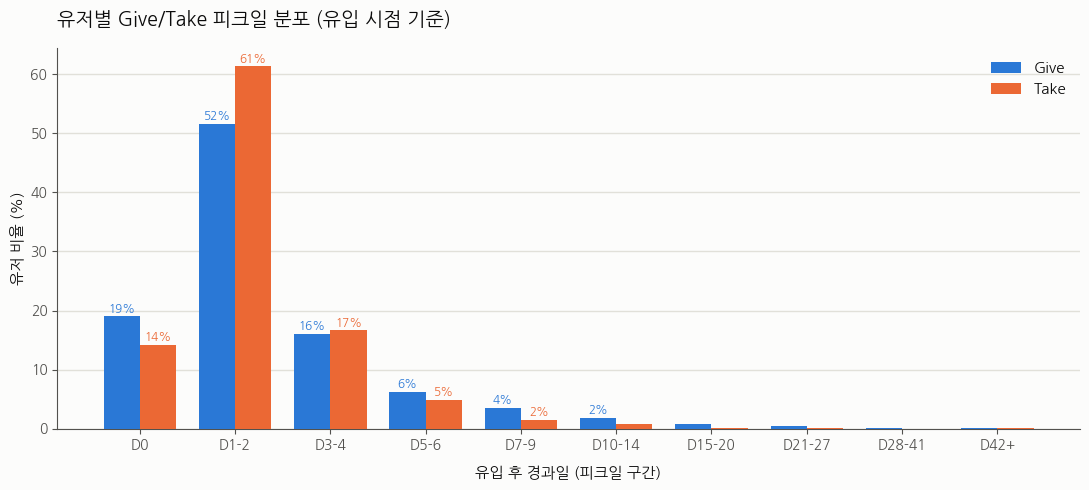

In [187]:
def get_peak_days(df, user_col):
    """유저별 피크일(day_since_start)만 뽑아내는 함수"""
    d = df[[user_col, 'created_at']].rename(columns={user_col: 'user_id'})
    d['created_at'] = pd.to_datetime(d['created_at'])
    daily = d.groupby(['user_id', 'created_at']).size().reset_index(name='cnt')
    daily = daily.merge(target_span[['user_id', 'first_day']], on='user_id')
    daily['day_since_start'] = (daily['created_at'] - daily['first_day']).dt.days
    return (
        daily.sort_values(['user_id', 'day_since_start'])
        .loc[daily.groupby('user_id')['cnt'].idxmax()]
        [['user_id', 'day_since_start']]
        .rename(columns={'day_since_start': 'peak_day'})
    )

give_peak = get_peak_days(give_df, 'user_id')
take_peak = get_peak_days(take_df, 'chosen_user_id')

# 구간 나누기
bins = [-1, 0, 2, 4, 6, 9, 14, 20, 27, 41, np.inf]
bin_labels = ['D0','D1-2','D3-4','D5-6','D7-9','D10-14','D15-20','D21-27','D28-41','D42+']

def dist(peak):
    b = pd.cut(peak['peak_day'], bins=bins, labels=bin_labels)
    return b.value_counts(normalize=True).reindex(bin_labels).fillna(0) * 100

give_dist = dist(give_peak)
take_dist = dist(take_peak)

# 시각화
INK, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e1e0d9', '#fcfcfb'
C_GIVE, C_TAKE = '#2a78d6', '#eb6834'

fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

x = np.arange(len(bin_labels))
w = 0.38
b1 = ax.bar(x - w/2, give_dist.values, width=w, color=C_GIVE, label='Give', zorder=3)
b2 = ax.bar(x + w/2, take_dist.values, width=w, color=C_TAKE, label='Take', zorder=3)

for bars, color in [(b1, C_GIVE), (b2, C_TAKE)]:
    for rect in bars:
        h = rect.get_height()
        if h >= 1:
            ax.text(rect.get_x()+rect.get_width()/2, h+0.6, f'{h:.0f}%',
                    ha='center', fontsize=8.5, color=color, fontweight='bold')

ax.set_xticks(x); ax.set_xticklabels(bin_labels, fontsize=10, color=INK)
ax.set_ylabel('유저 비율 (%)', fontsize=11, color=INK)
ax.set_xlabel('유입 후 경과일 (피크일 구간)', fontsize=11, color=INK, labelpad=10)
ax.set_title('유저별 Give/Take 피크일 분포 (유입 시점 기준)', fontsize=14, color=INK, pad=16, loc='left')

ax.grid(axis='y', color=GRID, linewidth=1, zorder=0)
ax.set_axisbelow(True)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
for sp in ('left', 'bottom'):
    ax.spines[sp].set_color(MUTED)
ax.tick_params(colors=MUTED)
ax.legend(loc='upper right', frameon=False, fontsize=11, labelcolor=INK)

plt.tight_layout()
plt.show()

### Q8. 서로 투표를 주고 받은 경험이 있는 유저들이 일방적으로 투표를 주기만 한 유저들에 비해 핵심행동 유지율이 높은지

In [188]:
from scipy.stats import mannwhitneyu

# ---- 1) 페어 단위 상호 투표 여부 ----
pair_first = (result.groupby(['user_id', 'chosen_user_id'])['created_at']
              .min().reset_index().rename(columns={'created_at': 'first_vote_date'}))
pair_first['pair_key'] = pair_first.apply(
    lambda r: tuple(sorted([r['user_id'], r['chosen_user_id']])), axis=1)

merged = pair_first.merge(pair_first, on='pair_key', suffixes=('_1', '_2'))
recip = merged[
    (merged['user_id_1'] == merged['chosen_user_id_2']) &
    (merged['chosen_user_id_1'] == merged['user_id_2']) &
    (merged['user_id_1'] < merged['chosen_user_id_1'])  # 대칭 중복 제거
]
reciprocal_users = set(recip['user_id_1']) | set(recip['chosen_user_id_1'])
all_voters = set(result['user_id'].unique())
non_reciprocal_users = all_voters - reciprocal_users

# ---- 2) 유저별 친구요청 횟수 / 투표 완료 수 ----
fr_count = accounts_friendrequest.groupby('send_user_id').size()
vote_count = result.groupby('user_id').size()

group_df = pd.DataFrame({'user_id': list(all_voters)})
group_df['group'] = group_df['user_id'].apply(lambda u: '상호' if u in reciprocal_users else '비상호')
group_df['friend_request_cnt'] = group_df['user_id'].map(fr_count).fillna(0)
group_df['vote_cnt'] = group_df['user_id'].map(vote_count).fillna(0)

# ---- 3) 그룹별 요약 ----
summary = group_df.groupby('group').agg(
    유저수=('user_id', 'size'),
    평균_친구요청=('friend_request_cnt', 'mean'),
    중앙값_친구요청=('friend_request_cnt', 'median'),
    평균_투표=('vote_cnt', 'mean'),
    중앙값_투표=('vote_cnt', 'median'),
).round(2)
display(summary)

# ---- 4) 유의성 검정 (분포 치우침 고려해 비모수 검정) ----
g1_fr = group_df.loc[group_df['group'] == '상호', 'friend_request_cnt']
g2_fr = group_df.loc[group_df['group'] == '비상호', 'friend_request_cnt']
_, p_fr = mannwhitneyu(g1_fr, g2_fr, alternative='two-sided')

g1_vote = group_df.loc[group_df['group'] == '상호', 'vote_cnt']
g2_vote = group_df.loc[group_df['group'] == '비상호', 'vote_cnt']
_, p_vote = mannwhitneyu(g1_vote, g2_vote, alternative='two-sided')

print(f'친구요청 횟수 차이 p-value: {p_vote:.4f}' if False else f'친구요청 p-value: {p_fr:.4f}')
print(f'투표 완료 수 p-value: {p_vote:.4f}')

,유저수,평균_친구요청,중앙값_친구요청,평균_투표,중앙값_투표
group,,,,,
비상호,59,17.69,15.00,28.51,7.00
상호,4790,28.45,23.00,253.08,191.00


친구요청 p-value: 0.0000
투표 완료 수 p-value: 0.0000


In [189]:
from scipy.stats import fisher_exact

# ---- 0) dtype 수정: date(object) -> datetime64 ----
result['created_at'] = pd.to_datetime(result['created_at'])

# ---- 1) 그룹 나누기 (상호/비상호) — 이전 코드 그대로 재사용 ----
pair_first = (result.groupby(['user_id', 'chosen_user_id'])['created_at']
              .min().reset_index().rename(columns={'created_at': 'first_vote_date'}))
pair_first['pair_key'] = pair_first.apply(
    lambda r: tuple(sorted([r['user_id'], r['chosen_user_id']])), axis=1)

merged = pair_first.merge(pair_first, on='pair_key', suffixes=('_1', '_2'))
recip = merged[
    (merged['user_id_1'] == merged['chosen_user_id_2']) &
    (merged['chosen_user_id_1'] == merged['user_id_2']) &
    (merged['user_id_1'] < merged['chosen_user_id_1'])
]
reciprocal_users = set(recip['user_id_1']) | set(recip['chosen_user_id_1'])
all_voters = set(result['user_id'].unique())
non_reciprocal_users = all_voters - reciprocal_users

# ---- 2) D0 = 첫 투표일 (두 그룹 동일 기준) ----
first_vote_date = result.groupby('user_id')['created_at'].min()

group_df = pd.DataFrame({'user_id': list(all_voters)})
group_df['group'] = group_df['user_id'].apply(lambda u: '상호' if u in reciprocal_users else '비상호')
group_df['day0'] = group_df['user_id'].map(first_vote_date)

# ---- 3) D0 이후 day_diff 계산 (모든 투표 기록 기준) ----
act = result.merge(group_df[['user_id', 'day0', 'group']], on='user_id')
act['day_diff'] = (act['created_at'] - act['day0']).dt.days

# ---- 4) D-day별 유지율 (그날 다시 투표했는가) ----
days = [1, 3, 7, 15, 30]
rows = []
for d in days:
    active_users = set(act.loc[act['day_diff'] == d, 'user_id'])
    g = group_df.copy()
    g['active'] = g['user_id'].isin(active_users).astype(int)
    gg = g.groupby('group')['active'].agg(['sum', 'count'])
    a1, t1 = gg.loc['상호', 'sum'], gg.loc['상호', 'count']
    a2, t2 = gg.loc['비상호', 'sum'], gg.loc['비상호', 'count']
    _, p = fisher_exact([[a1, t1 - a1], [a2, t2 - a2]])
    rows.append({'D-day': f'D{d}',
                 '상호(%)': round(a1 / t1 * 100, 1),
                 '비상호(%)': round(a2 / t2 * 100, 1),
                 'p-value': round(p, 4)})

retention_tbl = pd.DataFrame(rows)
display(retention_tbl)

/tmp/ipykernel_48744/303512436.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result['created_at'] = pd.to_datetime(result['created_at'])


,D-day,상호(%),비상호(%),p-value
0,D1,91.50,28.80,0.00
1,D3,81.00,18.60,0.00
2,D7,51.90,8.50,0.00
3,D15,19.50,5.10,0.00
4,D30,4.90,0.00,0.12


## 변수 초기화

In [190]:
# # 메모리 부족 방지 및 변수 초기화 (재현성 유지)
# %reset -f